# BraTS 2020 - full-cohort run, Phases 1-9

Same code as `training.before_phase1_8_fix.ipynb`, retargeted from the
8-patient representative subset to **all 369 training patients**.

## What changed

| Phase | Subset notebook | This notebook |
|---|---|---|
| 1 | first patient inspected | unchanged |
| 2 | already cohort-wide (369 patients) | unchanged |
| 3 | one representative patient, in depth | unchanged - this phase *is* the single-patient deep dive; its cohort counterpart is Phase 4 |
| 4 | 8 sampled patients | **all 369**; pooled samples/patient 50,000 -> 4,000 to keep RAM flat; background dominance reuses Cell 2's `zero_proportion` instead of a second full read |
| 5 | 8 patients -> 32 feature rows | **all 369 -> 1,476 feature rows** |
| 6 | cohort references from 32 rows | **cohort references from 1,476 rows** |
| 7 | 32 volumes executed + validated | **1,476 volumes executed + validated** |
| 8 | splits/metadata already cohort-wide | unchanged |
| 9 | `cohort_fraction = 0.5` | **`cohort_fraction = 1.0`** |

Per-patient line charts now use a numeric x axis with thinned labels - 369
categorical ticks are illegible. Two exact duplicate cells were dropped.

## Runtime and disk

Phases 1-8 read every volume several times, so budget roughly:

| Phase | Cost |
|---|---|
| 1-3 | seconds to ~2 min |
| 4 | ~5-10 min (1,476 volume reads) |
| 5 | ~10-15 min (1,476 volume reads) |
| 6 | seconds (table only) |
| 7 | ~30-60 min - slowest cell; CLAHE over 155 slices x 1,476 volumes |
| 8 | ~1 min (training stays off; `TRAIN_SELECTED_MODEL = False`) |
| 9 | ~5 min one-off slice cache, then 30 epochs x 4 models on GPU |

Phase 9 writes a **~6.6 GB** slice cache to
`results/cache/phase9_f1_all_128/` and its checkpoints to
`results/checkpoints/phase9/notebook_4class_full/`, so nothing from the
half-cohort run is overwritten.

**Run order matters.** Phases 4-8 reuse `selected_patients`,
`image_quality_features_df` and `adaptive_preprocessing_selection_df` built by
earlier cells. Run top to bottom; Phase 9 is self-contained and can be run
alone after a kernel restart.

For a fast end-to-end check first, set `PHASE7_MAX_ROWS = 64` in Phase 7
Cell 1 and `MAX_SLICES_PER_SPLIT = 2000` in Phase 9 Cell 1, then clear both
for the real run.


In [72]:
# Phase 1 — Cell 1: Imports

import os
import glob
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import nibabel as nib
import cv2

In [73]:
# Phase 1 — Cell 2: Dataset path configuration

# BraTS 2020 training data root (relative to the project folder)
DATASET_PATH = os.path.join(
    "data",
    "raw",
    "BraTS2020",
    "MICCAI_BraTS2020_TrainingData",
)

print(f"DATASET_PATH: {DATASET_PATH}")
print(f"Exists: {os.path.isdir(DATASET_PATH)}")

DATASET_PATH: data\raw\BraTS2020\MICCAI_BraTS2020_TrainingData
Exists: True


In [74]:
# Phase 1 — Cell 3: Patient-folder discovery

# Each BraTS patient is a folder named like BraTS20_Training_001
patient_folders = sorted(
    [
        os.path.join(DATASET_PATH, name)
        for name in os.listdir(DATASET_PATH)
        if os.path.isdir(os.path.join(DATASET_PATH, name))
        and name.startswith("BraTS20_Training_")
    ]
)

print(f"Total patients found: {len(patient_folders)}")
if len(patient_folders) > 0:
    print(f"Example patient folder: {os.path.basename(patient_folders[0])}")

Total patients found: 369
Example patient folder: BraTS20_Training_001


In [75]:
# Phase 1 — Cell 4: Select and verify the first patient

first_patient = patient_folders[0]
first_patient_id = os.path.basename(first_patient)

print(f"Selected patient ID : {first_patient_id}")
print(f"Selected patient path: {first_patient}")
print("Files inside first patient folder:")
for fname in sorted(os.listdir(first_patient)):
    print(f"  - {fname}")

Selected patient ID : BraTS20_Training_001
Selected patient path: data\raw\BraTS2020\MICCAI_BraTS2020_TrainingData\BraTS20_Training_001
Files inside first patient folder:
  - BraTS20_Training_001_flair.nii
  - BraTS20_Training_001_seg.nii
  - BraTS20_Training_001_t1.nii
  - BraTS20_Training_001_t1ce.nii
  - BraTS20_Training_001_t2.nii


In [76]:
# Phase 1 — Cell 5: Resolve the actual NIfTI filenames

MODALITY_KEYS = {
    "FLAIR": "flair",
    "T1": "t1",
    "T1CE": "t1ce",
    "T2": "t2",
    "SEG": "seg",
}


def resolve_nifti_path(patient_dir, modality_key):
    """
    Resolve BraTS NIfTI path for a modality.

    Expected pattern examples:
      BraTS20_Training_001_flair.nii
      BraTS20_Training_001_flair.nii.gz
    """
    patient_id = os.path.basename(patient_dir)
    modality = MODALITY_KEYS[modality_key]

    # Prefer exact BraTS naming, then fall back to suffix search
    exact_candidates = [
        os.path.join(patient_dir, f"{patient_id}_{modality}.nii"),
        os.path.join(patient_dir, f"{patient_id}_{modality}.nii.gz"),
    ]
    for path in exact_candidates:
        if os.path.isfile(path):
            return path

    # Avoid matching t1 when looking for t1ce by using an explicit token boundary
    pattern_nii = os.path.join(patient_dir, f"*_{modality}.nii")
    pattern_niigz = os.path.join(patient_dir, f"*_{modality}.nii.gz")
    matches = sorted(glob.glob(pattern_nii) + glob.glob(pattern_niigz))

    # Extra guard: do not let "t1" match "..._t1ce..."
    if modality == "t1":
        matches = [m for m in matches if not m.lower().endswith(("t1ce.nii", "t1ce.nii.gz"))]

    if not matches:
        raise FileNotFoundError(
            f"Could not resolve modality '{modality_key}' in: {patient_dir}"
        )
    return matches[0]


nifti_paths = {
    key: resolve_nifti_path(first_patient, key)
    for key in MODALITY_KEYS
}

print("Resolved NIfTI paths for first patient:")
for key, path in nifti_paths.items():
    print(f"  {key:5s} -> {os.path.basename(path)}")

Resolved NIfTI paths for first patient:
  FLAIR -> BraTS20_Training_001_flair.nii
  T1    -> BraTS20_Training_001_t1.nii
  T1CE  -> BraTS20_Training_001_t1ce.nii
  T2    -> BraTS20_Training_001_t2.nii
  SEG   -> BraTS20_Training_001_seg.nii


In [77]:
# Phase 1 — Cell 6: Load FLAIR, T1, T1CE, T2 and segmentation

arrays = {}
for key, path in nifti_paths.items():
    arrays[key] = nib.load(path).get_fdata(dtype=np.float32)

print("Loaded volumes:")
for key in ["FLAIR", "T1", "T1CE", "T2", "SEG"]:
    print(f"  {key}: loaded successfully")

Loaded volumes:
  FLAIR: loaded successfully
  T1: loaded successfully
  T1CE: loaded successfully
  T2: loaded successfully
  SEG: loaded successfully


In [78]:
# Phase 1 — Cell 7: Print shape, dtype, min/max values

for key in ["FLAIR", "T1", "T1CE", "T2", "SEG"]:
    volume = arrays[key]
    print(f"{key}")
    print(f"  Shape : {volume.shape}")
    print(f"  Dtype : {volume.dtype}")
    print(f"  Min   : {np.min(volume)}")
    print(f"  Max   : {np.max(volume)}")
    print()

FLAIR
  Shape : (240, 240, 155)
  Dtype : float32
  Min   : 0.0
  Max   : 625.0

T1
  Shape : (240, 240, 155)
  Dtype : float32
  Min   : 0.0
  Max   : 678.0

T1CE
  Shape : (240, 240, 155)
  Dtype : float32
  Min   : 0.0
  Max   : 1845.0

T2
  Shape : (240, 240, 155)
  Dtype : float32
  Min   : 0.0
  Max   : 376.0

SEG
  Shape : (240, 240, 155)
  Dtype : float32
  Min   : 0.0
  Max   : 4.0



Middle axial slice index: 77


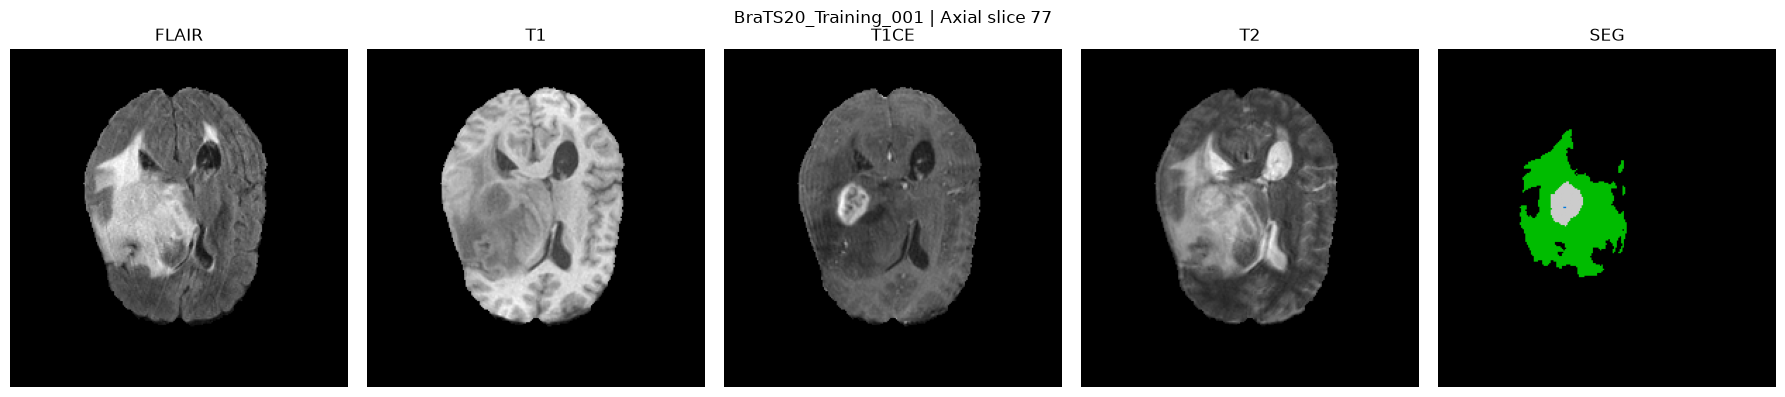

Phase 1 Completed Successfully


In [79]:
# Phase 1 — Cell 8: Display middle axial slice for all modalities + segmentation

middle_slice = arrays["FLAIR"].shape[2] // 2
print(f"Middle axial slice index: {middle_slice}")

titles = ["FLAIR", "T1", "T1CE", "T2", "SEG"]
fig, axes = plt.subplots(1, 5, figsize=(18, 4))

for ax, title in zip(axes, titles):
    slice_img = arrays[title][:, :, middle_slice]
    cmap = "nipy_spectral" if title == "SEG" else "gray"
    ax.imshow(np.rot90(slice_img), cmap=cmap)
    ax.set_title(title)
    ax.axis("off")

plt.suptitle(f"{first_patient_id} | Axial slice {middle_slice}", fontsize=12)
plt.tight_layout()
plt.show()

print("Phase 1 Completed Successfully")

In [80]:
# Phase 2 — Cell 1: Complete patient-count verification

print("=== Patient Count Verification ===")
print(f"Dataset path     : {DATASET_PATH}")
print(f"Total patients   : {len(patient_folders)}")
print(f"First patient    : {os.path.basename(patient_folders[0])}")
print(f"Last patient     : {os.path.basename(patient_folders[-1])}")

=== Patient Count Verification ===
Dataset path     : data\raw\BraTS2020\MICCAI_BraTS2020_TrainingData
Total patients   : 369
First patient    : BraTS20_Training_001
Last patient     : BraTS20_Training_369


In [81]:
# Phase 2 — Cell 2: Required-modality presence check (all patients)

required_modalities = ["FLAIR", "T1", "T1CE", "T2", "SEG"]
missing_records = []

for patient_dir in patient_folders:
    patient_id = os.path.basename(patient_dir)
    for modality in required_modalities:
        try:
            _ = resolve_nifti_path(patient_dir, modality)
        except FileNotFoundError:
            missing_records.append(
                {"patient_id": patient_id, "modality": modality}
            )

missing_df = pd.DataFrame(missing_records)

print("=== Missing Modality Files ===")
if missing_df.empty:
    print("No missing modality files detected.")
else:
    print(missing_df.to_string(index=False))
    print(f"\nTotal missing files: {len(missing_df)}")

=== Missing Modality Files ===
          patient_id modality
BraTS20_Training_355      SEG

Total missing files: 1


In [82]:
# Phase 2 — Cell 3: Unreadable / corrupted NIfTI detection

corrupted_records = []

for patient_dir in patient_folders:
    patient_id = os.path.basename(patient_dir)

    for modality in required_modalities:
        try:
            nifti_path = resolve_nifti_path(patient_dir, modality)
        except FileNotFoundError:
            # Already counted as missing in Cell 2
            continue

        try:
            _ = nib.load(nifti_path).get_fdata(dtype=np.float32)
        except Exception as exc:
            corrupted_records.append(
                {
                    "patient_id": patient_id,
                    "modality": modality,
                    "file": os.path.basename(nifti_path),
                    "error": str(exc),
                }
            )

corrupted_df = pd.DataFrame(corrupted_records)

print("=== Corrupted / Unreadable NIfTI Files ===")
if corrupted_df.empty:
    print("No corrupted or unreadable NIfTI files detected.")
else:
    print(corrupted_df.to_string(index=False))
    print(f"\nTotal corrupted files: {len(corrupted_df)}")

=== Corrupted / Unreadable NIfTI Files ===
No corrupted or unreadable NIfTI files detected.


In [83]:
# Phase 2 — Cell 4: Spatial-dimension compatibility check

shape_records = []
incompatible_patients = []

for patient_dir in patient_folders:
    patient_id = os.path.basename(patient_dir)
    shapes = {}

    try:
        for modality in required_modalities:
            nifti_path = resolve_nifti_path(patient_dir, modality)
            shapes[modality] = nib.load(nifti_path).shape
    except Exception as exc:
        incompatible_patients.append(
            {"patient_id": patient_id, "reason": f"load_error: {exc}"}
        )
        continue

    unique_shapes = set(shapes.values())
    is_compatible = len(unique_shapes) == 1

    shape_records.append(
        {
            "patient_id": patient_id,
            "FLAIR": shapes.get("FLAIR"),
            "T1": shapes.get("T1"),
            "T1CE": shapes.get("T1CE"),
            "T2": shapes.get("T2"),
            "SEG": shapes.get("SEG"),
            "compatible": is_compatible,
        }
    )

    if not is_compatible:
        incompatible_patients.append(
            {"patient_id": patient_id, "reason": f"shape_mismatch: {shapes}"}
        )

shape_df = pd.DataFrame(shape_records)
n_compatible = int(shape_df["compatible"].sum()) if not shape_df.empty else 0
n_incompatible = len(incompatible_patients)

print("=== Spatial Dimension Compatibility ===")
print(f"Compatible patients   : {n_compatible}")
print(f"Incompatible patients : {n_incompatible}")

if incompatible_patients:
    print("\nIncompatible cases:")
    for item in incompatible_patients:
        print(f"  {item['patient_id']}: {item['reason']}")
else:
    print("All checked patients have matching modality/segmentation shapes.")

=== Spatial Dimension Compatibility ===
Compatible patients   : 368
Incompatible patients : 1

Incompatible cases:
  BraTS20_Training_355: load_error: Could not resolve modality 'SEG' in: data\raw\BraTS2020\MICCAI_BraTS2020_TrainingData\BraTS20_Training_355


In [84]:
# Phase 2 — Cell 5: Segmentation class labels and frequency (dataset-wide)

class_counts = {}

for patient_dir in patient_folders:
    try:
        seg_path = resolve_nifti_path(patient_dir, "SEG")
        seg = nib.load(seg_path).get_fdata(dtype=np.float32)
    except Exception:
        continue

    labels, counts = np.unique(seg.astype(np.int32), return_counts=True)
    for label, count in zip(labels, counts):
        label = int(label)
        class_counts[label] = class_counts.get(label, 0) + int(count)

seg_class_df = (
    pd.DataFrame(
        [{"class_label": k, "voxel_count": v} for k, v in sorted(class_counts.items())]
    )
    if class_counts
    else pd.DataFrame(columns=["class_label", "voxel_count"])
)

if not seg_class_df.empty:
    total_voxels = seg_class_df["voxel_count"].sum()
    seg_class_df["percentage"] = (seg_class_df["voxel_count"] / total_voxels) * 100.0

print("=== Segmentation Class Labels & Frequency ===")
if seg_class_df.empty:
    print("No segmentation masks could be analyzed.")
else:
    print(seg_class_df.to_string(index=False))

=== Segmentation Class Labels & Frequency ===
 class_label  voxel_count  percentage
           0   3248909300   98.886177
           1      8129761    0.247443
           2     21256835    0.646989
           4      7208104    0.219391


In [85]:
# Phase 2 — Cell 6: Background vs tumor voxel proportions

if seg_class_df.empty:
    background_voxels = 0
    tumor_voxels = 0
    total_seg_voxels = 0
    background_pct = np.nan
    tumor_pct = np.nan
else:
    background_voxels = int(
        seg_class_df.loc[seg_class_df["class_label"] == 0, "voxel_count"].sum()
    )
    tumor_voxels = int(
        seg_class_df.loc[seg_class_df["class_label"] != 0, "voxel_count"].sum()
    )
    total_seg_voxels = background_voxels + tumor_voxels
    background_pct = (background_voxels / total_seg_voxels) * 100.0 if total_seg_voxels else np.nan
    tumor_pct = (tumor_voxels / total_seg_voxels) * 100.0 if total_seg_voxels else np.nan

print("=== Background vs Tumor Voxels ===")
print(f"Background voxels : {background_voxels} ({background_pct:.4f}%)")
print(f"Tumor voxels      : {tumor_voxels} ({tumor_pct:.4f}%)")
print(f"Total voxels      : {total_seg_voxels}")

=== Background vs Tumor Voxels ===
Background voxels : 3248909300 (98.8862%)
Tumor voxels      : 36594700 (1.1138%)
Total voxels      : 3285504000


In [86]:
# Phase 2 — Cell 7: Concise dataset-integrity summary

valid_patients = 0
for patient_dir in patient_folders:
    patient_id = os.path.basename(patient_dir)

    has_missing = (
        (not missing_df.empty) and (missing_df["patient_id"] == patient_id).any()
    )
    has_corrupt = (
        (not corrupted_df.empty) and (corrupted_df["patient_id"] == patient_id).any()
    )
    has_shape_issue = any(item["patient_id"] == patient_id for item in incompatible_patients)

    if (not has_missing) and (not has_corrupt) and (not has_shape_issue):
        valid_patients += 1

print("=== Dataset Integrity Summary ===")
print(f"Total patients              : {len(patient_folders)}")
print(f"Valid patients              : {valid_patients}")
print(f"Patients with missing files : {missing_df['patient_id'].nunique() if not missing_df.empty else 0}")
print(f"Missing modality files      : {len(missing_df)}")
print(f"Corrupted NIfTI files       : {len(corrupted_df)}")
print(f"Shape-incompatible patients : {n_incompatible}")
print(f"Unique seg class labels     : {sorted(class_counts.keys()) if class_counts else []}")
print(f"Background voxel proportion : {background_pct:.4f}%")
print(f"Tumor voxel proportion      : {tumor_pct:.4f}%")

print("\nPhase 2 Completed Successfully")

=== Dataset Integrity Summary ===
Total patients              : 369
Valid patients              : 368
Patients with missing files : 1
Missing modality files      : 1
Corrupted NIfTI files       : 0
Shape-incompatible patients : 1
Unique seg class labels     : [0, 1, 2, 4]
Background voxel proportion : 98.8862%
Tumor voxel proportion      : 1.1138%

Phase 2 Completed Successfully


In [87]:
# Phase 3 — Cell 1: Analysis configuration (representative patient)

MRI_MODALITIES = ["FLAIR", "T1", "T1CE", "T2"]
PERCENTILES = [1, 5, 25, 50, 75, 95, 99]
RANDOM_SEED = 42

# Start with one representative patient; later loops can reuse this logic
representative_patient = first_patient
representative_patient_id = os.path.basename(representative_patient)

print("=== Phase 3 Configuration ===")
print(f"Representative patient : {representative_patient_id}")
print(f"Modalities             : {MRI_MODALITIES}")
print(f"Percentiles            : {PERCENTILES}")
print(f"Random seed            : {RANDOM_SEED}")

=== Phase 3 Configuration ===
Representative patient : BraTS20_Training_001
Modalities             : ['FLAIR', 'T1', 'T1CE', 'T2']
Percentiles            : [1, 5, 25, 50, 75, 95, 99]
Random seed            : 42


In [88]:
# Phase 3 — Cell 2: Load representative-patient MRI volumes (keep 3D structure)

rep_volumes = {}

for modality in MRI_MODALITIES:
    nifti_path = resolve_nifti_path(representative_patient, modality)
    rep_volumes[modality] = nib.load(nifti_path).get_fdata(dtype=np.float32)

print("Loaded representative volumes:")
for modality, volume in rep_volumes.items():
    print(f"  {modality:5s} | shape={volume.shape} | dtype={volume.dtype}")

Loaded representative volumes:
  FLAIR | shape=(240, 240, 155) | dtype=float32
  T1    | shape=(240, 240, 155) | dtype=float32
  T1CE  | shape=(240, 240, 155) | dtype=float32
  T2    | shape=(240, 240, 155) | dtype=float32


In [89]:
# Phase 3 — Cell 3: Intensity statistics helper (full volume + foreground)

def compute_intensity_stats(volume, modality, region_name, percentiles=PERCENTILES):
    """Compute reproducible intensity statistics for a 3D MRI volume."""
    flat = volume.ravel()
    total_voxels = flat.size
    zero_voxels = int(np.sum(flat == 0))
    nonzero_voxels = total_voxels - zero_voxels

    if region_name == "full":
        values = flat
    elif region_name == "foreground":
        values = flat[flat != 0]
    else:
        raise ValueError("region_name must be 'full' or 'foreground'")

    if values.size == 0:
        stats = {
            "modality": modality,
            "region": region_name,
            "min": np.nan,
            "max": np.nan,
            "mean": np.nan,
            "median": np.nan,
            "std": np.nan,
            "zero_voxels": zero_voxels,
            "nonzero_voxels": nonzero_voxels,
            "zero_proportion": zero_voxels / total_voxels,
            "nonzero_proportion": nonzero_voxels / total_voxels,
        }
        for p in percentiles:
            stats[f"p{p}"] = np.nan
        return stats

    stats = {
        "modality": modality,
        "region": region_name,
        "min": float(np.min(values)),
        "max": float(np.max(values)),
        "mean": float(np.mean(values)),
        "median": float(np.median(values)),
        "std": float(np.std(values)),
        "zero_voxels": zero_voxels,
        "nonzero_voxels": nonzero_voxels,
        "zero_proportion": zero_voxels / total_voxels,
        "nonzero_proportion": nonzero_voxels / total_voxels,
    }
    percentile_values = np.percentile(values, percentiles)
    for p, value in zip(percentiles, percentile_values):
        stats[f"p{p}"] = float(value)
    return stats


print("Intensity statistics helper ready.")

Intensity statistics helper ready.


In [90]:
# Phase 3 — Cell 4: Build numerical intensity statistics table

intensity_rows = []

for modality in MRI_MODALITIES:
    volume = rep_volumes[modality]
    intensity_rows.append(compute_intensity_stats(volume, modality, "full"))
    intensity_rows.append(compute_intensity_stats(volume, modality, "foreground"))

intensity_stats_df = pd.DataFrame(intensity_rows)

# Convenient views for inspection
full_stats_df = intensity_stats_df[intensity_stats_df["region"] == "full"].reset_index(drop=True)
foreground_stats_df = intensity_stats_df[intensity_stats_df["region"] == "foreground"].reset_index(drop=True)

print("=== Full-volume intensity statistics ===")
display(full_stats_df)

print("=== Foreground (non-zero) intensity statistics ===")
display(foreground_stats_df)

=== Full-volume intensity statistics ===


,modality,region,min,max,mean,median,std,zero_voxels,nonzero_voxels,zero_proportion,nonzero_proportion,p1,p5,p25,p50,p75,p95,p99
0,FLAIR,full,0.0,625.0,26.021915,0.0,66.765373,7585115,1342885,0.849587,0.150413,0.0,0.0,0.0,0.0,0.0,180.0,304.0
1,T1,full,0.0,678.0,53.287132,0.0,130.784943,7585115,1342885,0.849587,0.150413,0.0,0.0,0.0,0.0,0.0,393.0,475.0
2,T1CE,full,0.0,1845.0,62.771641,0.0,155.079163,7585115,1342885,0.849587,0.150413,0.0,0.0,0.0,0.0,0.0,456.0,546.0
3,T2,full,0.0,376.0,17.251438,0.0,44.979191,7585115,1342885,0.849587,0.150413,0.0,0.0,0.0,0.0,0.0,120.0,208.0


=== Foreground (non-zero) intensity statistics ===


,modality,region,min,max,mean,median,std,zero_voxels,nonzero_voxels,zero_proportion,nonzero_proportion,p1,p5,p25,p50,p75,p95,p99
0,FLAIR,foreground,14.0,625.0,173.003387,158.0,64.865944,7585115,1342885,0.849587,0.150413,51.0,96.0,133.0,158.0,195.0,319.0,376.0
1,T1,foreground,25.0,678.0,354.272705,357.0,84.187027,7585115,1342885,0.849587,0.150413,139.0,199.0,303.0,357.0,416.0,482.0,508.0
2,T1CE,foreground,49.0,1845.0,417.329224,417.0,109.193008,7585115,1342885,0.849587,0.150413,161.0,245.0,357.0,417.0,476.0,561.0,778.0
3,T2,foreground,5.0,376.0,114.693985,101.0,47.691029,7585115,1342885,0.849587,0.150413,52.0,63.0,81.0,101.0,134.0,218.0,261.0


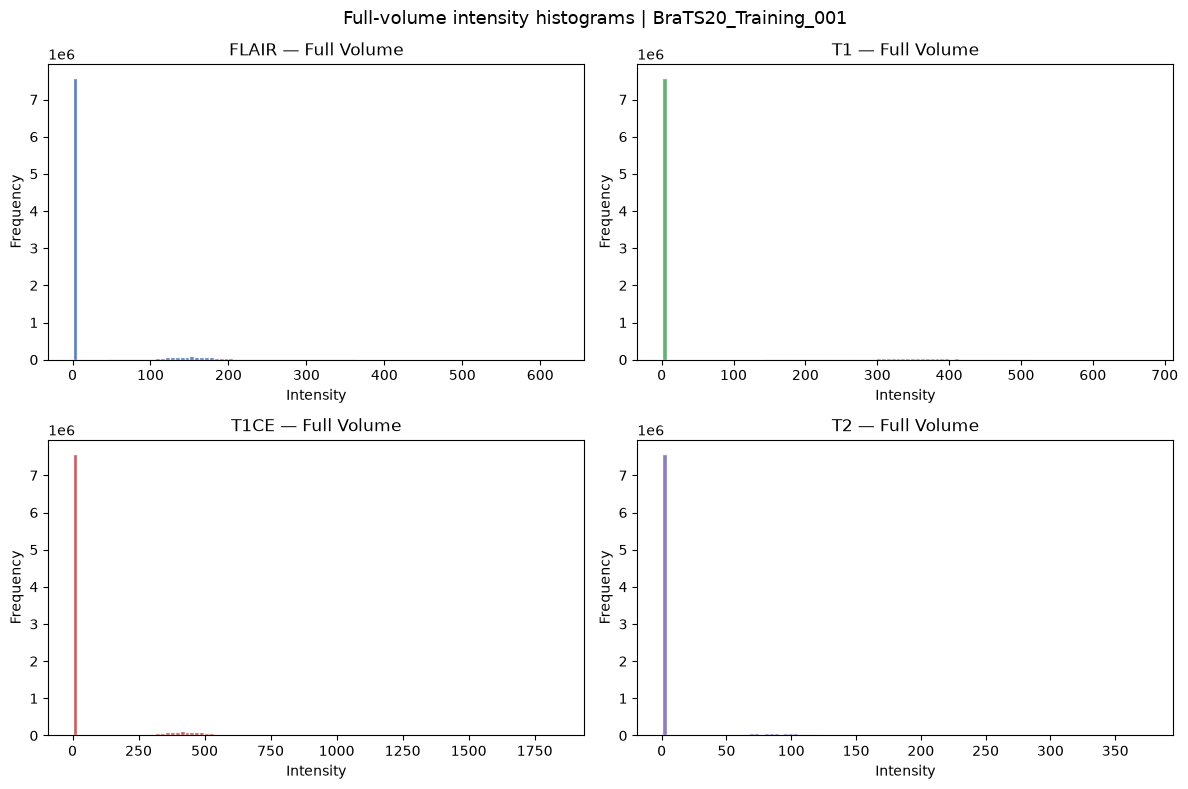

In [91]:
# Phase 3 — Cell 5: Histograms of full-volume intensity distributions

fig, axes = plt.subplots(2, 2, figsize=(12, 8))
axes = axes.ravel()
colors = {"FLAIR": "#4C72B0", "T1": "#55A868", "T1CE": "#C44E52", "T2": "#8172B2"}

for ax, modality in zip(axes, MRI_MODALITIES):
    values = rep_volumes[modality].ravel()
    ax.hist(values, bins=100, color=colors[modality], edgecolor="white", alpha=0.9)
    ax.set_title(f"{modality} — Full Volume")
    ax.set_xlabel("Intensity")
    ax.set_ylabel("Frequency")

plt.suptitle(
    f"Full-volume intensity histograms | {representative_patient_id}",
    fontsize=13,
)
plt.tight_layout()
plt.show()

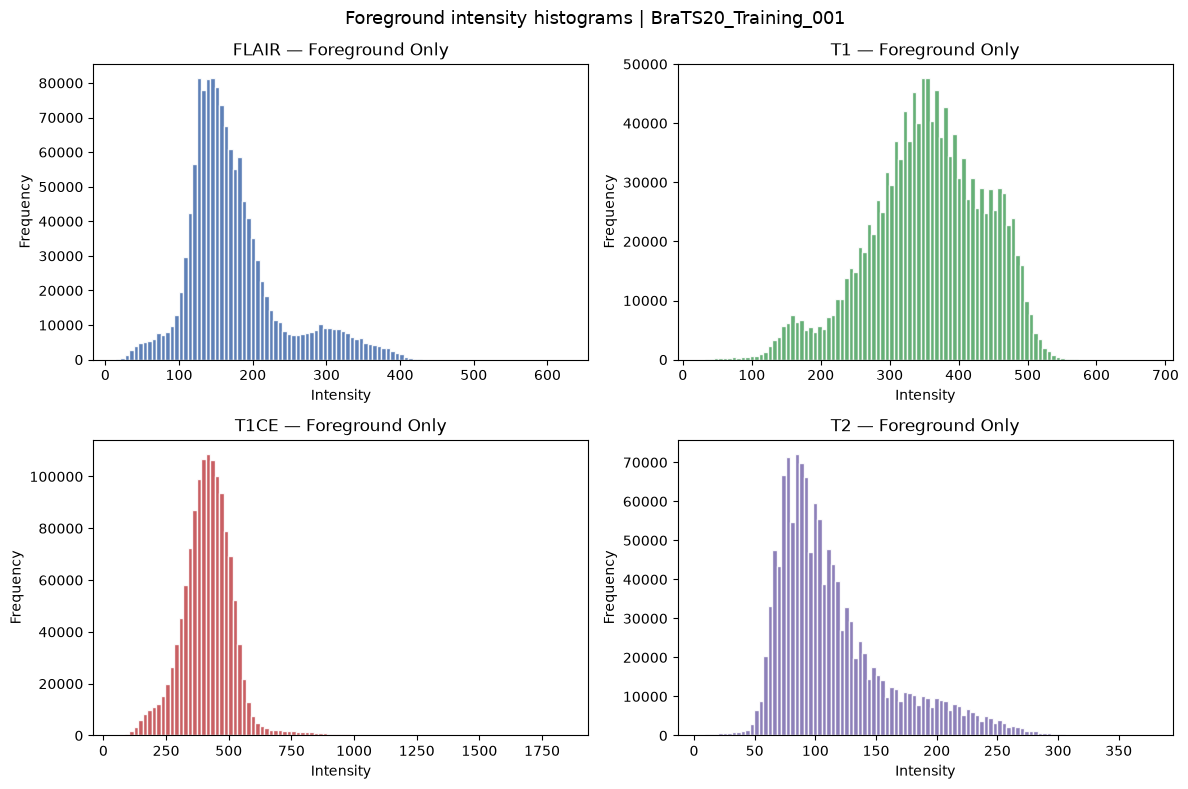

In [92]:
# Phase 3 — Cell 6: Histograms of foreground / non-zero intensity distributions

fig, axes = plt.subplots(2, 2, figsize=(12, 8))
axes = axes.ravel()

for ax, modality in zip(axes, MRI_MODALITIES):
    values = rep_volumes[modality]
    foreground = values[values != 0]
    ax.hist(foreground, bins=100, color=colors[modality], edgecolor="white", alpha=0.9)
    ax.set_title(f"{modality} — Foreground Only")
    ax.set_xlabel("Intensity")
    ax.set_ylabel("Frequency")

plt.suptitle(
    f"Foreground intensity histograms | {representative_patient_id}",
    fontsize=13,
)
plt.tight_layout()
plt.show()

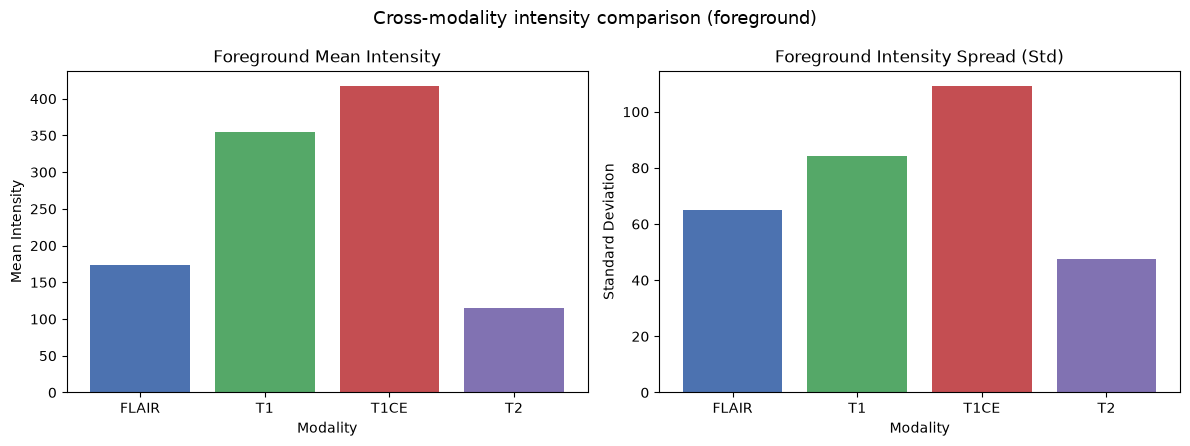

Foreground comparison table:


,modality,mean,median,std,min,max,p5,p95
0,FLAIR,173.003387,158.0,64.865944,14.0,625.0,96.0,319.0
1,T1,354.272705,357.0,84.187027,25.0,678.0,199.0,482.0
2,T1CE,417.329224,417.0,109.193008,49.0,1845.0,245.0,561.0
3,T2,114.693985,101.0,47.691029,5.0,376.0,63.0,218.0


In [93]:
# Phase 3 — Cell 7: Cross-modality comparison (foreground mean / std / percentiles)

compare_df = foreground_stats_df[
    ["modality", "mean", "median", "std", "min", "max", "p5", "p95"]
].copy()

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

axes[0].bar(compare_df["modality"], compare_df["mean"], color=[colors[m] for m in compare_df["modality"]])
axes[0].set_title("Foreground Mean Intensity")
axes[0].set_xlabel("Modality")
axes[0].set_ylabel("Mean Intensity")

axes[1].bar(compare_df["modality"], compare_df["std"], color=[colors[m] for m in compare_df["modality"]])
axes[1].set_title("Foreground Intensity Spread (Std)")
axes[1].set_xlabel("Modality")
axes[1].set_ylabel("Standard Deviation")

plt.suptitle("Cross-modality intensity comparison (foreground)", fontsize=13)
plt.tight_layout()
plt.show()

print("Foreground comparison table:")
display(compare_df)

In [94]:
# Phase 3 — Cell 8: Optional extension hook for full-dataset analysis later

def analyze_patient_intensities(patient_dir, modalities=MRI_MODALITIES):
    """
    Reusable analyzer for one patient.
    Can later be mapped over patient_folders for dataset-wide profiling.
    """
    rows = []
    for modality in modalities:
        volume = nib.load(resolve_nifti_path(patient_dir, modality)).get_fdata(dtype=np.float32)
        rows.append(compute_intensity_stats(volume, modality, "full"))
        rows.append(compute_intensity_stats(volume, modality, "foreground"))
    df = pd.DataFrame(rows)
    df.insert(0, "patient_id", os.path.basename(patient_dir))
    return df


# Smoke-test the reusable function on the same representative patient
_extension_test_df = analyze_patient_intensities(representative_patient)
print("Extension helper verified on representative patient.")
print(f"Returned rows: {len(_extension_test_df)} (expected {len(MRI_MODALITIES) * 2})")

Extension helper verified on representative patient.
Returned rows: 8 (expected 8)


In [95]:
# Phase 3 — Cell 9: Concise Phase 3 summary for adaptive preprocessing

fg = foreground_stats_df.set_index("modality")
full = full_stats_df.set_index("modality")

widest_modality = fg["std"].idxmax()
most_compact_modality = fg["std"].idxmin()
highest_mean_modality = fg["mean"].idxmax()
lowest_mean_modality = fg["mean"].idxmin()

avg_zero_prop = full["zero_proportion"].mean() * 100.0
avg_nonzero_prop = full["nonzero_proportion"].mean() * 100.0

print("=== Phase 3 Summary: Intensity Characteristics ===")
print(f"Representative patient: {representative_patient_id}")
print(
    f"Background dominates volumes: average zero-voxel proportion ≈ {avg_zero_prop:.2f}% "
    f"(non-zero ≈ {avg_nonzero_prop:.2f}%)."
)
print(
    "Therefore, full-volume min/mean values are background-biased; "
    "foreground/non-zero statistics are more informative for preprocessing decisions."
)
print(
    f"Widest foreground intensity spread : {widest_modality} "
    f"(std={fg.loc[widest_modality, 'std']:.4f})"
)
print(
    f"Most compact foreground distribution: {most_compact_modality} "
    f"(std={fg.loc[most_compact_modality, 'std']:.4f})"
)
print(
    f"Highest / lowest foreground mean   : {highest_mean_modality} / {lowest_mean_modality}"
)
print(
    "Adaptive-preprocessing implications: "
    "1) exclude background before normalization, "
    "2) apply modality-specific intensity scaling, "
    "3) prefer robust statistics (median/percentiles) over raw min/max, "
    "4) consider contrast-aware rules especially for T1CE vs non-contrast modalities."
)

print("\nPhase 3 Completed Successfully")

=== Phase 3 Summary: Intensity Characteristics ===
Representative patient: BraTS20_Training_001
Background dominates volumes: average zero-voxel proportion ≈ 84.96% (non-zero ≈ 15.04%).
Therefore, full-volume min/mean values are background-biased; foreground/non-zero statistics are more informative for preprocessing decisions.
Widest foreground intensity spread : T1CE (std=109.1930)
Most compact foreground distribution: T2 (std=47.6910)
Highest / lowest foreground mean   : T1CE / T2
Adaptive-preprocessing implications: 1) exclude background before normalization, 2) apply modality-specific intensity scaling, 3) prefer robust statistics (median/percentiles) over raw min/max, 4) consider contrast-aware rules especially for T1CE vs non-contrast modalities.

Phase 3 Completed Successfully


In [96]:
# Phase 4 — Cell 1: Select a reproducible representative patient subset

# FULL COHORT: the subset notebook sampled 8 patients here. This run uses every
# patient discovery found, so Phases 4-8 describe the cohort, not a sample.
# rng_p4 is still created because Cell 2 uses it to draw bounded foreground
# samples for the pooled histograms.

N_REP_PATIENTS = len(patient_folders)
PHASE4_SEED = 42
rng_p4 = np.random.default_rng(PHASE4_SEED)

# first_patient stays at the head so figures showing "the first few patients"
# still include the one Phase 3 analysed in depth. patient_folders is already
# sorted, so the rest follow in ID order and every downstream table is
# deterministic without an RNG.
selected_patients = [first_patient] + [p for p in patient_folders if p != first_patient]

selected_patient_ids = [os.path.basename(p) for p in selected_patients]

print("=== Phase 4 Cohort (full dataset) ===")
print(f"Patients selected : {len(selected_patients)} of {len(patient_folders)} discovered")
print(f"First / last ID   : {sorted(selected_patient_ids)[0]} ... {sorted(selected_patient_ids)[-1]}")
print(f"Volumes to read   : {len(selected_patients) * len(MRI_MODALITIES)} "
      f"({len(selected_patients)} patients x {len(MRI_MODALITIES)} modalities)")

=== Phase 4 Cohort (full dataset) ===
Patients selected : 369 of 369 discovered
First / last ID   : BraTS20_Training_001 ... BraTS20_Training_369
Volumes to read   : 1476 (369 patients x 4 modalities)


In [97]:
# Phase 4 — Cell 2: Collect foreground intensities per modality (one volume at a time)

# Store pooled foreground intensities and per-patient summary stats
foreground_pool = {m: [] for m in MRI_MODALITIES}
per_patient_fg_stats = []

# FULL COHORT: 50,000 samples x 369 patients would pool ~18 M float32 values per
# modality (~74 MB each, ~295 MB for four) just to draw a 100-bin histogram.
# 4,000 per patient still pools ~1.5 M values per modality - far more than
# enough to resolve 100 bins - and keeps the pass inside a few hundred MB.
MAX_POOL_SAMPLES_PER_PATIENT = 4_000

# This cell reads 4 volumes per patient (~1,476 volumes); expect ~5-10 minutes.
_t0_p4 = time.time()

for _i, patient_dir in enumerate(selected_patients, start=1):
    patient_id = os.path.basename(patient_dir)
    if _i % 25 == 0 or _i == len(selected_patients):
        print(f"  [{_i:3d}/{len(selected_patients)}] {patient_id} "
              f"| {time.time() - _t0_p4:6.0f}s elapsed", flush=True)

    for modality in MRI_MODALITIES:
        volume = nib.load(resolve_nifti_path(patient_dir, modality)).get_fdata(dtype=np.float32)
        foreground = volume[volume != 0]

        # Per-patient foreground summary (no image modification)
        stats = compute_intensity_stats(volume, modality, "foreground")
        stats["patient_id"] = patient_id
        per_patient_fg_stats.append(stats)

        # Bounded random sample for pooled distribution plots
        if foreground.size > 0:
            if foreground.size > MAX_POOL_SAMPLES_PER_PATIENT:
                sample = rng_p4.choice(foreground, size=MAX_POOL_SAMPLES_PER_PATIENT, replace=False)
            else:
                sample = foreground
            foreground_pool[modality].append(sample.astype(np.float32, copy=False))

        del volume  # free each 3D volume promptly

for modality in MRI_MODALITIES:
    foreground_pool[modality] = (
        np.concatenate(foreground_pool[modality])
        if foreground_pool[modality]
        else np.array([], dtype=np.float32)
    )

per_patient_fg_df = pd.DataFrame(per_patient_fg_stats)

print("Foreground intensity pooling complete.")
for modality in MRI_MODALITIES:
    print(f"  {modality:5s}: pooled samples = {foreground_pool[modality].size}")

  [ 25/369] BraTS20_Training_025 |     12s elapsed
  [ 50/369] BraTS20_Training_050 |     24s elapsed
  [ 75/369] BraTS20_Training_075 |     36s elapsed
  [100/369] BraTS20_Training_100 |     49s elapsed
  [125/369] BraTS20_Training_125 |     61s elapsed
  [150/369] BraTS20_Training_150 |     73s elapsed
  [175/369] BraTS20_Training_175 |     85s elapsed
  [200/369] BraTS20_Training_200 |     97s elapsed
  [225/369] BraTS20_Training_225 |    684s elapsed
  [250/369] BraTS20_Training_250 |    697s elapsed
  [275/369] BraTS20_Training_275 |    709s elapsed
  [300/369] BraTS20_Training_300 |    722s elapsed
  [325/369] BraTS20_Training_325 |    735s elapsed
  [350/369] BraTS20_Training_350 |    748s elapsed
  [369/369] BraTS20_Training_369 |    758s elapsed
Foreground intensity pooling complete.
  FLAIR: pooled samples = 1476000
  T1   : pooled samples = 1476000
  T1CE : pooled samples = 1476000
  T2   : pooled samples = 1476000


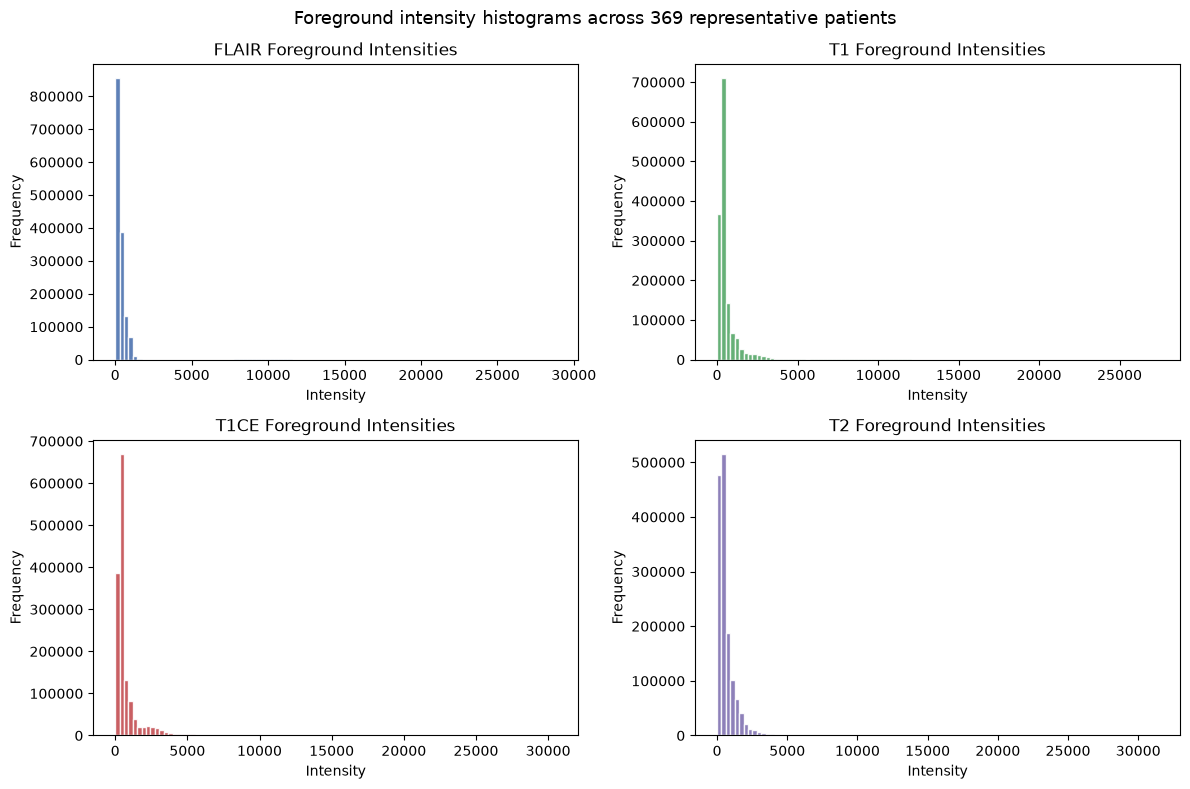

In [98]:
# Phase 4 — Cell 3: Foreground intensity histograms for all four modalities

p4_colors = {"FLAIR": "#4C72B0", "T1": "#55A868", "T1CE": "#C44E52", "T2": "#8172B2"}

fig, axes = plt.subplots(2, 2, figsize=(12, 8))
axes = axes.ravel()

for ax, modality in zip(axes, MRI_MODALITIES):
    values = foreground_pool[modality]
    ax.hist(values, bins=100, color=p4_colors[modality], edgecolor="white", alpha=0.9)
    ax.set_title(f"{modality} Foreground Intensities")
    ax.set_xlabel("Intensity")
    ax.set_ylabel("Frequency")

plt.suptitle(
    f"Foreground intensity histograms across {len(selected_patients)} representative patients",
    fontsize=13,
)
plt.tight_layout()
plt.show()

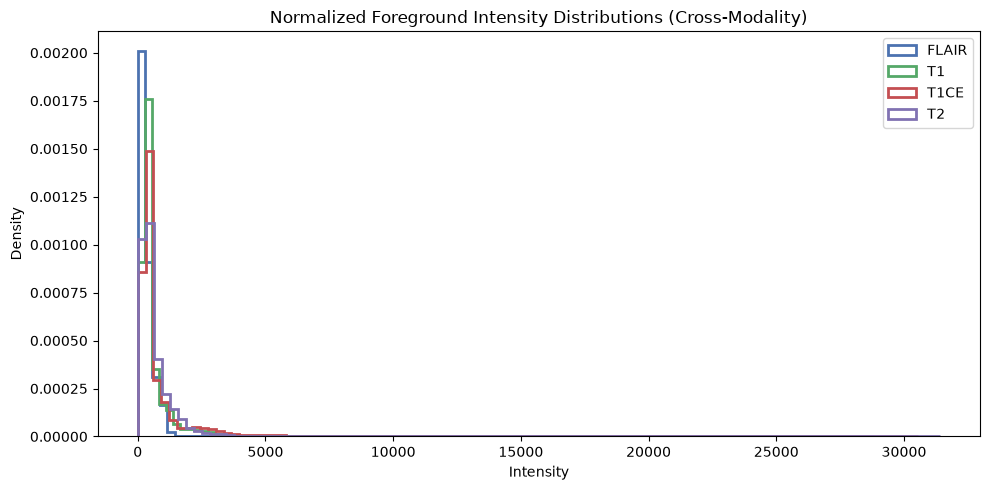

In [99]:
# Phase 4 — Cell 4: Cross-modality distribution comparison (overlaid KDE-style via histograms)

fig, ax = plt.subplots(figsize=(10, 5))

for modality in MRI_MODALITIES:
    values = foreground_pool[modality]
    ax.hist(
        values,
        bins=100,
        density=True,
        histtype="step",
        linewidth=2.0,
        label=modality,
        color=p4_colors[modality],
    )

ax.set_title("Normalized Foreground Intensity Distributions (Cross-Modality)")
ax.set_xlabel("Intensity")
ax.set_ylabel("Density")
ax.legend()
plt.tight_layout()
plt.show()

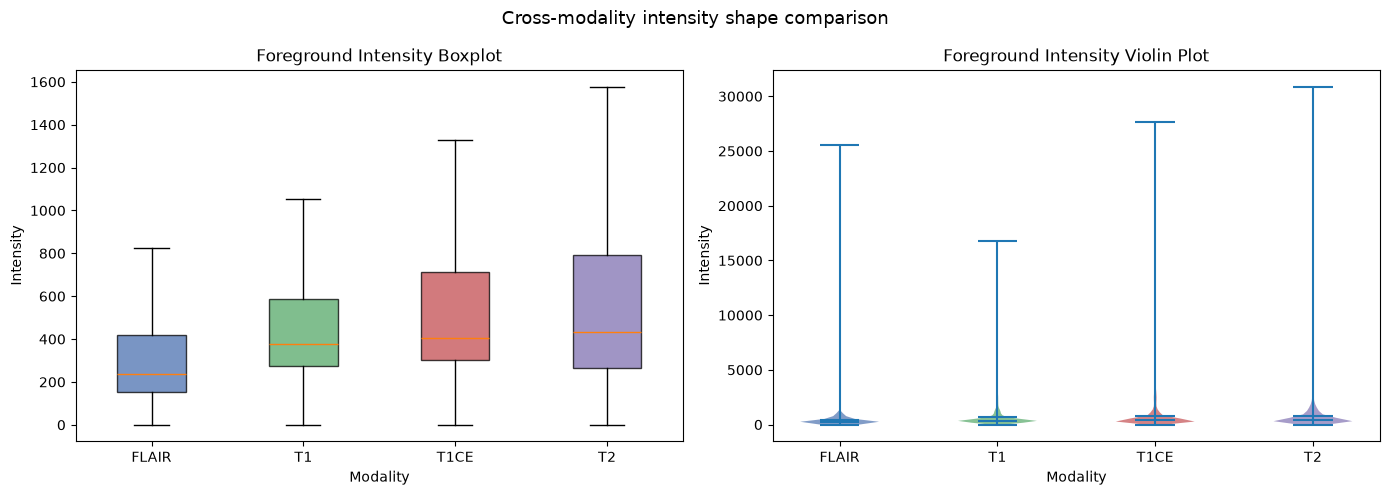

In [100]:
# Phase 4 — Cell 5: Boxplot + violin plot comparison of modality intensities

# Subsample for readable violin/box plots
plot_data = []
plot_labels = []
for modality in MRI_MODALITIES:
    values = foreground_pool[modality]
    if values.size > 80_000:
        values = rng_p4.choice(values, size=80_000, replace=False)
    plot_data.append(values)
    plot_labels.append(modality)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Matplotlib 3.9+ uses tick_labels; older versions used labels
try:
    bp = axes[0].boxplot(plot_data, tick_labels=plot_labels, patch_artist=True, showfliers=False)
except TypeError:
    bp = axes[0].boxplot(plot_data, labels=plot_labels, patch_artist=True, showfliers=False)

for patch, modality in zip(bp["boxes"], plot_labels):
    patch.set_facecolor(p4_colors[modality])
    patch.set_alpha(0.75)
axes[0].set_title("Foreground Intensity Boxplot")
axes[0].set_xlabel("Modality")
axes[0].set_ylabel("Intensity")

parts = axes[1].violinplot(plot_data, showmeans=True, showmedians=True)
for body, modality in zip(parts["bodies"], plot_labels):
    body.set_facecolor(p4_colors[modality])
    body.set_alpha(0.70)
axes[1].set_xticks(np.arange(1, len(plot_labels) + 1))
axes[1].set_xticklabels(plot_labels)
axes[1].set_title("Foreground Intensity Violin Plot")
axes[1].set_xlabel("Modality")
axes[1].set_ylabel("Intensity")

plt.suptitle("Cross-modality intensity shape comparison", fontsize=13)
plt.tight_layout()
plt.show()

In [101]:
# Phase 4 — Cell 6: Percentile ranges and extreme-intensity / outlier profile

percentile_rows = []

for modality in MRI_MODALITIES:
    values = foreground_pool[modality]
    if values.size == 0:
        continue

    p1, p5, p25, p50, p75, p95, p99 = np.percentile(values, [1, 5, 25, 50, 75, 95, 99])
    iqr = p75 - p25
    lower_fence = p25 - 1.5 * iqr
    upper_fence = p75 + 1.5 * iqr
    n_low = int(np.sum(values < lower_fence))
    n_high = int(np.sum(values > upper_fence))

    percentile_rows.append(
        {
            "modality": modality,
            "p1": p1,
            "p5": p5,
            "p25": p25,
            "p50": p50,
            "p75": p75,
            "p95": p95,
            "p99": p99,
            "iqr": iqr,
            "outlier_low_count": n_low,
            "outlier_high_count": n_high,
            "outlier_rate_pct": 100.0 * (n_low + n_high) / values.size,
            "skewness": float(
                pd.Series(values).skew()
            ),
        }
    )

percentile_df = pd.DataFrame(percentile_rows)
print("=== Percentile / Outlier Profile (Pooled Foreground) ===")
display(percentile_df)

=== Percentile / Outlier Profile (Pooled Foreground) ===


,modality,p1,p5,p25,p50,p75,p95,p99,iqr,outlier_low_count,outlier_high_count,outlier_rate_pct,skewness
0,FLAIR,28.0,74.0,153.0,240.0,424.0,942.0,8609.00,271.0,0,114280,7.742547,9.625360
1,T1,44.0,138.0,275.0,375.0,585.0,2155.0,6985.01,310.0,0,195887,13.271477,6.729276
2,T1CE,42.0,80.0,301.0,405.0,713.0,2894.0,6287.01,412.0,0,187519,12.704539,5.165247
3,T2,59.0,100.0,265.0,433.0,788.0,2042.0,8572.00,523.0,0,127071,8.609146,7.659170


=== Inter-patient Foreground Variation Summary ===


,modality,mean_of_means,std_of_means,mean_of_stds,std_of_stds,mean_of_medians,min_mean,max_mean
0,FLAIR,460.411798,1203.790222,140.176989,359.557303,462.716496,34.451878,14034.607422
1,T1,675.102245,1097.555792,174.987367,343.525723,696.055896,39.689762,10733.887695
2,T1CE,788.310680,1185.877420,215.514632,328.454216,794.994825,44.747269,10436.513672
3,T2,769.847340,1288.718973,293.730867,464.091212,700.059742,59.315151,11793.782227


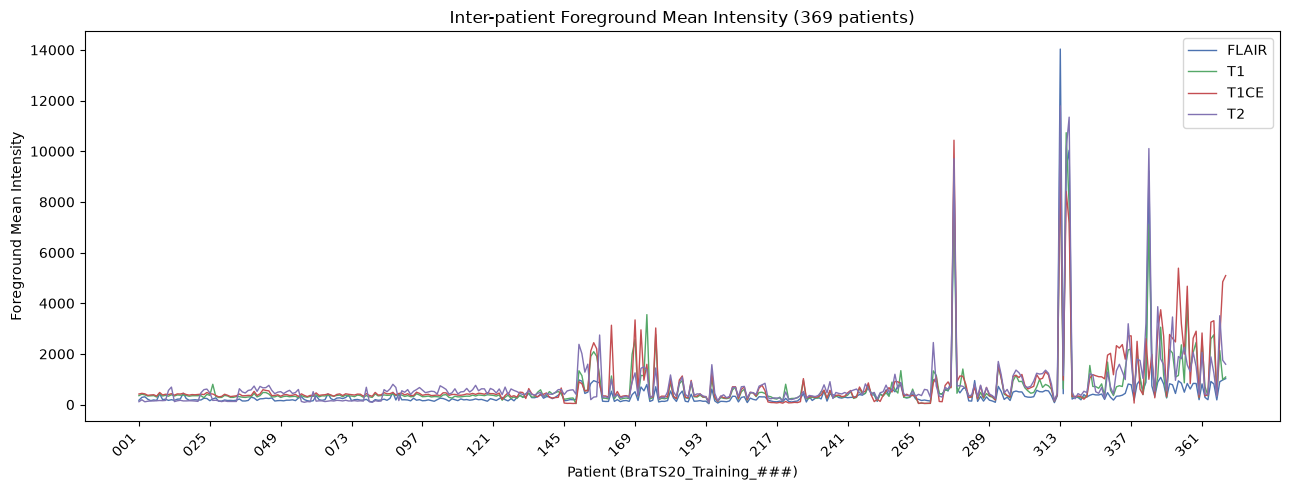

In [102]:
# Phase 4 — Cell 7: Inter-patient intensity variation across the representative subset

interpatient_summary = (
    per_patient_fg_df.groupby("modality")
    .agg(
        mean_of_means=("mean", "mean"),
        std_of_means=("mean", "std"),
        mean_of_stds=("std", "mean"),
        std_of_stds=("std", "std"),
        mean_of_medians=("median", "mean"),
        min_mean=("mean", "min"),
        max_mean=("mean", "max"),
    )
    .reset_index()
)

print("=== Inter-patient Foreground Variation Summary ===")
display(interpatient_summary)

# Visualize patient-wise mean intensity by modality.
# FULL COHORT: 369 categorical x labels are illegible, so patients go on a
# numeric axis in sorted ID order with every ~25th label drawn. Per-point
# markers are dropped for the same reason - at this density the line is the
# signal. The underlying values are unchanged.
_ordered_ids = sorted(per_patient_fg_df["patient_id"].unique())
_x_of = {pid: i for i, pid in enumerate(_ordered_ids)}

fig, ax = plt.subplots(figsize=(13, 5))
for modality in MRI_MODALITIES:
    subset = (
        per_patient_fg_df[per_patient_fg_df["modality"] == modality]
        .assign(_x=lambda d: d["patient_id"].map(_x_of))
        .sort_values("_x")
    )
    ax.plot(
        subset["_x"],
        subset["mean"],
        linewidth=1.0,
        label=modality,
        color=p4_colors[modality],
    )

_step = max(1, len(_ordered_ids) // 15)
_ticks = list(range(0, len(_ordered_ids), _step))
ax.set_xticks(_ticks)
ax.set_xticklabels(
    [_ordered_ids[i].replace("BraTS20_Training_", "") for i in _ticks],
    rotation=45,
    ha="right",
)
ax.set_title(f"Inter-patient Foreground Mean Intensity ({len(_ordered_ids)} patients)")
ax.set_xlabel("Patient (BraTS20_Training_###)")
ax.set_ylabel("Foreground Mean Intensity")
ax.legend()
plt.tight_layout()
plt.show()

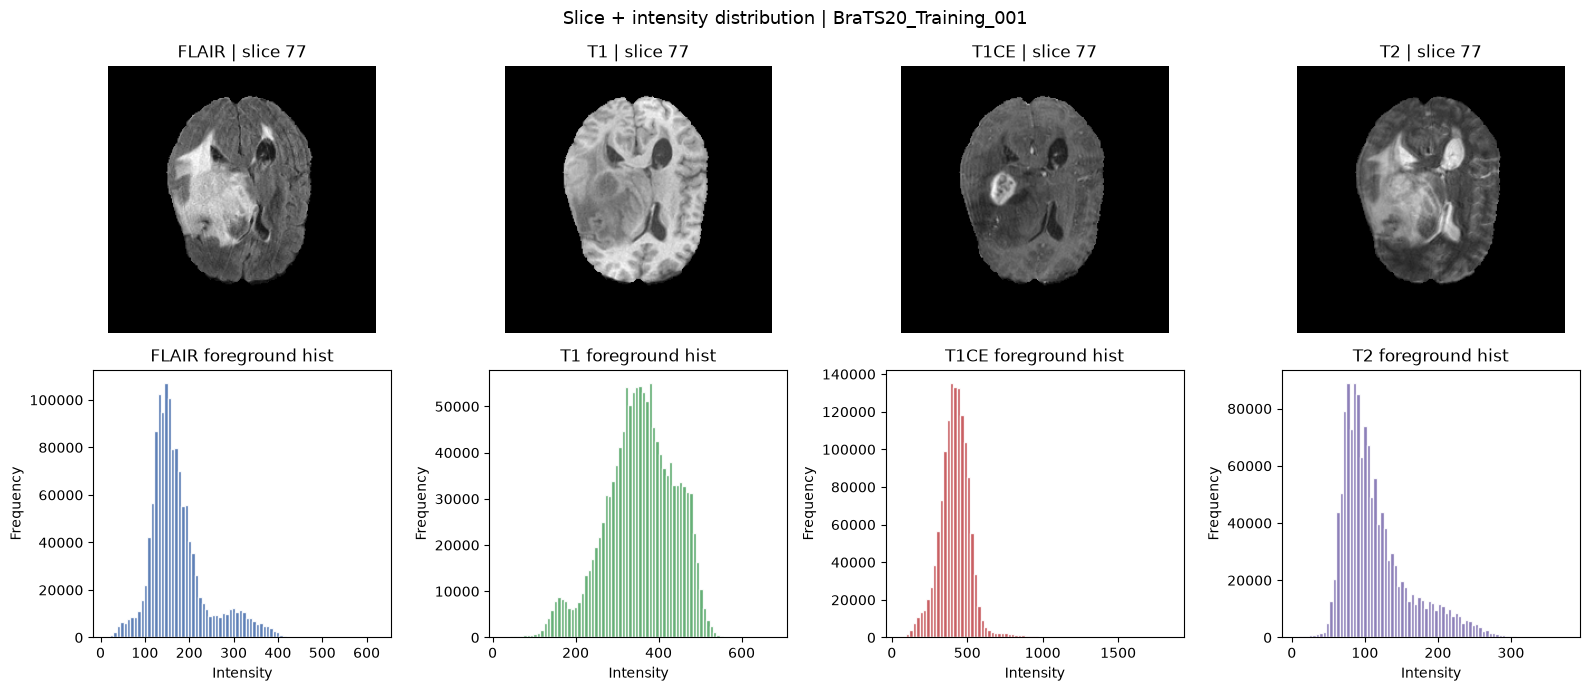

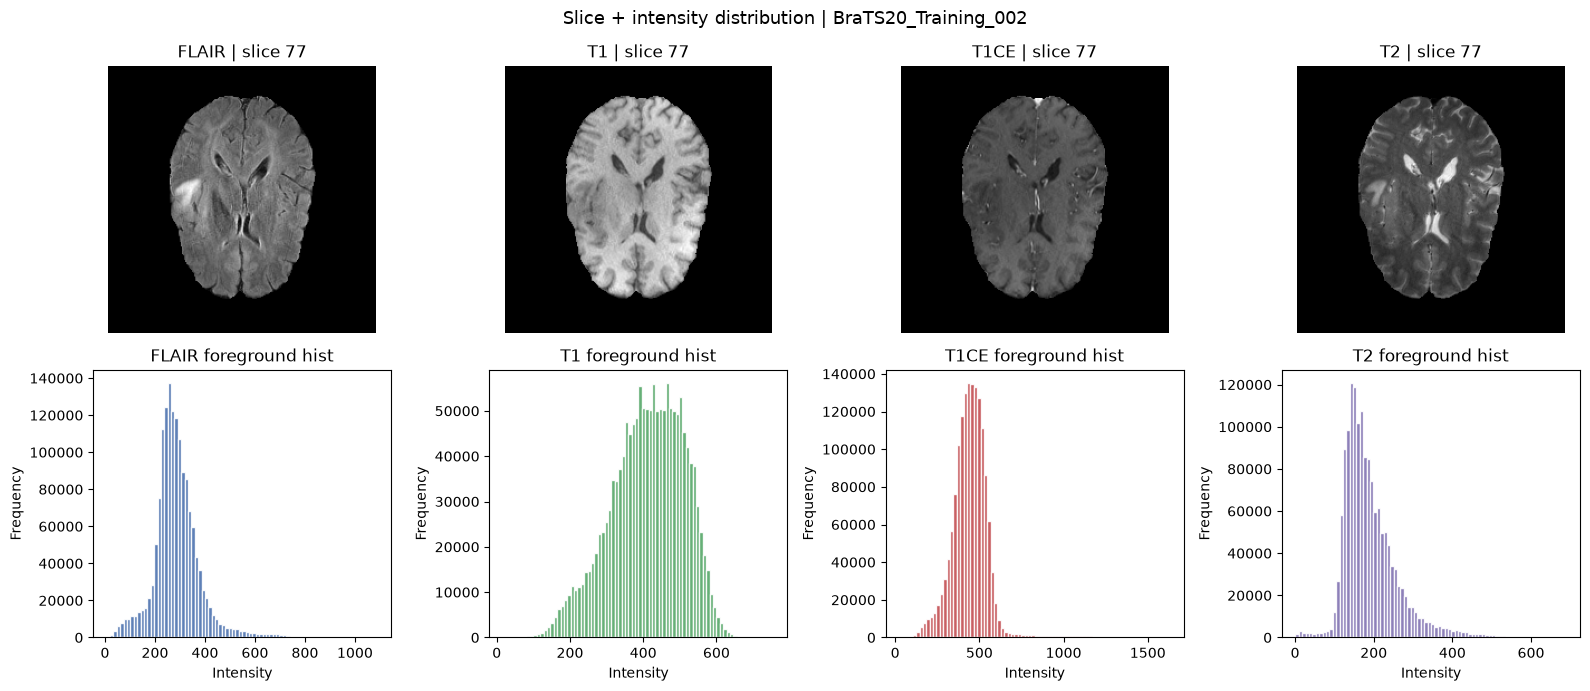

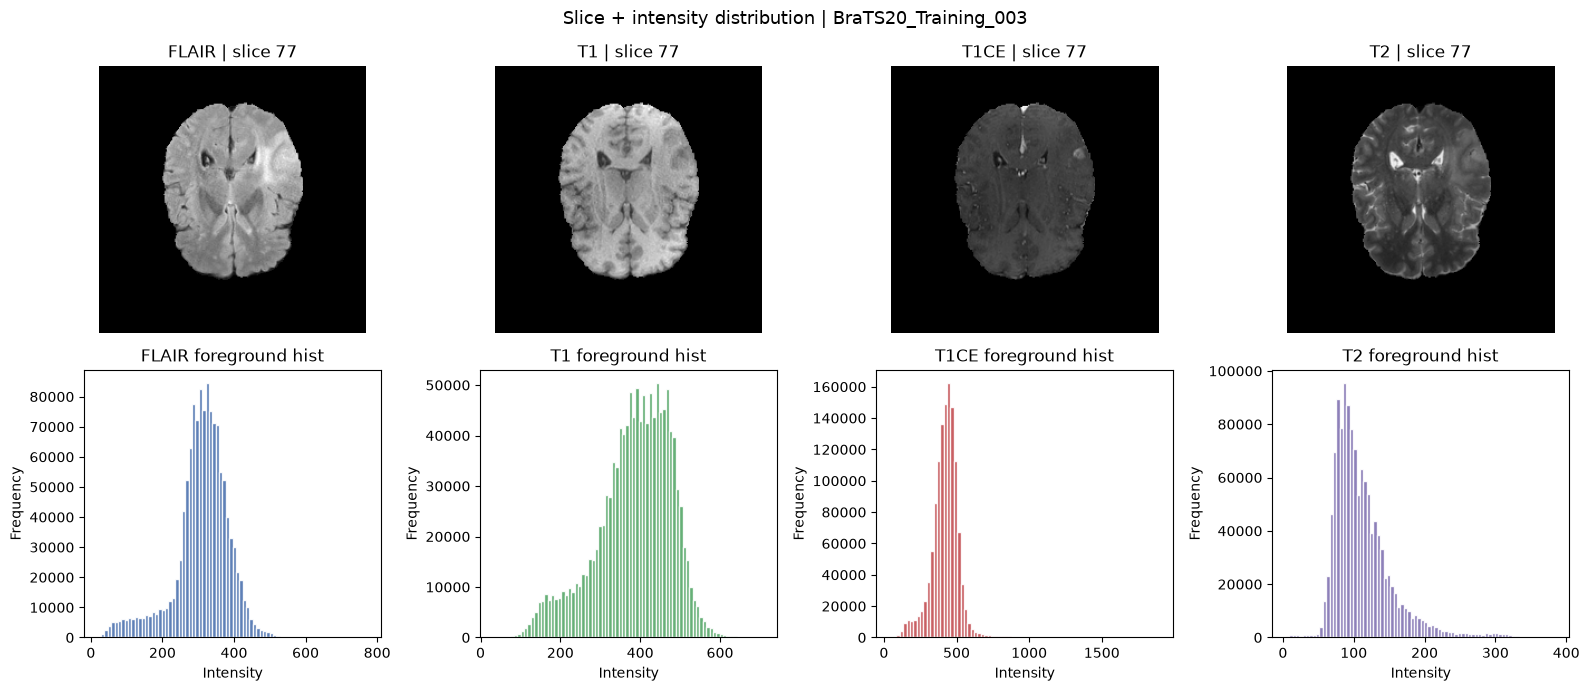

In [103]:
# Phase 4 — Cell 8: Visualize representative slices alongside intensity distributions

# Use up to 3 patients from the selected subset for joint visualization
viz_patients = selected_patients[: min(3, len(selected_patients))]

for patient_dir in viz_patients:
    patient_id = os.path.basename(patient_dir)
    fig, axes = plt.subplots(2, 4, figsize=(16, 7))

    for col, modality in enumerate(MRI_MODALITIES):
        volume = nib.load(resolve_nifti_path(patient_dir, modality)).get_fdata(dtype=np.float32)
        mid = volume.shape[2] // 2
        slice_img = volume[:, :, mid]
        foreground = volume[volume != 0]

        axes[0, col].imshow(np.rot90(slice_img), cmap="gray")
        axes[0, col].set_title(f"{modality} | slice {mid}")
        axes[0, col].axis("off")

        axes[1, col].hist(
            foreground,
            bins=80,
            color=p4_colors[modality],
            edgecolor="white",
            alpha=0.9,
        )
        axes[1, col].set_title(f"{modality} foreground hist")
        axes[1, col].set_xlabel("Intensity")
        axes[1, col].set_ylabel("Frequency")

        del volume

    fig.suptitle(f"Slice + intensity distribution | {patient_id}", fontsize=13)
    plt.tight_layout()
    plt.show()

In [104]:
# Phase 4 — Cell 9: Pattern identification for adaptive preprocessing

# Background dominance across the whole cohort.
# FULL COHORT: the subset notebook re-read every volume here. At 369 patients
# that is a second 1,476-volume pass for a number Cell 2 already computed -
# compute_intensity_stats() records zero_proportion per patient/modality - so
# this averages that column instead. Identical values, ~6 minutes saved.
_bg = (per_patient_fg_df.groupby("modality")["zero_proportion"].mean() * 100.0).to_dict()
bg_dominance = {m: float(_bg[m]) for m in MRI_MODALITIES if m in _bg}

widest_modality = percentile_df.loc[percentile_df["iqr"].idxmax(), "modality"]
most_skewed = percentile_df.loc[percentile_df["skewness"].abs().idxmax(), "modality"]
highest_outlier_rate = percentile_df.loc[percentile_df["outlier_rate_pct"].idxmax(), "modality"]
most_variable_patient_means = interpatient_summary.loc[
    interpatient_summary["std_of_means"].idxmax(), "modality"
]

# Simple contrast proxy: foreground p95 / p5 ratio
contrast_proxy = {}
for _, row in percentile_df.iterrows():
    contrast_proxy[row["modality"]] = row["p95"] / row["p5"] if row["p5"] != 0 else np.nan
high_contrast_modality = max(contrast_proxy, key=contrast_proxy.get)
low_contrast_modality = min(contrast_proxy, key=contrast_proxy.get)

print("=== Phase 4 Pattern Identification ===")
print(f"Background dominance (avg zero voxels %): { {k: round(v, 2) for k, v in bg_dominance.items()} }")
print(f"Widest foreground spread (IQR)          : {widest_modality}")
print(f"Most skewed foreground distribution     : {most_skewed}")
print(f"Highest outlier rate                    : {highest_outlier_rate}")
print(f"Largest inter-patient mean variation    : {most_variable_patient_means}")
print(
    f"Contrast proxy (p95/p5) high/low         : "
    f"{high_contrast_modality} / {low_contrast_modality}"
)
print(
    "Observed modality-specific behavior suggests that a single global intensity transform "
    "is unlikely to be optimal across FLAIR/T1/T1CE/T2 and across patients."
)

=== Phase 4 Pattern Identification ===
Background dominance (avg zero voxels %): {'FLAIR': 83.85, 'T1': 83.78, 'T1CE': 83.78, 'T2': 83.78}
Widest foreground spread (IQR)          : T2
Most skewed foreground distribution     : FLAIR
Highest outlier rate                    : T1
Largest inter-patient mean variation    : T2
Contrast proxy (p95/p5) high/low         : T1CE / FLAIR
Observed modality-specific behavior suggests that a single global intensity transform is unlikely to be optimal across FLAIR/T1/T1CE/T2 and across patients.


In [105]:
# Phase 4 — Cell 10: Concise interpretation for adaptive preprocessing

print("=== Phase 4 Interpretation (Adaptive Preprocessing Relevance) ===")
print(
    "1) Large background regions dominate MRI volumes; intensity decisions should use "
    "foreground/non-zero voxels, not full-volume min/max."
)
print(
    "2) Modalities differ in central tendency, spread, skewness, and outlier burden; "
    "preprocessing should be modality-aware."
)
print(
    "3) Inter-patient intensity variation is non-trivial; patient-adaptive or robust "
    "normalization (median/IQR or percentile clipping) is preferable to fixed global scaling."
)
print(
    "4) Extreme percentiles and Tukey fences indicate heavy tails/outliers; "
    "percentile-based clipping may stabilize contrast before segmentation."
)
print(
    "5) Slice-level appearance and histogram shape jointly support rule-based selection "
    "(e.g., stronger contrast enhancement handling for T1CE, robust scaling for high-variance modalities)."
)
print(
    "These Phase 4 findings will later guide the adaptive preprocessing-selection system."
)

print("\nPhase 4 Completed Successfully")

=== Phase 4 Interpretation (Adaptive Preprocessing Relevance) ===
1) Large background regions dominate MRI volumes; intensity decisions should use foreground/non-zero voxels, not full-volume min/max.
2) Modalities differ in central tendency, spread, skewness, and outlier burden; preprocessing should be modality-aware.
3) Inter-patient intensity variation is non-trivial; patient-adaptive or robust normalization (median/IQR or percentile clipping) is preferable to fixed global scaling.
4) Extreme percentiles and Tukey fences indicate heavy tails/outliers; percentile-based clipping may stabilize contrast before segmentation.
5) Slice-level appearance and histogram shape jointly support rule-based selection (e.g., stronger contrast enhancement handling for T1CE, robust scaling for high-variance modalities).
These Phase 4 findings will later guide the adaptive preprocessing-selection system.

Phase 4 Completed Successfully


In [106]:
# Phase 5 — Cell 1: Configuration (reuse Phase 4 representative subset)

# Reuse selected_patients from Phase 4; fall back only if missing.
# FULL COHORT: the fallback covers the whole cohort too, so running Phase 5
# without Phase 4 cannot silently shrink it back to an 8-patient sample.
if "selected_patients" not in globals() or len(selected_patients) == 0:
    selected_patients = [first_patient] + [p for p in patient_folders if p != first_patient]

PHASE5_MODALITIES = ["FLAIR", "T1", "T1CE", "T2"]
PHASE5_SEED = 42
rng_p5 = np.random.default_rng(PHASE5_SEED)

print("=== Phase 5 Configuration (full dataset) ===")
print(f"Patients   : {len(selected_patients)}")
print(f"Modalities : {PHASE5_MODALITIES}")
print(f"Feature rows to build : {len(selected_patients) * len(PHASE5_MODALITIES)}")
_pids = [os.path.basename(p) for p in selected_patients]
for pid in _pids[:3]:
    print(f"  - {pid}")
if len(_pids) > 4:
    print(f"  ... {len(_pids) - 4} more ...")
if len(_pids) > 3:
    print(f"  - {_pids[-1]}")

=== Phase 5 Configuration (full dataset) ===
Patients   : 369
Modalities : ['FLAIR', 'T1', 'T1CE', 'T2']
Feature rows to build : 1476
  - BraTS20_Training_001
  - BraTS20_Training_002
  - BraTS20_Training_003
  ... 365 more ...
  - BraTS20_Training_369


In [107]:
# Phase 5 — Cell 2: Feature-extraction helpers (reproducible, no image modification)

def _middle_slice(volume):
    """Return the middle axial slice from a 3D NIfTI volume."""
    return volume[:, :, volume.shape[2] // 2]


def measure_contrast(foreground):
    """
    Robust Michelson-like contrast on foreground intensities:
    (p95 - p5) / (p95 + p5 + eps)
    """
    if foreground.size == 0:
        return np.nan
    p5, p95 = np.percentile(foreground, [5, 95])
    return float((p95 - p5) / (p95 + p5 + 1e-8))


def measure_noise(slice_2d):
    """
    Noise estimate:
    Robust Gaussian noise proxy = MAD(Laplacian(slice)) / 0.6745
    Computed on the middle axial slice. This captures residual high-frequency
    variation and is NOT assumed equal to all intensity heterogeneity in tissue.
    """
    lap = cv2.Laplacian(slice_2d.astype(np.float64), cv2.CV_64F)
    mad = np.median(np.abs(lap - np.median(lap)))
    return float(mad / 0.6745)


def measure_sharpness(slice_2d):
    """Sharpness / focus measure = variance of Laplacian on middle axial slice."""
    lap = cv2.Laplacian(slice_2d.astype(np.float64), cv2.CV_64F)
    return float(lap.var())


def measure_entropy(foreground, n_bins=256):
    """
    Shannon entropy of the foreground intensity histogram.
    Intensities are discretized into n_bins over the foreground min/max range.
    """
    if foreground.size == 0:
        return np.nan
    hist, _ = np.histogram(foreground, bins=n_bins, density=False)
    probs = hist.astype(np.float64)
    probs = probs[probs > 0]
    probs = probs / probs.sum()
    return float(-np.sum(probs * np.log2(probs)))


def measure_robust_intensity_range(foreground):
    """Percentile-based intensity range (p99 - p1), less background-sensitive than max-min."""
    if foreground.size == 0:
        return np.nan
    p1, p99 = np.percentile(foreground, [1, 99])
    return float(p99 - p1)


def extract_image_quality_features(patient_dir, modality):
    """Extract Phase-5 image-quality features for one patient/modality (3D preserved)."""
    volume = nib.load(resolve_nifti_path(patient_dir, modality)).get_fdata(dtype=np.float32)
    foreground = volume[volume != 0]
    mid_slice = _middle_slice(volume)

    features = {
        "patient_id": os.path.basename(patient_dir),
        "modality": modality,
        "contrast": measure_contrast(foreground),
        "noise": measure_noise(mid_slice),
        "sharpness": measure_sharpness(mid_slice),
        "entropy": measure_entropy(foreground),
        "intensity_range": measure_robust_intensity_range(foreground),
        "foreground_ratio": float(np.mean(volume != 0)),
        "background_ratio": float(np.mean(volume == 0)),
        "mean_intensity": float(np.mean(foreground)) if foreground.size else np.nan,
        "std_intensity": float(np.std(foreground)) if foreground.size else np.nan,
        "median_intensity": float(np.median(foreground)) if foreground.size else np.nan,
        "p5": float(np.percentile(foreground, 5)) if foreground.size else np.nan,
        "p95": float(np.percentile(foreground, 95)) if foreground.size else np.nan,
    }
    return features, volume  # volume returned only for optional visualization callers


print("Phase 5 feature helpers ready.")

Phase 5 feature helpers ready.


In [108]:
# Phase 5 — Cell 3: Build image-quality feature table on the representative subset

# FULL COHORT: 369 patients x 4 modalities = 1,476 volumes. Expect ~10-15
# minutes. Only the feature dict per volume is kept, so memory stays flat.
feature_rows = []
_t0_p5 = time.time()

for _i, patient_dir in enumerate(selected_patients, start=1):
    for modality in PHASE5_MODALITIES:
        feats, volume = extract_image_quality_features(patient_dir, modality)
        feature_rows.append(feats)
        del volume  # do not keep all 3D volumes in memory

    if _i % 25 == 0 or _i == len(selected_patients):
        print(f"  [{_i:3d}/{len(selected_patients)}] {os.path.basename(patient_dir)} "
              f"| {len(feature_rows):4d} rows | {time.time() - _t0_p5:6.0f}s elapsed",
              flush=True)

# Primary reusable artifact for the next adaptive-selector phase
image_quality_features_df = pd.DataFrame(feature_rows)

print("=== Image Quality Feature Table (preview) ===")
display(image_quality_features_df.head(12))
print(f"\nRows: {len(image_quality_features_df)} | Columns: {list(image_quality_features_df.columns)}")

  [ 25/369] BraTS20_Training_025 |  100 rows |     13s elapsed
  [ 50/369] BraTS20_Training_050 |  200 rows |     25s elapsed
  [ 75/369] BraTS20_Training_075 |  300 rows |     37s elapsed
  [100/369] BraTS20_Training_100 |  400 rows |     49s elapsed
  [125/369] BraTS20_Training_125 |  500 rows |     62s elapsed
  [150/369] BraTS20_Training_150 |  600 rows |     74s elapsed
  [175/369] BraTS20_Training_175 |  700 rows |     85s elapsed
  [200/369] BraTS20_Training_200 |  800 rows |     97s elapsed
  [225/369] BraTS20_Training_225 |  900 rows |    109s elapsed
  [250/369] BraTS20_Training_250 | 1000 rows |    120s elapsed
  [275/369] BraTS20_Training_275 | 1100 rows |    132s elapsed
  [300/369] BraTS20_Training_300 | 1200 rows |    143s elapsed
  [325/369] BraTS20_Training_325 | 1300 rows |    155s elapsed
  [350/369] BraTS20_Training_350 | 1400 rows |    167s elapsed
  [369/369] BraTS20_Training_369 | 1476 rows |    176s elapsed
=== Image Quality Feature Table (preview) ===


,patient_id,modality,contrast,noise,sharpness,entropy,intensity_range,foreground_ratio,background_ratio,mean_intensity,std_intensity,median_intensity,p5,p95
0,BraTS20_Training_001,FLAIR,0.537349,0.0,1393.426875,6.500718,325.0,0.150413,0.849587,173.003387,64.865944,158.0,96.0,319.0
1,BraTS20_Training_001,T1,0.415565,0.0,3634.585243,7.008292,369.0,0.150413,0.849587,354.272705,84.187027,357.0,199.0,482.0
2,BraTS20_Training_001,T1CE,0.392060,0.0,9171.272708,5.853388,617.0,0.150413,0.849587,417.329224,109.193008,417.0,245.0,561.0
3,BraTS20_Training_001,T2,0.551601,0.0,363.188056,6.685855,209.0,0.150413,0.849587,114.693985,47.691029,101.0,63.0,218.0
4,BraTS20_Training_002,FLAIR,0.507692,0.0,4234.578785,6.318954,553.0,0.172401,0.827599,286.488068,93.422981,277.0,144.0,441.0
5,BraTS20_Training_002,T1,0.418367,0.0,4306.122326,7.097976,430.0,0.172401,0.827599,411.141479,99.469818,419.0,228.0,556.0
6,BraTS20_Training_002,T1CE,0.360656,0.0,11389.571493,5.997176,719.0,0.172401,0.827599,444.888367,115.306511,445.0,273.0,581.0
7,BraTS20_Training_002,T2,0.478458,0.0,2327.312882,6.455092,376.0,0.172401,0.827599,190.384155,69.930916,174.0,115.0,326.0
8,BraTS20_Training_003,FLAIR,0.482143,0.0,2818.046111,6.584311,397.0,0.141254,0.858746,308.928284,76.558640,317.0,145.0,415.0
9,BraTS20_Training_003,T1,0.448864,0.0,4778.172569,7.080804,418.0,0.141254,0.858746,383.762665,93.544136,395.0,194.0,510.0



Rows: 1476 | Columns: ['patient_id', 'modality', 'contrast', 'noise', 'sharpness', 'entropy', 'intensity_range', 'foreground_ratio', 'background_ratio', 'mean_intensity', 'std_intensity', 'median_intensity', 'p5', 'p95']


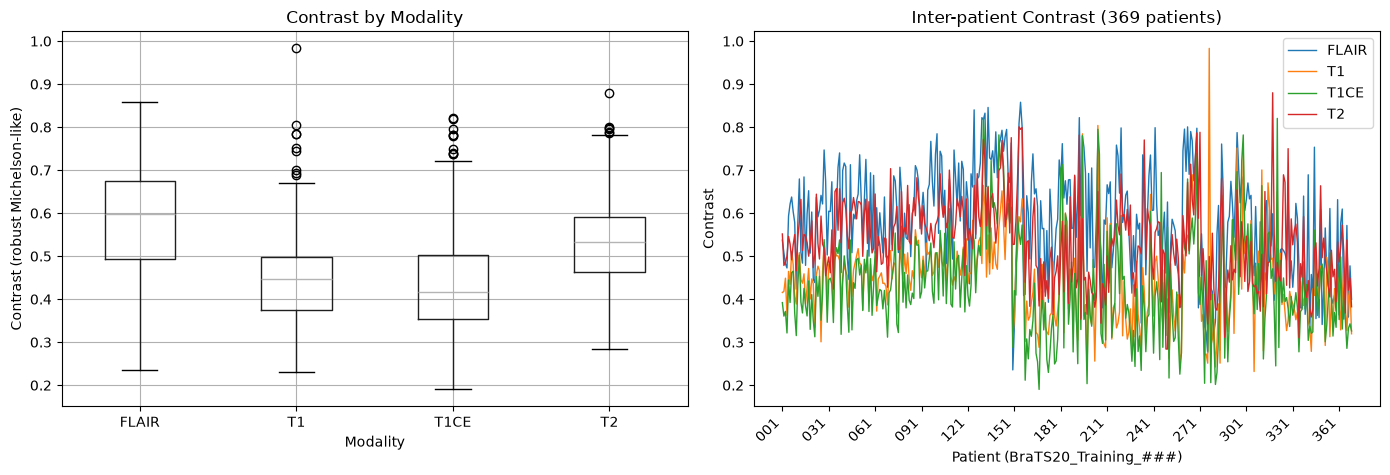

In [109]:
# Phase 5 — Cell 4: Contrast comparison across modalities / patients

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

image_quality_features_df.boxplot(column="contrast", by="modality", ax=axes[0])
axes[0].set_title("Contrast by Modality")
axes[0].set_xlabel("Modality")
axes[0].set_ylabel("Contrast (robust Michelson-like)")
fig.suptitle("")  # remove pandas auto title

# FULL COHORT: numeric x axis with thinned labels, as in Phase 4 Cell 7.
_ids_p5 = sorted(image_quality_features_df["patient_id"].unique())
_x_p5 = {pid: i for i, pid in enumerate(_ids_p5)}

for modality in PHASE5_MODALITIES:
    subset = (
        image_quality_features_df[image_quality_features_df["modality"] == modality]
        .assign(_x=lambda d: d["patient_id"].map(_x_p5))
        .sort_values("_x")
    )
    axes[1].plot(subset["_x"], subset["contrast"], linewidth=1.0, label=modality)

_step_p5 = max(1, len(_ids_p5) // 12)
_ticks_p5 = list(range(0, len(_ids_p5), _step_p5))
axes[1].set_xticks(_ticks_p5)
axes[1].set_xticklabels(
    [_ids_p5[i].replace("BraTS20_Training_", "") for i in _ticks_p5],
    rotation=45,
    ha="right",
)
axes[1].set_title(f"Inter-patient Contrast ({len(_ids_p5)} patients)")
axes[1].set_xlabel("Patient (BraTS20_Training_###)")
axes[1].set_ylabel("Contrast")
axes[1].legend()

plt.tight_layout()
plt.show()

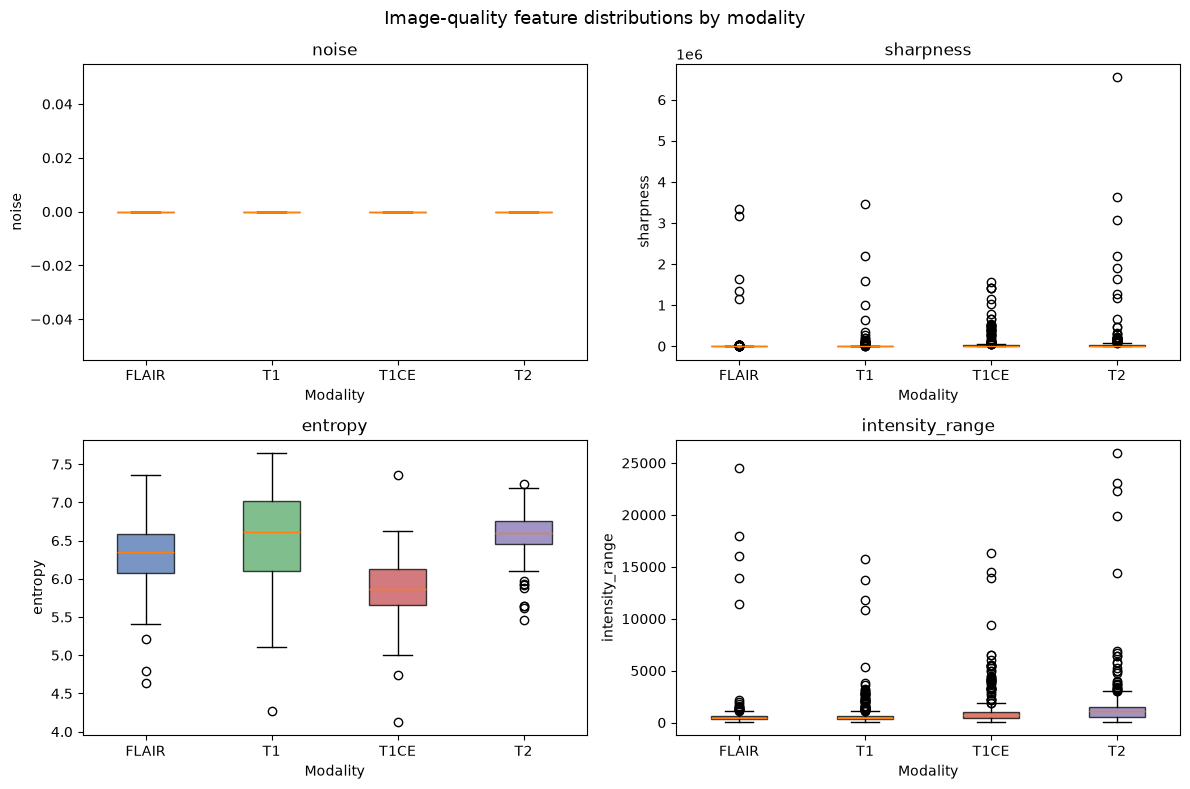

In [110]:
# Phase 5 — Cell 5: Noise / sharpness / entropy distributions by modality

metric_colors = {"FLAIR": "#4C72B0", "T1": "#55A868", "T1CE": "#C44E52", "T2": "#8172B2"}
metrics_to_plot = ["noise", "sharpness", "entropy", "intensity_range"]

fig, axes = plt.subplots(2, 2, figsize=(12, 8))
axes = axes.ravel()

for ax, metric in zip(axes, metrics_to_plot):
    data = [
        image_quality_features_df.loc[
            image_quality_features_df["modality"] == m, metric
        ].values
        for m in PHASE5_MODALITIES
    ]
    try:
        bp = ax.boxplot(data, tick_labels=PHASE5_MODALITIES, patch_artist=True)
    except TypeError:
        bp = ax.boxplot(data, labels=PHASE5_MODALITIES, patch_artist=True)
    for patch, modality in zip(bp["boxes"], PHASE5_MODALITIES):
        patch.set_facecolor(metric_colors[modality])
        patch.set_alpha(0.75)
    ax.set_title(metric)
    ax.set_xlabel("Modality")
    ax.set_ylabel(metric)

plt.suptitle("Image-quality feature distributions by modality", fontsize=13)
plt.tight_layout()
plt.show()

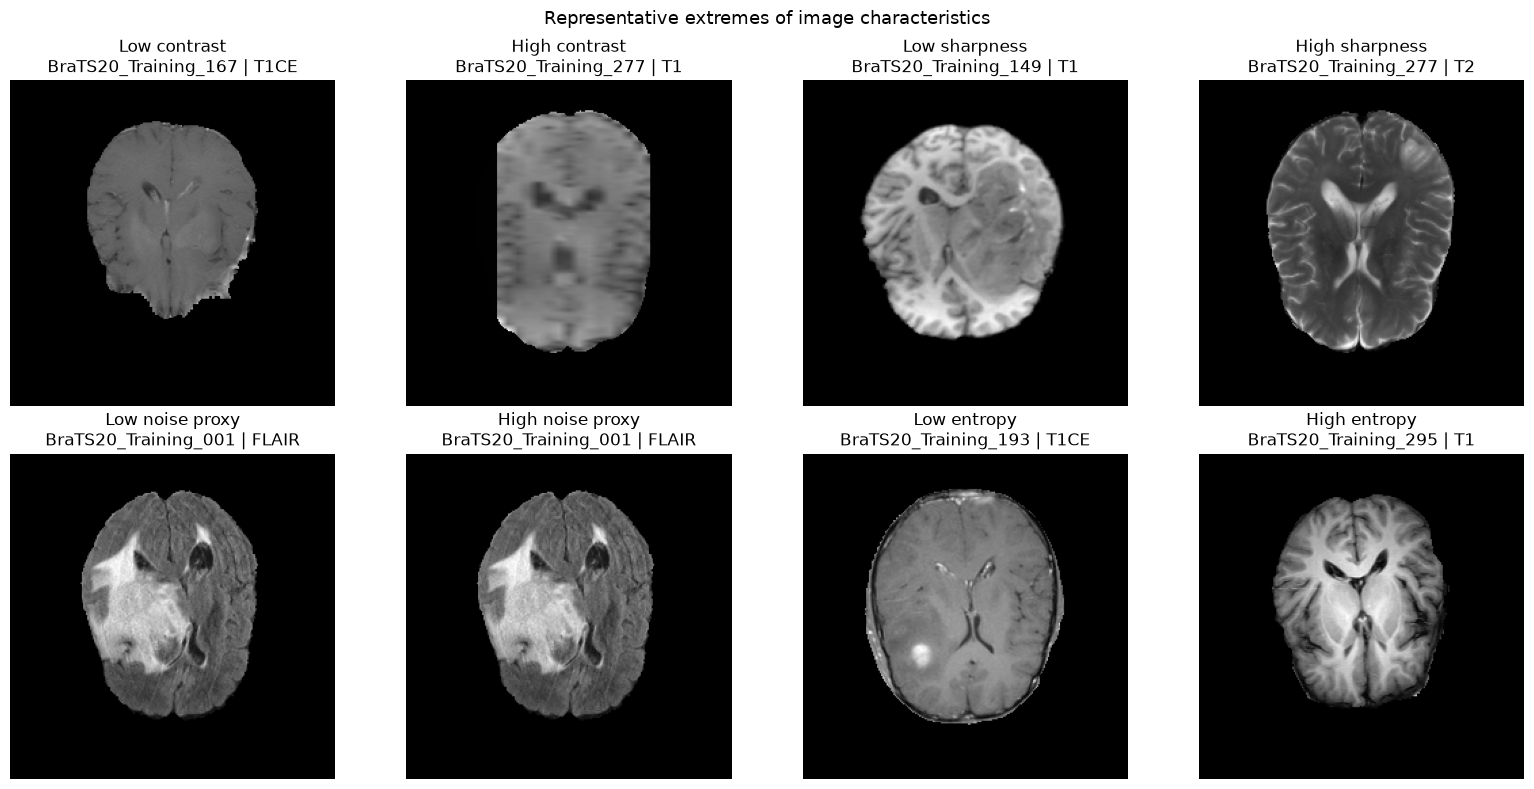

In [111]:
# Phase 5 — Cell 6: Representative low/high contrast and sharpness examples

def _show_example(patient_id, modality, title):
    patient_dir = os.path.join(DATASET_PATH, patient_id)
    volume = nib.load(resolve_nifti_path(patient_dir, modality)).get_fdata(dtype=np.float32)
    mid = volume.shape[2] // 2
    plt.imshow(np.rot90(volume[:, :, mid]), cmap="gray")
    plt.title(title)
    plt.axis("off")
    del volume


# Pick extremes from the feature table
low_c = image_quality_features_df.loc[image_quality_features_df["contrast"].idxmin()]
high_c = image_quality_features_df.loc[image_quality_features_df["contrast"].idxmax()]
low_s = image_quality_features_df.loc[image_quality_features_df["sharpness"].idxmin()]
high_s = image_quality_features_df.loc[image_quality_features_df["sharpness"].idxmax()]
low_n = image_quality_features_df.loc[image_quality_features_df["noise"].idxmin()]
high_n = image_quality_features_df.loc[image_quality_features_df["noise"].idxmax()]
low_e = image_quality_features_df.loc[image_quality_features_df["entropy"].idxmin()]
high_e = image_quality_features_df.loc[image_quality_features_df["entropy"].idxmax()]

fig = plt.figure(figsize=(16, 8))

examples = [
    (low_c, "Low contrast"),
    (high_c, "High contrast"),
    (low_s, "Low sharpness"),
    (high_s, "High sharpness"),
    (low_n, "Low noise proxy"),
    (high_n, "High noise proxy"),
    (low_e, "Low entropy"),
    (high_e, "High entropy"),
]

for i, (row, label) in enumerate(examples, start=1):
    plt.subplot(2, 4, i)
    _show_example(
        row["patient_id"],
        row["modality"],
        f"{label}\n{row['patient_id']} | {row['modality']}",
    )

plt.suptitle("Representative extremes of image characteristics", fontsize=13)
plt.tight_layout()
plt.show()

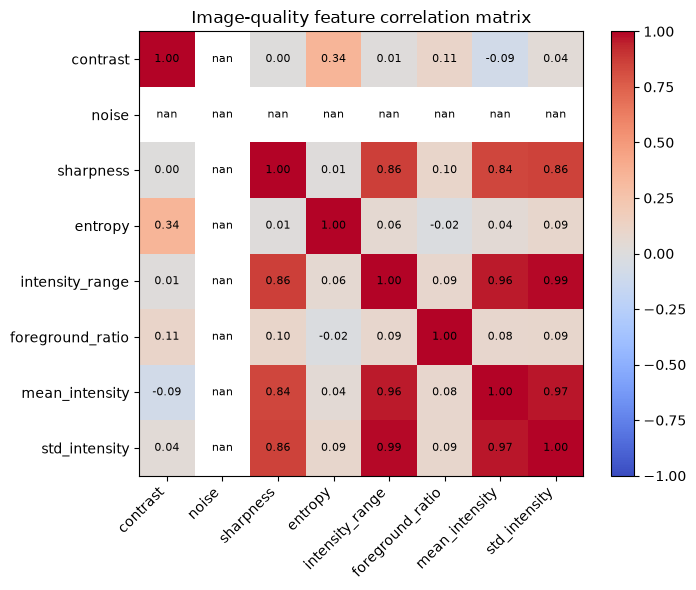

Correlation matrix:


,contrast,noise,sharpness,entropy,intensity_range,foreground_ratio,mean_intensity,std_intensity
contrast,1.000000,NaN,0.000287,0.344683,0.013983,0.106034,-0.085128,0.035097
noise,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
sharpness,0.000287,NaN,1.000000,0.010612,0.860230,0.097143,0.838304,0.856171
entropy,0.344683,NaN,0.010612,1.000000,0.056747,-0.023170,0.043531,0.086055
intensity_range,0.013983,NaN,0.860230,0.056747,1.000000,0.085042,0.959178,0.990092
foreground_ratio,0.106034,NaN,0.097143,-0.023170,0.085042,1.000000,0.082459,0.088619
mean_intensity,-0.085128,NaN,0.838304,0.043531,0.959178,0.082459,1.000000,0.966405
std_intensity,0.035097,NaN,0.856171,0.086055,0.990092,0.088619,0.966405,1.000000


In [112]:
# Phase 5 — Cell 7: Feature correlation matrix / heatmap

feature_cols = [
    "contrast",
    "noise",
    "sharpness",
    "entropy",
    "intensity_range",
    "foreground_ratio",
    "mean_intensity",
    "std_intensity",
]

corr_matrix = image_quality_features_df[feature_cols].corr()

fig, ax = plt.subplots(figsize=(8, 6))
im = ax.imshow(corr_matrix.values, cmap="coolwarm", vmin=-1, vmax=1)
ax.set_xticks(range(len(feature_cols)))
ax.set_yticks(range(len(feature_cols)))
ax.set_xticklabels(feature_cols, rotation=45, ha="right")
ax.set_yticklabels(feature_cols)
ax.set_title("Image-quality feature correlation matrix")

for i in range(len(feature_cols)):
    for j in range(len(feature_cols)):
        ax.text(j, i, f"{corr_matrix.values[i, j]:.2f}", ha="center", va="center", fontsize=8)

fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
plt.tight_layout()
plt.show()

print("Correlation matrix:")
display(corr_matrix)

In [113]:
# Phase 5 — Cell 8: Full-dataset extension hook (not executed over all patients here)

def extract_features_for_patient_list(patient_list, modalities=PHASE5_MODALITIES):
    """
    Reusable extractor for later full-dataset feature computation.
    Processes one volume at a time to limit memory use.
    """
    rows = []
    for patient_dir in patient_list:
        for modality in modalities:
            feats, volume = extract_image_quality_features(patient_dir, modality)
            rows.append(feats)
            del volume
    return pd.DataFrame(rows)


print("Full-dataset extension helper ready: extract_features_for_patient_list()")
print("Current Phase 5 table remains based on the representative subset.")

Full-dataset extension helper ready: extract_features_for_patient_list()
Current Phase 5 table remains based on the representative subset.


In [114]:
# Phase 5 — Cell 9: Final EDA summary + persist/display feature table

# Variation summaries
overall_variation = image_quality_features_df[feature_cols].std().sort_values(ascending=False)
modality_variation = (
    image_quality_features_df.groupby("modality")[feature_cols].mean().std().sort_values(ascending=False)
)
patient_variation = (
    image_quality_features_df.groupby("patient_id")[feature_cols].mean().std().sort_values(ascending=False)
)

print("=== Phase 5 Final EDA Summary ===")
print("Characteristics with highest overall variation:")
print(overall_variation.head(5).to_string())

print("\nCharacteristics with highest between-modality variation (via modality-mean spread):")
print(modality_variation.head(5).to_string())

print("\nCharacteristics with highest between-patient variation (via patient-mean spread):")
print(patient_variation.head(5).to_string())

print(
    "\nSubstantial inter-patient variation is present when patient-level spreads are non-trivial "
    "relative to modality-level spreads; both modality identity and patient-specific appearance "
    "should inform later adaptive preprocessing selection."
)
print(
    "Useful candidate inputs for the Adaptive Preprocessing Selector include: "
    "contrast, noise, sharpness, entropy, intensity_range, foreground_ratio, "
    "mean_intensity, and std_intensity."
)
print(
    "Note: these features characterize images only; no preprocessing method is selected in Phase 5."
)

print("\nPhase 5 — EDA Completed")
print("\nFinal image-characteristics feature table:")
display(image_quality_features_df)

=== Phase 5 Final EDA Summary ===
Characteristics with highest overall variation:
sharpness          309225.728219
intensity_range      2007.364327
mean_intensity       1201.782561
std_intensity         381.603284
entropy                 0.485978

Characteristics with highest between-modality variation (via modality-mean spread):
sharpness          27079.209750
intensity_range      372.419697
mean_intensity       150.414344
std_intensity         66.034444
entropy                0.325726

Characteristics with highest between-patient variation (via patient-mean spread):
sharpness          271307.945138
intensity_range      1822.864254
mean_intensity       1128.388109
std_intensity         351.270445
entropy                 0.232675

Substantial inter-patient variation is present when patient-level spreads are non-trivial relative to modality-level spreads; both modality identity and patient-specific appearance should inform later adaptive preprocessing selection.
Useful candidate inputs 

,patient_id,modality,contrast,noise,sharpness,entropy,intensity_range,foreground_ratio,background_ratio,mean_intensity,std_intensity,median_intensity,p5,p95
0,BraTS20_Training_001,FLAIR,0.537349,0.0,1393.426875,6.500718,325.000000,0.150413,0.849587,173.003387,64.865944,158.000000,96.000000,319.000000
1,BraTS20_Training_001,T1,0.415565,0.0,3634.585243,7.008292,369.000000,0.150413,0.849587,354.272705,84.187027,357.000000,199.000000,482.000000
2,BraTS20_Training_001,T1CE,0.392060,0.0,9171.272708,5.853388,617.000000,0.150413,0.849587,417.329224,109.193008,417.000000,245.000000,561.000000
3,BraTS20_Training_001,T2,0.551601,0.0,363.188056,6.685855,209.000000,0.150413,0.849587,114.693985,47.691029,101.000000,63.000000,218.000000
4,BraTS20_Training_002,FLAIR,0.507692,0.0,4234.578785,6.318954,553.000000,0.172401,0.827599,286.488068,93.422981,277.000000,144.000000,441.000000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1471,BraTS20_Training_368,T2,0.448990,0.0,153693.905174,6.374935,3077.360000,0.152807,0.847193,1751.714111,539.095581,1664.000000,1064.000000,2798.000000
1472,BraTS20_Training_369,FLAIR,0.399902,0.0,23800.621389,6.310390,1305.000000,0.206191,0.793809,1025.578125,229.849533,1025.000000,610.000000,1423.000000
1473,BraTS20_Training_369,T1,0.319608,0.0,26545.705516,6.472890,1143.046802,0.206191,0.793809,1090.680054,209.212906,1100.693481,717.171997,1390.943115
1474,BraTS20_Training_369,T1CE,0.326215,0.0,787416.578403,6.219146,6514.000000,0.206191,0.793809,5092.982910,1086.183838,5165.000000,3250.000000,6397.000000


In [115]:
# Phase 6 — Cell 1: Configuration and feature columns used by the selector
# Purpose: set up the Adaptive Preprocessing Selector inputs from Phase 5 features.

SELECTOR_FEATURE_COLS = [
    "contrast",
    "noise",
    "sharpness",
    "entropy",
    "intensity_range",
    "foreground_ratio",
    "mean_intensity",
    "std_intensity",
]

# Reuse Phase 5 feature table
assert "image_quality_features_df" in globals(), (
    "Phase 5 feature table 'image_quality_features_df' not found. Run Phase 5 first."
)

selector_input_df = image_quality_features_df.copy()

print("=== Phase 6 Selector Inputs ===")
print(f"Feature rows available : {len(selector_input_df)}")
print(f"Selector feature cols  : {SELECTOR_FEATURE_COLS}")
display(selector_input_df[["patient_id", "modality"] + SELECTOR_FEATURE_COLS].head())

=== Phase 6 Selector Inputs ===
Feature rows available : 1476
Selector feature cols  : ['contrast', 'noise', 'sharpness', 'entropy', 'intensity_range', 'foreground_ratio', 'mean_intensity', 'std_intensity']


,patient_id,modality,contrast,noise,sharpness,entropy,intensity_range,foreground_ratio,mean_intensity,std_intensity
0,BraTS20_Training_001,FLAIR,0.537349,0.0,1393.426875,6.500718,325.0,0.150413,173.003387,64.865944
1,BraTS20_Training_001,T1,0.415565,0.0,3634.585243,7.008292,369.0,0.150413,354.272705,84.187027
2,BraTS20_Training_001,T1CE,0.392060,0.0,9171.272708,5.853388,617.0,0.150413,417.329224,109.193008
3,BraTS20_Training_001,T2,0.551601,0.0,363.188056,6.685855,209.0,0.150413,114.693985,47.691029
4,BraTS20_Training_002,FLAIR,0.507692,0.0,4234.578785,6.318954,553.0,0.172401,286.488068,93.422981


In [116]:
# Phase 6 — Cell 2: Define candidate preprocessing pipelines
# Purpose: declare a small, justified set of pipelines based on Phase 3–5 findings
# (background dominance, modality/patient intensity variation, contrast/noise differences).

CANDIDATE_PIPELINES = {
    "P1_robust_norm": {
        "description": "Foreground-aware robust intensity normalization (percentile-based).",
        "operations": ["robust_normalize"],
        "rationale": (
            "Baseline for MRI volumes with large background regions and inter-patient "
            "intensity scale differences."
        ),
    },
    "P2_norm_contrast": {
        "description": "Robust normalization + contrast enhancement.",
        "operations": ["robust_normalize", "contrast_enhance"],
        "rationale": (
            "Useful when contrast is low relative to the cohort, while noise remains moderate."
        ),
    },
    "P3_denoise_norm": {
        "description": "Denoising + robust normalization.",
        "operations": ["denoise", "robust_normalize"],
        "rationale": (
            "Useful when the noise proxy is elevated and aggressive contrast enhancement "
            "could amplify artifacts."
        ),
    },
    "P4_denoise_contrast_norm": {
        "description": "Denoising + contrast enhancement + robust normalization.",
        "operations": ["denoise", "contrast_enhance", "robust_normalize"],
        "rationale": (
            "Reserved for jointly challenging cases with high noise proxy and low contrast."
        ),
    },
}

print("=== Candidate Preprocessing Pipelines ===")
for pid, meta in CANDIDATE_PIPELINES.items():
    print(f"\n{pid}")
    print(f"  Description : {meta['description']}")
    print(f"  Operations  : {' -> '.join(meta['operations'])}")
    print(f"  Rationale   : {meta['rationale']}")

=== Candidate Preprocessing Pipelines ===

P1_robust_norm
  Description : Foreground-aware robust intensity normalization (percentile-based).
  Operations  : robust_normalize
  Rationale   : Baseline for MRI volumes with large background regions and inter-patient intensity scale differences.

P2_norm_contrast
  Description : Robust normalization + contrast enhancement.
  Operations  : robust_normalize -> contrast_enhance
  Rationale   : Useful when contrast is low relative to the cohort, while noise remains moderate.

P3_denoise_norm
  Description : Denoising + robust normalization.
  Operations  : denoise -> robust_normalize
  Rationale   : Useful when the noise proxy is elevated and aggressive contrast enhancement could amplify artifacts.

P4_denoise_contrast_norm
  Description : Denoising + contrast enhancement + robust normalization.
  Operations  : denoise -> contrast_enhance -> robust_normalize
  Rationale   : Reserved for jointly challenging cases with high noise proxy and low c

In [117]:
# Phase 6 — Cell 3: Reusable preprocessing operations
# Purpose: implement modular operations. These modify copies only; originals stay unchanged.

def robust_normalize(volume, low_q=1, high_q=99):
    """
    Percentile-based normalization on foreground voxels.
    Background (zeros) remains zero. Output is float32 in ~[0, 1] for foreground.
    """
    out = volume.astype(np.float32, copy=True)
    fg_mask = out != 0
    if not np.any(fg_mask):
        return out

    lo, hi = np.percentile(out[fg_mask], [low_q, high_q])
    if hi <= lo:
        hi = lo + 1e-8

    fg = np.clip(out[fg_mask], lo, hi)
    out[fg_mask] = (fg - lo) / (hi - lo)
    return out


def denoise(volume, sigma=0.8):
    """
    Light Gaussian denoising applied slice-wise.
    Conservative by design so tissue boundaries are not heavily smoothed.
    """
    vol = volume.astype(np.float32, copy=True)
    denoised = np.empty_like(vol)
    ksize = 0  # let OpenCV choose from sigma
    for z in range(vol.shape[2]):
        denoised[:, :, z] = cv2.GaussianBlur(vol[:, :, z], (0, 0), sigmaX=sigma, sigmaY=sigma)
    # Preserve exact zeros as background
    denoised[volume == 0] = 0
    return denoised


def contrast_enhance(volume, clip_limit=2.0, tile_grid_size=(8, 8)):
    """
    CLAHE contrast enhancement applied slice-wise.
    Operates on a temporary 8-bit mapping of the current volume intensities.
    """
    vol = volume.astype(np.float32, copy=True)
    enhanced = np.zeros_like(vol)
    clahe = cv2.createCLAHE(clipLimit=clip_limit, tileGridSize=tile_grid_size)

    for z in range(vol.shape[2]):
        sl = vol[:, :, z]
        fg = sl != 0
        if not np.any(fg):
            continue

        # Map current slice foreground to uint8 for CLAHE, then map back to [0, 1]-like scale
        s_min, s_max = float(sl[fg].min()), float(sl[fg].max())
        if s_max <= s_min:
            enhanced[:, :, z] = sl
            continue

        scaled = np.zeros_like(sl, dtype=np.uint8)
        scaled[fg] = np.clip(((sl[fg] - s_min) / (s_max - s_min)) * 255.0, 0, 255).astype(np.uint8)
        clahe_slice = clahe.apply(scaled).astype(np.float32) / 255.0
        out_slice = np.zeros_like(sl, dtype=np.float32)
        out_slice[fg] = clahe_slice[fg]
        enhanced[:, :, z] = out_slice

    return enhanced


PREPROCESS_OPS = {
    "robust_normalize": robust_normalize,
    "denoise": denoise,
    "contrast_enhance": contrast_enhance,
}


def apply_pipeline(volume, pipeline_id, pipelines=CANDIDATE_PIPELINES):
    """Apply a named candidate pipeline to a 3D MRI volume (returns a new array)."""
    if pipeline_id not in pipelines:
        raise KeyError(f"Unknown pipeline: {pipeline_id}")

    result = volume.astype(np.float32, copy=True)
    for op_name in pipelines[pipeline_id]["operations"]:
        result = PREPROCESS_OPS[op_name](result)
    return result


print("Preprocessing operations ready:", list(PREPROCESS_OPS.keys()))

Preprocessing operations ready: ['robust_normalize', 'denoise', 'contrast_enhance']


In [118]:
# Phase 6 — Cell 4: Cohort reference statistics for modular scoring
# Purpose: compute cohort percentiles so selection is relative, not absolute hard thresholds.

cohort_refs = {}
for col in ["contrast", "noise", "sharpness", "entropy", "std_intensity"]:
    values = selector_input_df[col].astype(float)
    cohort_refs[col] = {
        "p25": float(np.nanpercentile(values, 25)),
        "p50": float(np.nanpercentile(values, 50)),
        "p75": float(np.nanpercentile(values, 75)),
    }

print("=== Cohort Reference Percentiles ===")
display(pd.DataFrame(cohort_refs).T)

=== Cohort Reference Percentiles ===


,p25,p50,p75
contrast,0.409206,0.489376,0.585979
noise,0.000000,0.000000,0.000000
sharpness,2305.505521,5001.243958,16735.323889
entropy,5.989445,6.374215,6.686132
std_intensity,73.959967,110.991032,195.076149


In [119]:
# Phase 6 — Cell 5: Modular adaptive selection mechanism (score-based prototype)
# Purpose: score each pipeline from image features. This is NOT a trained ML model yet,
# but is modular so scoring can later be replaced by a learned selector.

def _relative_level(value, ref):
    """Map a feature value to low/mid/high relative to cohort quartiles."""
    if pd.isna(value):
        return "unknown"
    if value <= ref["p25"]:
        return "low"
    if value >= ref["p75"]:
        return "high"
    return "mid"


def score_pipelines(feature_row, refs=cohort_refs):
    """
    Return a score dictionary for all candidate pipelines.

    Higher score => currently preferred prototype choice.
    Scoring is intentionally transparent and editable for later experiments.
    """
    contrast_lvl = _relative_level(feature_row["contrast"], refs["contrast"])
    noise_lvl = _relative_level(feature_row["noise"], refs["noise"])
    sharp_lvl = _relative_level(feature_row["sharpness"], refs["sharpness"])
    entropy_lvl = _relative_level(feature_row["entropy"], refs["entropy"])

    scores = {
        "P1_robust_norm": 1.0,              # always a valid baseline
        "P2_norm_contrast": 0.0,
        "P3_denoise_norm": 0.0,
        "P4_denoise_contrast_norm": 0.0,
    }

    # Contrast-driven evidence
    if contrast_lvl == "low":
        scores["P2_norm_contrast"] += 2.0
        scores["P4_denoise_contrast_norm"] += 1.5
        scores["P1_robust_norm"] -= 0.25
    elif contrast_lvl == "high":
        scores["P1_robust_norm"] += 0.75
        scores["P2_norm_contrast"] -= 0.50

    # Noise-driven evidence
    if noise_lvl == "high":
        scores["P3_denoise_norm"] += 2.0
        scores["P4_denoise_contrast_norm"] += 1.5
        scores["P2_norm_contrast"] -= 0.50  # avoid enhancing noise
    elif noise_lvl == "low":
        scores["P1_robust_norm"] += 0.50
        scores["P3_denoise_norm"] -= 0.25

    # Sharpness / entropy as secondary cues
    if sharp_lvl == "low":
        scores["P2_norm_contrast"] += 0.50
        scores["P4_denoise_contrast_norm"] += 0.25
    if entropy_lvl == "high" and noise_lvl == "high":
        scores["P3_denoise_norm"] += 0.50

    # Joint difficult case: low contrast + high noise
    if contrast_lvl == "low" and noise_lvl == "high":
        scores["P4_denoise_contrast_norm"] += 2.0
        scores["P2_norm_contrast"] -= 0.50
        scores["P3_denoise_norm"] += 0.50

    return scores


def select_preprocessing_pipeline(feature_row, refs=cohort_refs):
    """
    Select the top-scoring pipeline for one patient/modality feature row.
    Ties are broken by a stable priority order.
    """
    scores = score_pipelines(feature_row, refs=refs)
    priority = [
        "P4_denoise_contrast_norm",
        "P3_denoise_norm",
        "P2_norm_contrast",
        "P1_robust_norm",
    ]
    best_score = max(scores.values())
    candidates = [pid for pid, sc in scores.items() if np.isclose(sc, best_score)]
    for pid in priority:
        if pid in candidates:
            selected = pid
            break
    else:
        selected = candidates[0]

    return selected, scores


# Smoke test on first row
_demo_row = selector_input_df.iloc[0]
_demo_selected, _demo_scores = select_preprocessing_pipeline(_demo_row)
print("Smoke test patient/modality:", _demo_row["patient_id"], _demo_row["modality"])
print("Selected pipeline:", _demo_selected)
print("Scores:", _demo_scores)

Smoke test patient/modality: BraTS20_Training_001 FLAIR
Selected pipeline: P1_robust_norm
Scores: {'P1_robust_norm': 1.5, 'P2_norm_contrast': 0.5, 'P3_denoise_norm': -0.25, 'P4_denoise_contrast_norm': 0.25}


In [120]:
# Phase 6 — Cell 6: Run selector on all Phase 5 representative patient/modality rows
# Purpose: produce a reusable selection table for later phases.

selection_rows = []

for _, row in selector_input_df.iterrows():
    selected_pipeline, scores = select_preprocessing_pipeline(row)
    record = {
        "patient_id": row["patient_id"],
        "modality": row["modality"],
        "selected_pipeline": selected_pipeline,
        "selected_pipeline_description": CANDIDATE_PIPELINES[selected_pipeline]["description"],
    }
    # Keep characteristics used by the selector
    for col in SELECTOR_FEATURE_COLS:
        record[col] = row[col]
    # Store scores for transparency / later analysis
    for pid, sc in scores.items():
        record[f"score_{pid}"] = sc
    selection_rows.append(record)

# Primary reusable artifact for later phases
adaptive_preprocessing_selection_df = pd.DataFrame(selection_rows)

print("=== Adaptive Preprocessing Selection Table ===")
print(f"Rows: {len(adaptive_preprocessing_selection_df)} "
      f"(one per patient/modality across the full cohort)")
display(
    adaptive_preprocessing_selection_df[
        ["patient_id", "modality"] + SELECTOR_FEATURE_COLS + ["selected_pipeline"]
    ].head(12)
)

=== Adaptive Preprocessing Selection Table ===
Rows: 1476 (one per patient/modality across the full cohort)


,patient_id,modality,contrast,noise,sharpness,entropy,intensity_range,foreground_ratio,mean_intensity,std_intensity,selected_pipeline
0,BraTS20_Training_001,FLAIR,0.537349,0.0,1393.426875,6.500718,325.0,0.150413,173.003387,64.865944,P1_robust_norm
1,BraTS20_Training_001,T1,0.415565,0.0,3634.585243,7.008292,369.0,0.150413,354.272705,84.187027,P1_robust_norm
2,BraTS20_Training_001,T1CE,0.392060,0.0,9171.272708,5.853388,617.0,0.150413,417.329224,109.193008,P2_norm_contrast
3,BraTS20_Training_001,T2,0.551601,0.0,363.188056,6.685855,209.0,0.150413,114.693985,47.691029,P1_robust_norm
4,BraTS20_Training_002,FLAIR,0.507692,0.0,4234.578785,6.318954,553.0,0.172401,286.488068,93.422981,P1_robust_norm
5,BraTS20_Training_002,T1,0.418367,0.0,4306.122326,7.097976,430.0,0.172401,411.141479,99.469818,P1_robust_norm
6,BraTS20_Training_002,T1CE,0.360656,0.0,11389.571493,5.997176,719.0,0.172401,444.888367,115.306511,P2_norm_contrast
7,BraTS20_Training_002,T2,0.478458,0.0,2327.312882,6.455092,376.0,0.172401,190.384155,69.930916,P1_robust_norm
8,BraTS20_Training_003,FLAIR,0.482143,0.0,2818.046111,6.584311,397.0,0.141254,308.928284,76.558640,P1_robust_norm
9,BraTS20_Training_003,T1,0.448864,0.0,4778.172569,7.080804,418.0,0.141254,383.762665,93.544136,P1_robust_norm


=== Selected Pipeline Distribution ===


,selected_pipeline,count,proportion
0,P1_robust_norm,1107,0.75
1,P2_norm_contrast,369,0.25


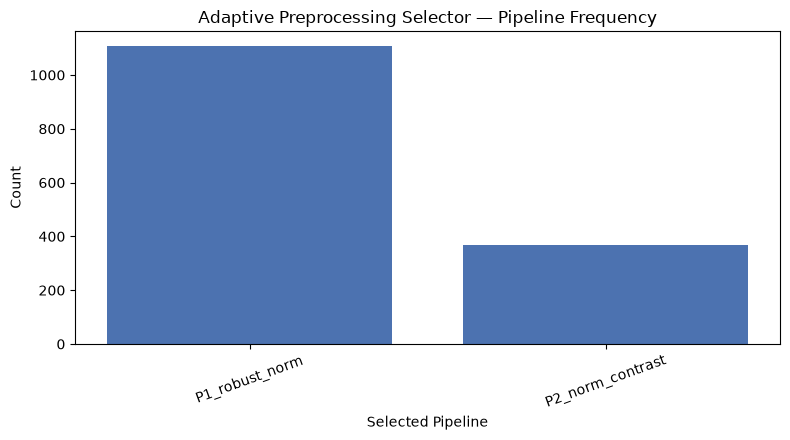

In [121]:
# Phase 6 — Cell 7: Pipeline selection frequency summary
# Purpose: show how often each candidate pipeline is chosen on the representative set.

pipeline_counts = (
    adaptive_preprocessing_selection_df["selected_pipeline"]
    .value_counts()
    .rename_axis("selected_pipeline")
    .reset_index(name="count")
)
pipeline_counts["proportion"] = pipeline_counts["count"] / pipeline_counts["count"].sum()

print("=== Selected Pipeline Distribution ===")
display(pipeline_counts)

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.bar(pipeline_counts["selected_pipeline"], pipeline_counts["count"], color="#4C72B0")
ax.set_title("Adaptive Preprocessing Selector — Pipeline Frequency")
ax.set_xlabel("Selected Pipeline")
ax.set_ylabel("Count")
ax.tick_params(axis="x", rotation=20)
plt.tight_layout()
plt.show()

In [122]:
# Phase 6 — Cell 8: Apply selected preprocessing to representative images
# Purpose: generate preprocessed outputs for visualization/prototype validation.
# Loads one volume at a time; stores only middle-slice previews to limit memory.

preview_records = []
MAX_PREVIEW_ROWS = min(8, len(adaptive_preprocessing_selection_df))

for _, row in adaptive_preprocessing_selection_df.head(MAX_PREVIEW_ROWS).iterrows():
    patient_dir = os.path.join(DATASET_PATH, row["patient_id"])
    original = nib.load(
        resolve_nifti_path(patient_dir, row["modality"])
    ).get_fdata(dtype=np.float32)

    preprocessed = apply_pipeline(original, row["selected_pipeline"])
    mid = original.shape[2] // 2

    preview_records.append(
        {
            "patient_id": row["patient_id"],
            "modality": row["modality"],
            "selected_pipeline": row["selected_pipeline"],
            "original_slice": original[:, :, mid].copy(),
            "preprocessed_slice": preprocessed[:, :, mid].copy(),
        }
    )
    del original, preprocessed

print(f"Prepared {len(preview_records)} original/preprocessed slice previews.")

Prepared 8 original/preprocessed slice previews.


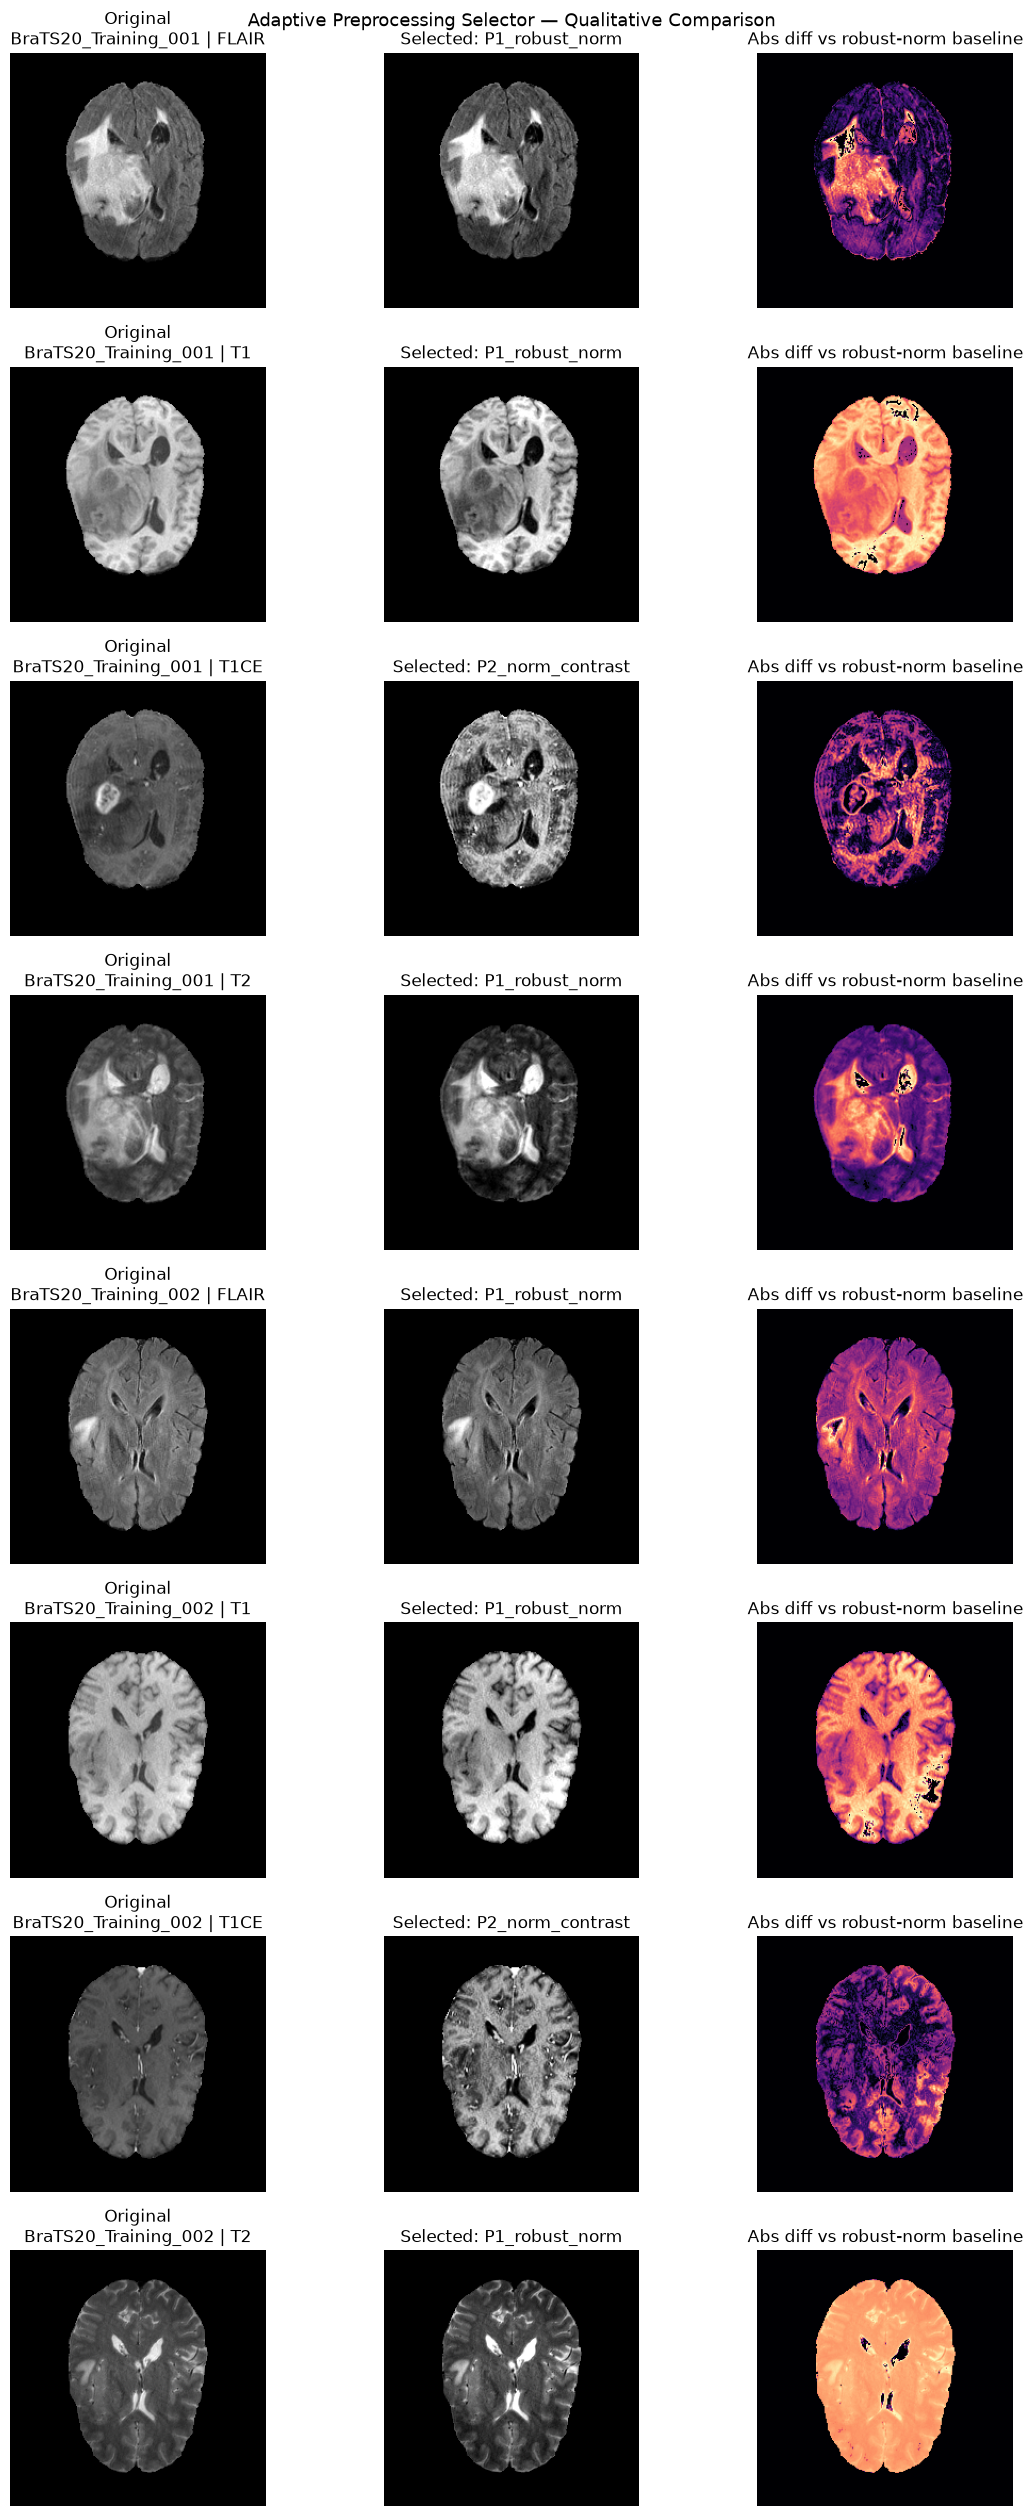

In [123]:
# Phase 6 — Cell 9: Visualize original vs selected-preprocessing results
# Purpose: qualitative inspection of selector decisions (not a performance claim).

n = len(preview_records)
fig, axes = plt.subplots(n, 3, figsize=(12, 3.2 * n))
if n == 1:
    axes = np.expand_dims(axes, axis=0)

for i, rec in enumerate(preview_records):
    orig = rec["original_slice"]
    prep = rec["preprocessed_slice"]
    diff = np.abs(prep - robust_normalize(orig))  # highlight change vs normalize-only baseline

    axes[i, 0].imshow(np.rot90(orig), cmap="gray")
    axes[i, 0].set_title(f"Original\n{rec['patient_id']} | {rec['modality']}")
    axes[i, 0].axis("off")

    axes[i, 1].imshow(np.rot90(prep), cmap="gray")
    axes[i, 1].set_title(f"Selected: {rec['selected_pipeline']}")
    axes[i, 1].axis("off")

    axes[i, 2].imshow(np.rot90(diff), cmap="magma")
    axes[i, 2].set_title("Abs diff vs robust-norm baseline")
    axes[i, 2].axis("off")

plt.suptitle("Adaptive Preprocessing Selector — Qualitative Comparison", fontsize=13)
plt.tight_layout()
plt.show()

In [124]:
# Phase 6 — Cell 10: Convenience API for later phases + final summary
# Purpose: preserve a clean callable interface and summarize Phase 6 outcomes.

def adaptive_select_and_preprocess(patient_dir, modality, feature_row=None):
    """
    End-to-end helper for later phases:
      features -> pipeline selection -> preprocessed volume
    If feature_row is None, features are computed with the Phase 5 extractor.
    """
    if feature_row is None:
        feats, volume = extract_image_quality_features(patient_dir, modality)
        feature_row = pd.Series(feats)
    else:
        volume = nib.load(resolve_nifti_path(patient_dir, modality)).get_fdata(dtype=np.float32)

    selected_pipeline, scores = select_preprocessing_pipeline(feature_row)
    preprocessed = apply_pipeline(volume, selected_pipeline)
    return {
        "patient_id": os.path.basename(patient_dir),
        "modality": modality,
        "selected_pipeline": selected_pipeline,
        "scores": scores,
        "original_volume": volume,
        "preprocessed_volume": preprocessed,
    }


print("=== Phase 6 Summary ===")
print("Available preprocessing pipelines:")
for pid, meta in CANDIDATE_PIPELINES.items():
    print(f"  - {pid}: {meta['description']}")

print(
    "\nSelection logic: modular relative scoring against cohort quartiles "
    "(contrast/noise primary; sharpness/entropy secondary; joint low-contrast+high-noise boosts P4). "
    "This is a transparent prototype, not a trained or validated optimum."
)

print("\nSelected pipelines for representative images:")
display(
    adaptive_preprocessing_selection_df[
        ["patient_id", "modality", "selected_pipeline"]
    ]
)

print("\nDistribution of selected pipelines:")
display(pipeline_counts)

print("\nReusable objects for later phases:")
print("  - CANDIDATE_PIPELINES")
print("  - adaptive_preprocessing_selection_df")
print("  - select_preprocessing_pipeline()")
print("  - apply_pipeline()")
print("  - adaptive_select_and_preprocess()")

print("\nPhase 6 — Adaptive Preprocessing Selector Completed")

=== Phase 6 Summary ===
Available preprocessing pipelines:
  - P1_robust_norm: Foreground-aware robust intensity normalization (percentile-based).
  - P2_norm_contrast: Robust normalization + contrast enhancement.
  - P3_denoise_norm: Denoising + robust normalization.
  - P4_denoise_contrast_norm: Denoising + contrast enhancement + robust normalization.

Selection logic: modular relative scoring against cohort quartiles (contrast/noise primary; sharpness/entropy secondary; joint low-contrast+high-noise boosts P4). This is a transparent prototype, not a trained or validated optimum.

Selected pipelines for representative images:


,patient_id,modality,selected_pipeline
0,BraTS20_Training_001,FLAIR,P1_robust_norm
1,BraTS20_Training_001,T1,P1_robust_norm
2,BraTS20_Training_001,T1CE,P2_norm_contrast
3,BraTS20_Training_001,T2,P1_robust_norm
4,BraTS20_Training_002,FLAIR,P1_robust_norm
...,...,...,...
1471,BraTS20_Training_368,T2,P1_robust_norm
1472,BraTS20_Training_369,FLAIR,P2_norm_contrast
1473,BraTS20_Training_369,T1,P2_norm_contrast
1474,BraTS20_Training_369,T1CE,P2_norm_contrast



Distribution of selected pipelines:


,selected_pipeline,count,proportion
0,P1_robust_norm,1107,0.75
1,P2_norm_contrast,369,0.25



Reusable objects for later phases:
  - CANDIDATE_PIPELINES
  - adaptive_preprocessing_selection_df
  - select_preprocessing_pipeline()
  - apply_pipeline()
  - adaptive_select_and_preprocess()

Phase 6 — Adaptive Preprocessing Selector Completed


In [125]:
# Phase 7 — Cell 1: Preconditions and configuration
# Purpose: confirm Phase 5/6 artifacts exist and define the Phase 7 execution subset.

required_phase6_objects = [
    "CANDIDATE_PIPELINES",
    "select_preprocessing_pipeline",
    "apply_pipeline",
    "adaptive_preprocessing_selection_df",
    "SELECTOR_FEATURE_COLS",
]
missing = [name for name in required_phase6_objects if name not in globals()]
assert not missing, f"Missing Phase 6 objects: {missing}. Run Phase 6 first."

# FULL COHORT: execution/validation runs over the same full cohort Phases 4-6
# used. Set PHASE7_MAX_ROWS to an integer if you want to cap the (slow) CLAHE
# pass for a quick check; None runs every patient/modality.
phase7_patients = selected_patients if "selected_patients" in globals() else [first_patient]
phase7_modalities = ["FLAIR", "T1", "T1CE", "T2"]
PHASE7_MAX_ROWS = None

print("=== Phase 7 Configuration (full dataset) ===")
print(f"Patients in execution set    : {len(phase7_patients)}")
print(f"Row cap                      : {PHASE7_MAX_ROWS or 'none (all rows)'}")
print(f"Modalities                   : {phase7_modalities}")
print(f"Candidate pipelines          : {list(CANDIDATE_PIPELINES.keys())}")

=== Phase 7 Configuration (full dataset) ===
Patients in execution set    : 369
Row cap                      : none (all rows)
Modalities                   : ['FLAIR', 'T1', 'T1CE', 'T2']
Candidate pipelines          : ['P1_robust_norm', 'P2_norm_contrast', 'P3_denoise_norm', 'P4_denoise_contrast_norm']


In [126]:
# Phase 7 — Cell 2: Clean preprocessing execution API
# Purpose: one reusable function that selects + applies a pipeline and returns metadata.
# Designed so it can later move into preprocessing_selector.py / preprocessing_pipelines.py.

def execute_adaptive_preprocessing(volume, feature_row, pipelines=CANDIDATE_PIPELINES):
    """
    Execute adaptive preprocessing for one MRI volume.

    Parameters
    ----------
    volume : np.ndarray
        Original 3D MRI volume (left unmodified).
    feature_row : pd.Series or dict-like
        Phase-5 image characteristics for this volume.
    pipelines : dict
        Candidate pipeline registry from Phase 6.

    Returns
    -------
    dict with:
      - preprocessed_volume
      - selected_pipeline
      - selected_pipeline_description
      - selection_scores
    """
    feature_row = pd.Series(feature_row)
    selected_pipeline, scores = select_preprocessing_pipeline(feature_row)
    preprocessed_volume = apply_pipeline(
        volume.astype(np.float32, copy=True),
        selected_pipeline,
        pipelines=pipelines,
    )

    return {
        "preprocessed_volume": preprocessed_volume,
        "selected_pipeline": selected_pipeline,
        "selected_pipeline_description": pipelines[selected_pipeline]["description"],
        "selection_scores": scores,
    }


print("Execution API ready: execute_adaptive_preprocessing()")

Execution API ready: execute_adaptive_preprocessing()


In [127]:
# Phase 7 — Cell 3: Build structured preprocessing-decision DataFrame
# Purpose: preserve patient/modality decisions + Phase 5 characteristics for Phase 8.

# Prefer the already computed Phase 6 table; filter to the Phase 7 patient subset
phase7_patient_ids = {os.path.basename(p) for p in phase7_patients}

preprocessing_decision_df = adaptive_preprocessing_selection_df[
    adaptive_preprocessing_selection_df["patient_id"].isin(phase7_patient_ids)
].copy()

# Ensure required columns exist
keep_cols = (
    ["patient_id", "modality", "selected_pipeline"]
    + [c for c in SELECTOR_FEATURE_COLS if c in preprocessing_decision_df.columns]
)
preprocessing_decision_df = preprocessing_decision_df[keep_cols].reset_index(drop=True)

# FULL COHORT: optional cap, deterministic (head, not a sample) so the row set
# matches between runs.
if PHASE7_MAX_ROWS is not None:
    preprocessing_decision_df = preprocessing_decision_df.head(PHASE7_MAX_ROWS)

print("=== Preprocessing Decision Table (Phase 7) ===")
display(preprocessing_decision_df.head(12))
print(f"Rows: {len(preprocessing_decision_df)}")

=== Preprocessing Decision Table (Phase 7) ===


,patient_id,modality,selected_pipeline,contrast,noise,sharpness,entropy,intensity_range,foreground_ratio,mean_intensity,std_intensity
0,BraTS20_Training_001,FLAIR,P1_robust_norm,0.537349,0.0,1393.426875,6.500718,325.0,0.150413,173.003387,64.865944
1,BraTS20_Training_001,T1,P1_robust_norm,0.415565,0.0,3634.585243,7.008292,369.0,0.150413,354.272705,84.187027
2,BraTS20_Training_001,T1CE,P2_norm_contrast,0.392060,0.0,9171.272708,5.853388,617.0,0.150413,417.329224,109.193008
3,BraTS20_Training_001,T2,P1_robust_norm,0.551601,0.0,363.188056,6.685855,209.0,0.150413,114.693985,47.691029
4,BraTS20_Training_002,FLAIR,P1_robust_norm,0.507692,0.0,4234.578785,6.318954,553.0,0.172401,286.488068,93.422981
5,BraTS20_Training_002,T1,P1_robust_norm,0.418367,0.0,4306.122326,7.097976,430.0,0.172401,411.141479,99.469818
6,BraTS20_Training_002,T1CE,P2_norm_contrast,0.360656,0.0,11389.571493,5.997176,719.0,0.172401,444.888367,115.306511
7,BraTS20_Training_002,T2,P1_robust_norm,0.478458,0.0,2327.312882,6.455092,376.0,0.172401,190.384155,69.930916
8,BraTS20_Training_003,FLAIR,P1_robust_norm,0.482143,0.0,2818.046111,6.584311,397.0,0.141254,308.928284,76.558640
9,BraTS20_Training_003,T1,P1_robust_norm,0.448864,0.0,4778.172569,7.080804,418.0,0.141254,383.762665,93.544136


Rows: 1476


In [128]:
# Phase 7 — Cell 4: Validation helpers for preprocessed volumes
# Purpose: check shape, finite values, intensity range, foreground integrity, dims.

def validate_preprocessed_volume(original, preprocessed, atol_bg=1e-8):
    """
    Validate a preprocessed volume against its original.
    Returns a dict of checks and an overall ok flag.
    Does not modify inputs.
    """
    checks = {}

    checks["shape_preserved"] = original.shape == preprocessed.shape
    checks["ndim_preserved"] = original.ndim == preprocessed.ndim == 3
    checks["no_nan"] = not np.isnan(preprocessed).any()
    checks["no_inf"] = not np.isinf(preprocessed).any()

    # Intensity range should be finite; after our pipelines foreground is typically ~[0, 1]
    finite_vals = preprocessed[np.isfinite(preprocessed)]
    checks["has_finite_values"] = finite_vals.size > 0
    checks["intensity_min"] = float(np.min(finite_vals)) if finite_vals.size else np.nan
    checks["intensity_max"] = float(np.max(finite_vals)) if finite_vals.size else np.nan
    checks["intensity_range_ok"] = bool(
        finite_vals.size
        and np.isfinite(checks["intensity_min"])
        and np.isfinite(checks["intensity_max"])
    )

    # Background integrity: original zeros should remain near-zero
    original_bg = original == 0
    if np.any(original_bg):
        bg_abs_max = float(np.max(np.abs(preprocessed[original_bg])))
        checks["background_preserved"] = bg_abs_max <= atol_bg
        checks["background_abs_max"] = bg_abs_max
    else:
        checks["background_preserved"] = True
        checks["background_abs_max"] = 0.0

    # Foreground should not become entirely empty if original had foreground
    orig_fg = np.any(original != 0)
    prep_fg = np.any(preprocessed != 0)
    checks["foreground_integrity"] = (not orig_fg) or prep_fg

    checks["validation_ok"] = all(
        [
            checks["shape_preserved"],
            checks["ndim_preserved"],
            checks["no_nan"],
            checks["no_inf"],
            checks["intensity_range_ok"],
            checks["background_preserved"],
            checks["foreground_integrity"],
        ]
    )
    return checks


print("Validation helper ready: validate_preprocessed_volume()")

Validation helper ready: validate_preprocessed_volume()


In [129]:
# Phase 7 — Cell 5: Execute adaptive preprocessing on the representative subset
# Purpose: apply selected pipelines one volume at a time and collect validation/stats.

# FULL COHORT: this is the slowest analysis cell. Each row loads one volume and
# runs its selected pipeline; the CLAHE pipelines process all 155 slices. Over
# 1,476 rows expect roughly 30-60 minutes. Progress is printed as it goes.
execution_rows = []
preview_pairs = []  # limited original/preprocessed middle slices for visualization
MAX_VIS_EXAMPLES = 8
_t0_p7 = time.time()
_n_p7 = len(preprocessing_decision_df)

for _i, (_, row) in enumerate(preprocessing_decision_df.iterrows(), start=1):
    patient_id = row["patient_id"]
    modality = row["modality"]
    patient_dir = os.path.join(DATASET_PATH, patient_id)

    if _i % 50 == 0 or _i == _n_p7:
        _el = time.time() - _t0_p7
        print(f"  [{_i:4d}/{_n_p7}] {patient_id} {modality:5s} "
              f"| {_el:6.0f}s elapsed | ~{_el / _i * (_n_p7 - _i):6.0f}s left",
              flush=True)

    original = nib.load(resolve_nifti_path(patient_dir, modality)).get_fdata(dtype=np.float32)

    # Use the decision-table characteristics as the feature row
    result = execute_adaptive_preprocessing(original, row)
    preprocessed = result["preprocessed_volume"]

    # Safety: selected pipeline in execution should match the stored decision
    pipeline_match = result["selected_pipeline"] == row["selected_pipeline"]

    checks = validate_preprocessed_volume(original, preprocessed)

    # Intensity statistics comparison (foreground-focused)
    orig_fg = original[original != 0]
    prep_fg = preprocessed[preprocessed != 0]

    exec_record = {
        "patient_id": patient_id,
        "modality": modality,
        "selected_pipeline": result["selected_pipeline"],
        "pipeline_match_decision_table": pipeline_match,
        "orig_shape": original.shape,
        "prep_shape": preprocessed.shape,
        "orig_fg_mean": float(np.mean(orig_fg)) if orig_fg.size else np.nan,
        "prep_fg_mean": float(np.mean(prep_fg)) if prep_fg.size else np.nan,
        "orig_fg_std": float(np.std(orig_fg)) if orig_fg.size else np.nan,
        "prep_fg_std": float(np.std(prep_fg)) if prep_fg.size else np.nan,
        "orig_fg_min": float(np.min(orig_fg)) if orig_fg.size else np.nan,
        "prep_fg_min": float(np.min(prep_fg)) if prep_fg.size else np.nan,
        "orig_fg_max": float(np.max(orig_fg)) if orig_fg.size else np.nan,
        "prep_fg_max": float(np.max(prep_fg)) if prep_fg.size else np.nan,
        "orig_fg_ratio": float(np.mean(original != 0)),
        "prep_fg_ratio": float(np.mean(preprocessed != 0)),
        "delta_fg_mean": (
            float(np.mean(prep_fg) - np.mean(orig_fg)) if orig_fg.size and prep_fg.size else np.nan
        ),
        "delta_fg_std": (
            float(np.std(prep_fg) - np.std(orig_fg)) if orig_fg.size and prep_fg.size else np.nan
        ),
    }
    exec_record.update(checks)
    execution_rows.append(exec_record)

    if len(preview_pairs) < MAX_VIS_EXAMPLES:
        mid = original.shape[2] // 2
        preview_pairs.append(
            {
                "patient_id": patient_id,
                "modality": modality,
                "selected_pipeline": result["selected_pipeline"],
                "original_slice": original[:, :, mid].copy(),
                "preprocessed_slice": preprocessed[:, :, mid].copy(),
            }
        )

    del original, preprocessed

preprocessing_execution_df = pd.DataFrame(execution_rows)

print("=== Preprocessing Execution + Validation Table ===")
display(
    preprocessing_execution_df[
        [
            "patient_id",
            "modality",
            "selected_pipeline",
            "validation_ok",
            "shape_preserved",
            "no_nan",
            "no_inf",
            "background_preserved",
            "foreground_integrity",
        ]
    ]
)

  [  50/1476] BraTS20_Training_013 T1    |    133s elapsed | ~  3795s left
  [ 100/1476] BraTS20_Training_025 T2    |    150s elapsed | ~  2063s left
  [ 150/1476] BraTS20_Training_038 T1    |    166s elapsed | ~  1470s left
  [ 200/1476] BraTS20_Training_050 T2    |    187s elapsed | ~  1191s left
  [ 250/1476] BraTS20_Training_063 T1    |    214s elapsed | ~  1052s left
  [ 300/1476] BraTS20_Training_075 T2    |    243s elapsed | ~   954s left
  [ 350/1476] BraTS20_Training_088 T1    |    272s elapsed | ~   875s left
  [ 400/1476] BraTS20_Training_100 T2    |    300s elapsed | ~   806s left
  [ 450/1476] BraTS20_Training_113 T1    |    328s elapsed | ~   748s left
  [ 500/1476] BraTS20_Training_125 T2    |    357s elapsed | ~   697s left
  [ 550/1476] BraTS20_Training_138 T1    |    384s elapsed | ~   647s left
  [ 600/1476] BraTS20_Training_150 T2    |    413s elapsed | ~   603s left
  [ 650/1476] BraTS20_Training_163 T1    |    445s elapsed | ~   566s left
  [ 700/1476] BraTS20_Tra

,patient_id,modality,selected_pipeline,validation_ok,shape_preserved,no_nan,no_inf,background_preserved,foreground_integrity
0,BraTS20_Training_001,FLAIR,P1_robust_norm,True,True,True,True,True,True
1,BraTS20_Training_001,T1,P1_robust_norm,True,True,True,True,True,True
2,BraTS20_Training_001,T1CE,P2_norm_contrast,True,True,True,True,True,True
3,BraTS20_Training_001,T2,P1_robust_norm,True,True,True,True,True,True
4,BraTS20_Training_002,FLAIR,P1_robust_norm,True,True,True,True,True,True
...,...,...,...,...,...,...,...,...,...
1471,BraTS20_Training_368,T2,P1_robust_norm,True,True,True,True,True,True
1472,BraTS20_Training_369,FLAIR,P2_norm_contrast,True,True,True,True,True,True
1473,BraTS20_Training_369,T1,P2_norm_contrast,True,True,True,True,True,True
1474,BraTS20_Training_369,T1CE,P2_norm_contrast,True,True,True,True,True,True


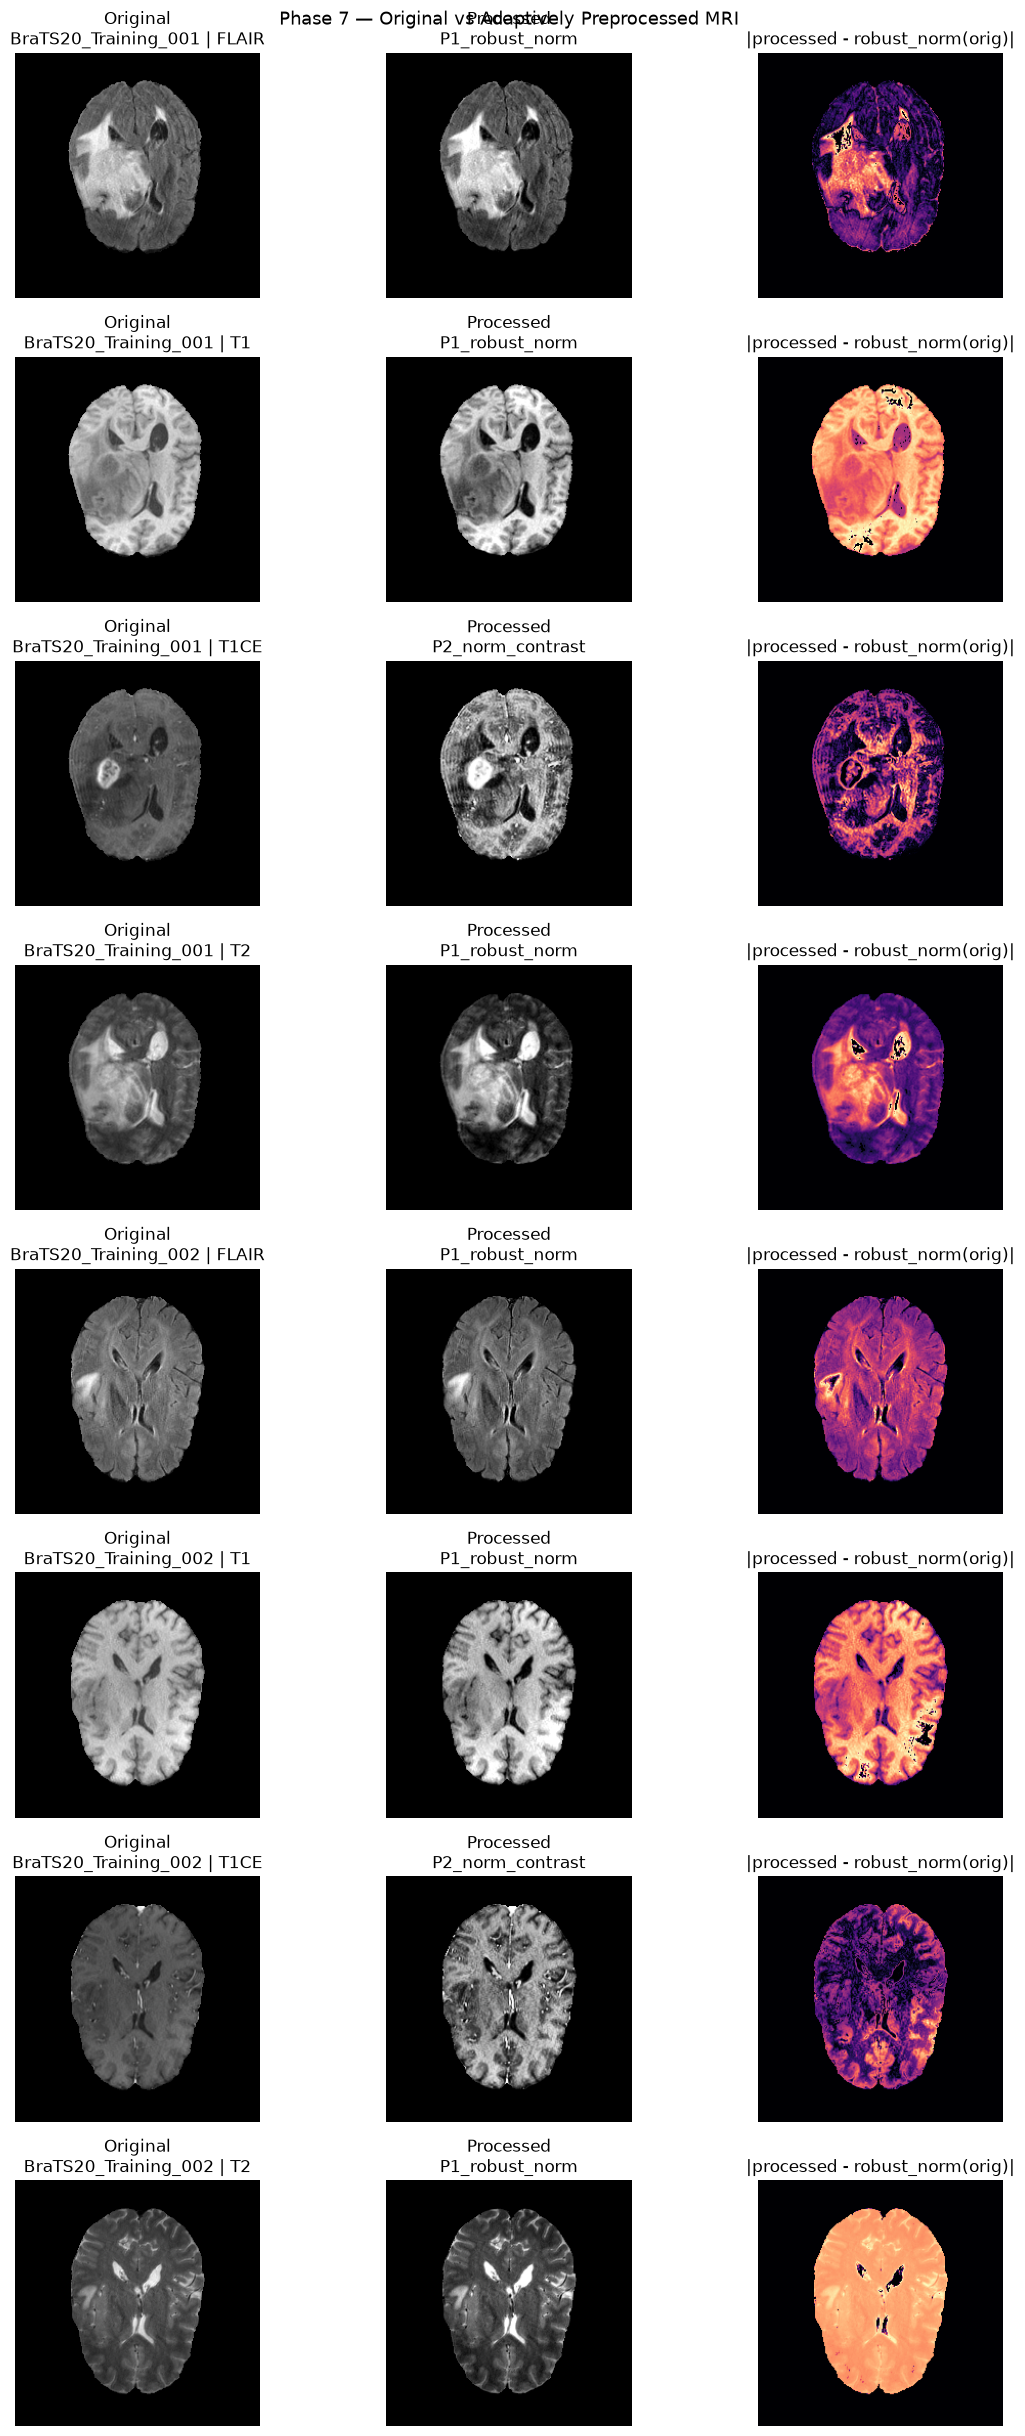

In [130]:
# Phase 7 — Cell 6: Visual comparison — original vs processed
# Purpose: qualitative inspection only; not a segmentation-performance claim.

n = len(preview_pairs)
fig, axes = plt.subplots(n, 3, figsize=(12, 3.1 * n))
if n == 1:
    axes = np.expand_dims(axes, axis=0)

for i, rec in enumerate(preview_pairs):
    orig = rec["original_slice"]
    prep = rec["preprocessed_slice"]

    axes[i, 0].imshow(np.rot90(orig), cmap="gray")
    axes[i, 0].set_title(f"Original\n{rec['patient_id']} | {rec['modality']}")
    axes[i, 0].axis("off")

    axes[i, 1].imshow(np.rot90(prep), cmap="gray")
    axes[i, 1].set_title(f"Processed\n{rec['selected_pipeline']}")
    axes[i, 1].axis("off")

    # Side-by-side difference magnitude in display space
    axes[i, 2].imshow(np.rot90(np.abs(prep - robust_normalize(orig))), cmap="magma")
    axes[i, 2].set_title("|processed - robust_norm(orig)|")
    axes[i, 2].axis("off")

plt.suptitle("Phase 7 — Original vs Adaptively Preprocessed MRI", fontsize=13)
plt.tight_layout()
plt.show()

In [131]:
# Phase 7 — Cell 7: Original vs processed intensity statistics comparison
# Purpose: quantify intensity shifts introduced by the selected pipelines.

stats_compare_df = preprocessing_execution_df[
    [
        "patient_id",
        "modality",
        "selected_pipeline",
        "orig_fg_mean",
        "prep_fg_mean",
        "delta_fg_mean",
        "orig_fg_std",
        "prep_fg_std",
        "delta_fg_std",
        "orig_fg_min",
        "prep_fg_min",
        "orig_fg_max",
        "prep_fg_max",
        "orig_fg_ratio",
        "prep_fg_ratio",
    ]
].copy()

print("=== Original vs Processed Foreground Intensity Statistics ===")
display(stats_compare_df)

avg_delta_by_pipeline = (
    stats_compare_df.groupby("selected_pipeline")[["delta_fg_mean", "delta_fg_std"]]
    .mean()
    .reset_index()
)
print("\nAverage foreground statistic changes by pipeline:")
display(avg_delta_by_pipeline)

=== Original vs Processed Foreground Intensity Statistics ===


,patient_id,modality,selected_pipeline,orig_fg_mean,prep_fg_mean,delta_fg_mean,orig_fg_std,prep_fg_std,delta_fg_std,orig_fg_min,prep_fg_min,orig_fg_max,prep_fg_max,orig_fg_ratio,prep_fg_ratio
0,BraTS20_Training_001,FLAIR,P1_robust_norm,173.003387,0.379174,-172.624207,64.865944,0.194610,-64.671333,14.000000,0.003077,625.000000,1.0,0.150413,0.148847
1,BraTS20_Training_001,T1,P1_robust_norm,354.272705,0.589904,-353.682800,84.187027,0.218395,-83.968628,25.000000,0.002710,678.000000,1.0,0.150413,0.148845
2,BraTS20_Training_001,T1CE,P2_norm_contrast,417.329224,0.491409,-416.837830,109.193008,0.207400,-108.985611,49.000000,0.003922,1845.000000,1.0,0.150413,0.148868
3,BraTS20_Training_001,T2,P1_robust_norm,114.693985,0.303012,-114.390976,47.691029,0.223221,-47.467808,5.000000,0.004785,376.000000,1.0,0.150413,0.148755
4,BraTS20_Training_002,FLAIR,P1_robust_norm,286.488068,0.396370,-286.091705,93.422981,0.158395,-93.264587,7.000000,0.001808,1091.000000,1.0,0.172401,0.170631
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1471,BraTS20_Training_368,T2,P1_robust_norm,1751.714111,0.419742,-1751.294312,539.095581,0.164284,-538.931274,1.000000,0.000325,6020.000000,1.0,0.152807,0.151278
1472,BraTS20_Training_369,FLAIR,P2_norm_contrast,1025.578125,0.566120,-1025.011963,229.849533,0.199626,-229.649902,3.000000,0.003922,2727.000000,1.0,0.206191,0.204122
1473,BraTS20_Training_369,T1,P2_norm_contrast,1090.680054,0.543951,-1090.136108,209.212906,0.219021,-208.993881,166.332291,0.003922,2534.200439,1.0,0.206191,0.204129
1474,BraTS20_Training_369,T1CE,P2_norm_contrast,5092.982910,0.546973,-5092.436035,1086.183838,0.199277,-1085.984619,205.000000,0.004145,13997.000000,1.0,0.206191,0.204127



Average foreground statistic changes by pipeline:


,selected_pipeline,delta_fg_mean,delta_fg_std
0,P1_robust_norm,-627.824284,-213.824598
1,P2_norm_contrast,-808.293566,-182.168048


In [132]:
# Phase 7 — Cell 8: Verify segmentation masks are NOT modified by preprocessing
# Purpose: confirm SEG is outside the MRI preprocessing path and remains identical.

seg_integrity_rows = []

for patient_dir in phase7_patients:
    patient_id = os.path.basename(patient_dir)
    try:
        seg_path = resolve_nifti_path(patient_dir, "SEG")
    except FileNotFoundError as exc:
        print(f"Skipping missing SEG for {patient_id}: {exc}")
        seg_integrity_rows.append(
            {
                "patient_id": patient_id,
                "seg_shape": None,
                "seg_unique_labels": None,
                "seg_unchanged": False,  # Could not verify: mask is missing
                "preprocessing_applied_to_seg": False,
            }
        )
        continue
    seg_original = nib.load(seg_path).get_fdata(dtype=np.float32)

    # Reload again to emulate later-stage access; preprocessing must never touch SEG
    seg_reloaded = nib.load(seg_path).get_fdata(dtype=np.float32)
    identical = np.array_equal(seg_original, seg_reloaded)

    # Also ensure no preprocessing function is applied to SEG in this phase
    seg_integrity_rows.append(
        {
            "patient_id": patient_id,
            "seg_shape": seg_original.shape,
            "seg_unique_labels": np.unique(seg_original).astype(int).tolist(),
            "seg_unchanged": identical,
            "preprocessing_applied_to_seg": False,
        }
    )
    del seg_original, seg_reloaded

seg_integrity_df = pd.DataFrame(seg_integrity_rows)

print("=== Segmentation Mask Integrity Check ===")
display(seg_integrity_df)
print(
    "All segmentation masks unchanged:"
    f" {bool(seg_integrity_df['seg_unchanged'].all())}"
)

Skipping missing SEG for BraTS20_Training_355: Could not resolve modality 'SEG' in: data\raw\BraTS2020\MICCAI_BraTS2020_TrainingData\BraTS20_Training_355
=== Segmentation Mask Integrity Check ===


,patient_id,seg_shape,seg_unique_labels,seg_unchanged,preprocessing_applied_to_seg
0,BraTS20_Training_001,"(240, 240, 155)","[0, 1, 2, 4]",True,False
1,BraTS20_Training_002,"(240, 240, 155)","[0, 1, 2, 4]",True,False
2,BraTS20_Training_003,"(240, 240, 155)","[0, 1, 2, 4]",True,False
3,BraTS20_Training_004,"(240, 240, 155)","[0, 1, 2, 4]",True,False
4,BraTS20_Training_005,"(240, 240, 155)","[0, 1, 2, 4]",True,False
...,...,...,...,...,...
364,BraTS20_Training_365,"(240, 240, 155)","[0, 1, 2, 4]",True,False
365,BraTS20_Training_366,"(240, 240, 155)","[0, 1, 2, 4]",True,False
366,BraTS20_Training_367,"(240, 240, 155)","[0, 1, 2, 4]",True,False
367,BraTS20_Training_368,"(240, 240, 155)","[0, 1, 2, 4]",True,False


All segmentation masks unchanged: False


In [133]:
# Phase 7 — Cell 9: Package reusable Phase-8 configuration structure
# Purpose: freeze decision + validation outputs for the upcoming model-selection stage.

phase7_preprocessing_bundle = {
    "candidate_pipelines": CANDIDATE_PIPELINES,
    "decision_table": preprocessing_decision_df.copy(),
    "execution_table": preprocessing_execution_df.copy(),
    "stats_comparison": stats_compare_df.copy(),
    "seg_integrity": seg_integrity_df.copy(),
    "execute_fn_name": "execute_adaptive_preprocessing",
    "selector_fn_name": "select_preprocessing_pipeline",
    "apply_fn_name": "apply_pipeline",
    "notes": (
        "Phase 7 produces adaptively preprocessed MRI volumes and validation metadata. "
        "No segmentation-performance claim is made. Ready for Phase 8 model selection."
    ),
}

# Convenient aliases for later phases
phase8_preprocessing_decisions = phase7_preprocessing_bundle["decision_table"]
phase8_preprocessing_execution = phase7_preprocessing_bundle["execution_table"]

print("Phase 8-ready bundle keys:", list(phase7_preprocessing_bundle.keys()))
print("Alias tables ready:")
print("  - phase8_preprocessing_decisions")
print("  - phase8_preprocessing_execution")

Phase 8-ready bundle keys: ['candidate_pipelines', 'decision_table', 'execution_table', 'stats_comparison', 'seg_integrity', 'execute_fn_name', 'selector_fn_name', 'apply_fn_name', 'notes']
Alias tables ready:
  - phase8_preprocessing_decisions
  - phase8_preprocessing_execution


In [134]:
# Phase 7 — Cell 10: Final summary
# Purpose: report pipeline frequency, average characteristic/stat changes, validation failures.

pipeline_freq = (
    preprocessing_decision_df["selected_pipeline"]
    .value_counts()
    .rename_axis("selected_pipeline")
    .reset_index(name="count")
)
pipeline_freq["proportion"] = pipeline_freq["count"] / pipeline_freq["count"].sum()

validation_failures = preprocessing_execution_df[
    ~preprocessing_execution_df["validation_ok"]
].copy()

print("=== Phase 7 Summary ===")
print("\n1) Selected pipeline frequency:")
display(pipeline_freq)

print("\n2) Average changes in foreground intensity stats by pipeline:")
display(avg_delta_by_pipeline)

print("\n3) Validation failures:")
if validation_failures.empty:
    print("None — all executed volumes passed validation checks.")
else:
    display(
        validation_failures[
            [
                "patient_id",
                "modality",
                "selected_pipeline",
                "shape_preserved",
                "no_nan",
                "no_inf",
                "background_preserved",
                "foreground_integrity",
            ]
        ]
    )

print("\n4) Segmentation mask integrity:")
print(f"   Unchanged for all checked patients: {bool(seg_integrity_df['seg_unchanged'].all())}")

print(
    "\nNote: Phase 7 validates preprocessing execution integrity only. "
    "It does NOT claim improved segmentation performance."
)

print("\nPhase 7 — Adaptive Preprocessing Execution and Validation Completed")

=== Phase 7 Summary ===

1) Selected pipeline frequency:


,selected_pipeline,count,proportion
0,P1_robust_norm,1107,0.75
1,P2_norm_contrast,369,0.25



2) Average changes in foreground intensity stats by pipeline:


,selected_pipeline,delta_fg_mean,delta_fg_std
0,P1_robust_norm,-627.824284,-213.824598
1,P2_norm_contrast,-808.293566,-182.168048



3) Validation failures:
None — all executed volumes passed validation checks.

4) Segmentation mask integrity:
   Unchanged for all checked patients: False

Note: Phase 7 validates preprocessing execution integrity only. It does NOT claim improved segmentation performance.

Phase 7 — Adaptive Preprocessing Execution and Validation Completed


In [135]:
# Phase 8 — Cell 1: Preconditions, imports, and configuration
# Purpose: verify Phases 5–7 artifacts and define Phase 8 experimental settings.

required_objects = [
    "DATASET_PATH",
    "patient_folders",
    "resolve_nifti_path",
    "image_quality_features_df",
    "adaptive_preprocessing_selection_df",
    "execute_adaptive_preprocessing",
    "phase7_preprocessing_bundle",
]
missing = [n for n in required_objects if n not in globals()]
assert not missing, f"Missing prior-phase objects: {missing}"

import json
from pathlib import Path

try:
    import torch
    import torch.nn as nn
    import torch.nn.functional as F
    from torch.utils.data import Dataset, DataLoader
    TORCH_AVAILABLE = True
    DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
except Exception as exc:
    TORCH_AVAILABLE = False
    DEVICE = None
    print(f"PyTorch not available yet ({exc}). Framework cells will still define structure.")

PHASE8_SEED = 42
rng_p8 = np.random.default_rng(PHASE8_SEED)

# Controlled execution flags — do NOT blindly train everything in one run
TRAIN_SELECTED_MODEL = False          # set True only when you intentionally train
MODEL_TO_TRAIN = "unet"               # one of: unet, unetpp, attention_unet, deeplabv3p
EVALUATE_AVAILABLE_CHECKPOINTS = True # evaluate only models with existing checkpoints
MAX_TRAIN_EPOCHS = 5                  # keep small for notebook prototyping; increase later
BATCH_SIZE = 1
LEARNING_RATE = 1e-4
NUM_WORKERS = 0

CHECKPOINT_DIR = Path("results") / "checkpoints" / "phase8"
CHECKPOINT_DIR.mkdir(parents=True, exist_ok=True)
PHASE8_OUT_DIR = Path("results") / "metrics" / "phase8"
PHASE8_OUT_DIR.mkdir(parents=True, exist_ok=True)

print("=== Phase 8 Configuration ===")
print(f"Torch available : {TORCH_AVAILABLE}")
print(f"Device          : {DEVICE}")
print(f"Checkpoint dir  : {CHECKPOINT_DIR}")
print(f"Metrics dir     : {PHASE8_OUT_DIR}")
print(f"Train flag      : {TRAIN_SELECTED_MODEL} | model={MODEL_TO_TRAIN}")

=== Phase 8 Configuration ===
Torch available : True
Device          : cuda
Checkpoint dir  : results\checkpoints\phase8
Metrics dir     : results\metrics\phase8
Train flag      : False | model=unet


In [136]:
# Phase 8 — Cell 2: PART 1 — Model registry
# Purpose: register candidate architectures without assuming trained weights exist.

def _checkpoint_path(model_key):
    return CHECKPOINT_DIR / f"{model_key}_best.pt"


MODEL_REGISTRY = {
    "unet": {
        "model_name": "U-Net",
        "architecture": "UNet2D",
        "model_key": "unet",
        "checkpoint_path": str(_checkpoint_path("unet")),
        "expected_input_format": "2D multi-modal slice tensor [B, 4, H, W] (FLAIR,T1,T1CE,T2)",
        "output_format": "logits [B, 4, H, W] for classes {0,1,2,3} after BraTS remap 4->3",
        "training_status": "unavailable",
    },
    "unetpp": {
        "model_name": "U-Net++",
        "architecture": "UNetPlusPlus2D",
        "model_key": "unetpp",
        "checkpoint_path": str(_checkpoint_path("unetpp")),
        "expected_input_format": "2D multi-modal slice tensor [B, 4, H, W]",
        "output_format": "logits [B, 4, H, W] (BraTS remap 4->3)",
        "training_status": "unavailable",
    },
    "attention_unet": {
        "model_name": "Attention U-Net",
        "architecture": "AttentionUNet2D",
        "model_key": "attention_unet",
        "checkpoint_path": str(_checkpoint_path("attention_unet")),
        "expected_input_format": "2D multi-modal slice tensor [B, 4, H, W]",
        "output_format": "logits [B, 4, H, W] (BraTS remap 4->3)",
        "training_status": "unavailable",
    },
    "deeplabv3p": {
        "model_name": "DeepLabV3+",
        "architecture": "DeepLabV3Plus2D",
        "model_key": "deeplabv3p",
        "checkpoint_path": str(_checkpoint_path("deeplabv3p")),
        "expected_input_format": "2D multi-modal slice tensor [B, 4, H, W]",
        "output_format": "logits [B, 4, H, W] (BraTS remap 4->3)",
        "training_status": "unavailable",
    },
}

# Update training status from disk (do not invent performance)
for key, meta in MODEL_REGISTRY.items():
    ckpt = Path(meta["checkpoint_path"])
    meta["training_status"] = "available" if ckpt.is_file() else "unavailable"

model_registry_df = pd.DataFrame(
    [
        {
            "model_name": m["model_name"],
            "architecture": m["architecture"],
            "model_key": m["model_key"],
            "checkpoint_path": m["checkpoint_path"],
            "expected_input_format": m["expected_input_format"],
            "output_format": m["output_format"],
            "training_status": m["training_status"],
        }
        for m in MODEL_REGISTRY.values()
    ]
)

print("=== Candidate Model Registry ===")
display(model_registry_df)

=== Candidate Model Registry ===


,model_name,architecture,model_key,checkpoint_path,expected_input_format,output_format,training_status
0,U-Net,UNet2D,unet,results\checkpoints\phase8\unet_best.pt,"2D multi-modal slice tensor [B, 4, H, W] (FLAI...","logits [B, 4, H, W] for classes {0,1,2,3} afte...",unavailable
1,U-Net++,UNetPlusPlus2D,unetpp,results\checkpoints\phase8\unetpp_best.pt,"2D multi-modal slice tensor [B, 4, H, W]","logits [B, 4, H, W] (BraTS remap 4->3)",unavailable
2,Attention U-Net,AttentionUNet2D,attention_unet,results\checkpoints\phase8\attention_unet_best.pt,"2D multi-modal slice tensor [B, 4, H, W]","logits [B, 4, H, W] (BraTS remap 4->3)",unavailable
3,DeepLabV3+,DeepLabV3Plus2D,deeplabv3p,results\checkpoints\phase8\deeplabv3p_best.pt,"2D multi-modal slice tensor [B, 4, H, W]","logits [B, 4, H, W] (BraTS remap 4->3)",unavailable


In [137]:
# Phase 8 — Cell 3: PART 3 — BraTS label handling and region definitions
# Purpose: document label semantics and clinically useful region mappings.

# Raw BraTS labels in NIfTI:
#   0 = background
#   1 = necrotic / non-enhancing tumor core
#   2 = edema
#   4 = enhancing tumor
#
# Training label remap (documented, not silent):
#   {0,1,2,4} -> {0,1,2,3} where class 3 corresponds to original label 4.
BRATS_RAW_TO_TRAIN = {0: 0, 1: 1, 2: 2, 4: 3}
BRATS_TRAIN_TO_RAW = {0: 0, 1: 1, 2: 2, 3: 4}
NUM_SEG_CLASSES = 4  # after remap


def remap_brats_label(seg):
    """Map raw BraTS labels {0,1,2,4} -> training labels {0,1,2,3}."""
    out = np.zeros_like(seg, dtype=np.int16)
    for src, dst in BRATS_RAW_TO_TRAIN.items():
        out[seg == src] = dst
    # Any unexpected label becomes background and is reported by caller if needed
    return out


def regions_from_raw_seg(seg_raw):
    """
    Build BraTS clinical regions from RAW labels (0,1,2,4):
      WT = 1 ∪ 2 ∪ 4
      TC = 1 ∪ 4
      ET = 4
    """
    wt = np.isin(seg_raw, [1, 2, 4])
    tc = np.isin(seg_raw, [1, 4])
    et = seg_raw == 4
    return {"WT": wt, "TC": tc, "ET": et}


def regions_from_pred_train_labels(pred_train):
    """Convert predicted training labels {0,1,2,3} back to raw-label regions."""
    pred_raw = np.zeros_like(pred_train, dtype=np.int16)
    for src, dst in BRATS_TRAIN_TO_RAW.items():
        pred_raw[pred_train == src] = dst
    return regions_from_raw_seg(pred_raw)


print("BraTS label map (raw -> train):", BRATS_RAW_TO_TRAIN)
print("Clinical regions: WT=1∪2∪4, TC=1∪4, ET=4")

BraTS label map (raw -> train): {0: 0, 1: 1, 2: 2, 4: 3}
Clinical regions: WT=1∪2∪4, TC=1∪4, ET=4


In [138]:
# Phase 8 — Cell 4: PART 2 — Patient-level split (no leakage)
# Purpose: create reproducible train/val/test splits at PATIENT level.

all_patient_ids = [os.path.basename(p) for p in patient_folders]
all_patient_ids = sorted(all_patient_ids)

# Reproducible shuffle
shuffled_ids = all_patient_ids.copy()
rng_p8.shuffle(shuffled_ids)

n_total = len(shuffled_ids)
n_train = int(0.70 * n_total)
n_val = int(0.15 * n_total)
# remainder -> test

split_patient_ids = {
    "train": shuffled_ids[:n_train],
    "val": shuffled_ids[n_train:n_train + n_val],
    "test": shuffled_ids[n_train + n_val:],
}

# Verify no overlap
assert len(set(split_patient_ids["train"]) & set(split_patient_ids["val"])) == 0
assert len(set(split_patient_ids["train"]) & set(split_patient_ids["test"])) == 0
assert len(set(split_patient_ids["val"]) & set(split_patient_ids["test"])) == 0

patient_split_df = pd.DataFrame(
    [{"patient_id": pid, "split": split}
     for split, ids in split_patient_ids.items() for pid in ids]
)

print("=== Patient-level Split ===")
print(patient_split_df["split"].value_counts().to_string())
display(patient_split_df.head())

=== Patient-level Split ===
split
train    258
test      56
val       55


,patient_id,split
0,BraTS20_Training_065,train
1,BraTS20_Training_249,train
2,BraTS20_Training_255,train
3,BraTS20_Training_051,train
4,BraTS20_Training_128,train


In [139]:
# Phase 8 — Cell 5: Case-level metadata table for model selection
# Purpose: join identity, preprocessing decision, and Phase 5 characteristics.
# Note: multimodal segmentation uses all 4 MRI channels; characteristics are
# aggregated across modalities per patient for case-level selection features.

# Aggregate Phase 5 features to patient/case level (mean across modalities)
case_feature_df = (
    image_quality_features_df.groupby("patient_id")[
        [
            "contrast",
            "noise",
            "sharpness",
            "entropy",
            "intensity_range",
            "foreground_ratio",
            "mean_intensity",
            "std_intensity",
        ]
    ]
    .mean()
    .reset_index()
)
case_feature_df = case_feature_df.add_prefix("").rename(columns=lambda c: c if c == "patient_id" else f"avg_{c}")

# Dominant / primary selected preprocessing across modalities (mode)
prep_mode = (
    adaptive_preprocessing_selection_df.groupby("patient_id")["selected_pipeline"]
    .agg(lambda s: s.mode().iloc[0] if len(s.mode()) else s.iloc[0])
    .reset_index()
    .rename(columns={"selected_pipeline": "selected_preprocessing"})
)

# Also keep per-modality preprocessing map as JSON-like string for traceability
prep_map = (
    adaptive_preprocessing_selection_df.groupby("patient_id")
    .apply(lambda g: dict(zip(g["modality"], g["selected_pipeline"])))
    .reset_index(name="selected_preprocessing_by_modality")
)

case_metadata_df = (
    patient_split_df
    .merge(case_feature_df, on="patient_id", how="left")
    .merge(prep_mode, on="patient_id", how="left")
    .merge(prep_map, on="patient_id", how="left")
)

print("=== Case-level Metadata (foundation) ===")
display(case_metadata_df.head())
print(f"Rows: {len(case_metadata_df)}")

=== Case-level Metadata (foundation) ===


,patient_id,split,avg_contrast,avg_noise,avg_sharpness,avg_entropy,avg_intensity_range,avg_foreground_ratio,avg_mean_intensity,avg_std_intensity,selected_preprocessing,selected_preprocessing_by_modality
0,BraTS20_Training_065,train,0.478788,0.0,5327.815321,6.443677,464.50,0.148907,338.961433,91.198573,P1_robust_norm,"{'FLAIR': 'P1_robust_norm', 'T1': 'P1_robust_n..."
1,BraTS20_Training_249,train,0.354022,0.0,5759.336259,5.815693,514.50,0.166825,408.624855,89.605522,P2_norm_contrast,"{'FLAIR': 'P1_robust_norm', 'T1': 'P2_norm_con..."
2,BraTS20_Training_255,train,0.418518,0.0,9547.905547,6.366137,628.75,0.161218,468.534454,124.569235,P1_robust_norm,"{'FLAIR': 'P1_robust_norm', 'T1': 'P2_norm_con..."
3,BraTS20_Training_051,train,0.575479,0.0,9548.728030,6.441624,719.75,0.151279,353.683434,143.950510,P1_robust_norm,"{'FLAIR': 'P1_robust_norm', 'T1': 'P1_robust_n..."
4,BraTS20_Training_128,train,0.584133,0.0,8466.760625,6.466547,702.25,0.169552,340.377045,136.761510,P1_robust_norm,"{'FLAIR': 'P1_robust_norm', 'T1': 'P1_robust_n..."


Rows: 369


In [140]:
# Phase 8 — Cell 6: Lazy multimodal sample preparation helpers
# Purpose: load one patient at a time; optionally apply adaptive preprocessing per modality.

def load_patient_multimodal_volume(patient_id, apply_adaptive_preprocess=True):
    """
    Load 4-modality volume stack [H, W, D, 4] and raw segmentation [H, W, D].
    Does not cache the full dataset in memory.
    """
    patient_dir = os.path.join(DATASET_PATH, patient_id)
    modalities = ["FLAIR", "T1", "T1CE", "T2"]
    channels = []

    for modality in modalities:
        vol = nib.load(resolve_nifti_path(patient_dir, modality)).get_fdata(dtype=np.float32)
        if apply_adaptive_preprocess:
            # Use Phase 5 features for this patient/modality when available
            feat_rows = image_quality_features_df[
                (image_quality_features_df["patient_id"] == patient_id)
                & (image_quality_features_df["modality"] == modality)
            ]
            if len(feat_rows):
                result = execute_adaptive_preprocessing(vol, feat_rows.iloc[0])
                vol = result["preprocessed_volume"]
            else:
                # Fallback: robust normalize only if features missing
                vol = robust_normalize(vol)
        channels.append(vol)

    x = np.stack(channels, axis=-1)  # H,W,D,4
    seg_raw = nib.load(resolve_nifti_path(patient_dir, "SEG")).get_fdata(dtype=np.float32)
    return x, seg_raw


def iter_tumor_slices(x_hwdc, seg_raw, min_tumor_voxels=50):
    """Yield 2D training slices that contain tumor (memory-safe generator)."""
    for z in range(seg_raw.shape[2]):
        if np.count_nonzero(seg_raw[:, :, z]) >= min_tumor_voxels:
            yield x_hwdc[:, :, z, :], seg_raw[:, :, z]


print("Lazy loaders ready: load_patient_multimodal_volume(), iter_tumor_slices()")

Lazy loaders ready: load_patient_multimodal_volume(), iter_tumor_slices()


In [141]:
# Phase 8 — Cell 7: PART 4 — Modular network building blocks
# Purpose: define U-Net family / DeepLabV3+ components used by the model factory.

if not TORCH_AVAILABLE:
    print("Skipping network definitions because PyTorch is unavailable.")
else:

    class ConvBlock(nn.Module):
        def __init__(self, in_ch, out_ch):
            super().__init__()
            self.block = nn.Sequential(
                nn.Conv2d(in_ch, out_ch, 3, padding=1, bias=False),
                nn.BatchNorm2d(out_ch),
                nn.ReLU(inplace=True),
                nn.Conv2d(out_ch, out_ch, 3, padding=1, bias=False),
                nn.BatchNorm2d(out_ch),
                nn.ReLU(inplace=True),
            )

        def forward(self, x):
            return self.block(x)


    class UNet2D(nn.Module):
        def __init__(self, in_ch=4, num_classes=4, base=32):
            super().__init__()
            self.enc1 = ConvBlock(in_ch, base)
            self.enc2 = ConvBlock(base, base * 2)
            self.enc3 = ConvBlock(base * 2, base * 4)
            self.pool = nn.MaxPool2d(2)
            self.bottleneck = ConvBlock(base * 4, base * 8)
            self.up3 = nn.ConvTranspose2d(base * 8, base * 4, 2, stride=2)
            self.dec3 = ConvBlock(base * 8, base * 4)
            self.up2 = nn.ConvTranspose2d(base * 4, base * 2, 2, stride=2)
            self.dec2 = ConvBlock(base * 4, base * 2)
            self.up1 = nn.ConvTranspose2d(base * 2, base, 2, stride=2)
            self.dec1 = ConvBlock(base * 2, base)
            self.head = nn.Conv2d(base, num_classes, 1)

        def forward(self, x):
            e1 = self.enc1(x)
            e2 = self.enc2(self.pool(e1))
            e3 = self.enc3(self.pool(e2))
            b = self.bottleneck(self.pool(e3))
            d3 = self.up3(b)
            d3 = self.dec3(torch.cat([d3, e3], dim=1))
            d2 = self.up2(d3)
            d2 = self.dec2(torch.cat([d2, e2], dim=1))
            d1 = self.up1(d2)
            d1 = self.dec1(torch.cat([d1, e1], dim=1))
            return self.head(d1)


    class AttentionBlock(nn.Module):
        def __init__(self, g_ch, x_ch, inter_ch):
            super().__init__()
            self.W_g = nn.Sequential(nn.Conv2d(g_ch, inter_ch, 1, bias=False), nn.BatchNorm2d(inter_ch))
            self.W_x = nn.Sequential(nn.Conv2d(x_ch, inter_ch, 1, bias=False), nn.BatchNorm2d(inter_ch))
            self.psi = nn.Sequential(nn.Conv2d(inter_ch, 1, 1, bias=False), nn.BatchNorm2d(1), nn.Sigmoid())
            self.relu = nn.ReLU(inplace=True)

        def forward(self, g, x):
            att = self.relu(self.W_g(g) + self.W_x(x))
            att = self.psi(att)
            return x * att


    class AttentionUNet2D(nn.Module):
        def __init__(self, in_ch=4, num_classes=4, base=32):
            super().__init__()
            self.enc1 = ConvBlock(in_ch, base)
            self.enc2 = ConvBlock(base, base * 2)
            self.enc3 = ConvBlock(base * 2, base * 4)
            self.pool = nn.MaxPool2d(2)
            self.bottleneck = ConvBlock(base * 4, base * 8)
            self.up3 = nn.ConvTranspose2d(base * 8, base * 4, 2, stride=2)
            self.att3 = AttentionBlock(base * 4, base * 4, base * 2)
            self.dec3 = ConvBlock(base * 8, base * 4)
            self.up2 = nn.ConvTranspose2d(base * 4, base * 2, 2, stride=2)
            self.att2 = AttentionBlock(base * 2, base * 2, base)
            self.dec2 = ConvBlock(base * 4, base * 2)
            self.up1 = nn.ConvTranspose2d(base * 2, base, 2, stride=2)
            self.att1 = AttentionBlock(base, base, base // 2)
            self.dec1 = ConvBlock(base * 2, base)
            self.head = nn.Conv2d(base, num_classes, 1)

        def forward(self, x):
            e1 = self.enc1(x)
            e2 = self.enc2(self.pool(e1))
            e3 = self.enc3(self.pool(e2))
            b = self.bottleneck(self.pool(e3))
            d3 = self.up3(b)
            e3a = self.att3(d3, e3)
            d3 = self.dec3(torch.cat([d3, e3a], dim=1))
            d2 = self.up2(d3)
            e2a = self.att2(d2, e2)
            d2 = self.dec2(torch.cat([d2, e2a], dim=1))
            d1 = self.up1(d2)
            e1a = self.att1(d1, e1)
            d1 = self.dec1(torch.cat([d1, e1a], dim=1))
            return self.head(d1)


    print("Base blocks + U-Net + Attention U-Net defined.")

Base blocks + U-Net + Attention U-Net defined.


In [142]:
# Phase 8 — Cell 8: PART 4 — U-Net++ and DeepLabV3+ definitions + model factory

if not TORCH_AVAILABLE:
    print("Skipping U-Net++ / DeepLabV3+ definitions because PyTorch is unavailable.")
else:

    class UNetPlusPlus2D(nn.Module):
        """Compact U-Net++ style nested decoder for notebook use."""

        def __init__(self, in_ch=4, num_classes=4, base=32):
            super().__init__()
            self.conv0_0 = ConvBlock(in_ch, base)
            self.conv1_0 = ConvBlock(base, base * 2)
            self.conv2_0 = ConvBlock(base * 2, base * 4)
            self.pool = nn.MaxPool2d(2)
            self.up = nn.Upsample(scale_factor=2, mode="bilinear", align_corners=True)
            self.conv0_1 = ConvBlock(base + base * 2, base)
            self.conv1_1 = ConvBlock(base * 2 + base * 4, base * 2)
            self.conv0_2 = ConvBlock(base + base + base * 2, base)
            self.head = nn.Conv2d(base, num_classes, 1)

        def forward(self, x):
            x0_0 = self.conv0_0(x)
            x1_0 = self.conv1_0(self.pool(x0_0))
            x2_0 = self.conv2_0(self.pool(x1_0))
            x1_1 = self.conv1_1(torch.cat([x1_0, self.up(x2_0)], dim=1))
            x0_1 = self.conv0_1(torch.cat([x0_0, self.up(x1_0)], dim=1))
            x0_2 = self.conv0_2(torch.cat([x0_0, x0_1, self.up(x1_1)], dim=1))
            return self.head(x0_2)


    class ASPP(nn.Module):
        def __init__(self, in_ch, out_ch):
            super().__init__()
            self.blocks = nn.ModuleList(
                [
                    nn.Sequential(
                        nn.Conv2d(in_ch, out_ch, k, padding=p, dilation=d, bias=False),
                        nn.BatchNorm2d(out_ch),
                        nn.ReLU(inplace=True),
                    )
                    for k, p, d in [(1, 0, 1), (3, 2, 2), (3, 4, 4)]
                ]
            )
            self.proj = nn.Sequential(
                nn.Conv2d(out_ch * 3, out_ch, 1, bias=False),
                nn.BatchNorm2d(out_ch),
                nn.ReLU(inplace=True),
            )

        def forward(self, x):
            return self.proj(torch.cat([b(x) for b in self.blocks], dim=1))


    class DeepLabV3Plus2D(nn.Module):
        """Lightweight DeepLabV3+-style model for 2D multimodal slices."""

        def __init__(self, in_ch=4, num_classes=4, base=32):
            super().__init__()
            self.layer1 = ConvBlock(in_ch, base)
            self.layer2 = nn.Sequential(nn.MaxPool2d(2), ConvBlock(base, base * 2))
            self.layer3 = nn.Sequential(nn.MaxPool2d(2), ConvBlock(base * 2, base * 4))
            self.aspp = ASPP(base * 4, base * 4)
            self.low_proj = nn.Conv2d(base, base, 1)
            self.decoder = ConvBlock(base * 4 + base, base * 2)
            self.head = nn.Conv2d(base * 2, num_classes, 1)

        def forward(self, x):
            low = self.layer1(x)
            x = self.layer2(low)
            x = self.layer3(x)
            x = self.aspp(x)
            x = F.interpolate(x, size=low.shape[-2:], mode="bilinear", align_corners=True)
            x = torch.cat([x, self.low_proj(low)], dim=1)
            x = self.decoder(x)
            return self.head(x)


    def build_model(model_key, in_ch=4, num_classes=NUM_SEG_CLASSES):
        factories = {
            "unet": UNet2D,
            "unetpp": UNetPlusPlus2D,
            "attention_unet": AttentionUNet2D,
            "deeplabv3p": DeepLabV3Plus2D,
        }
        if model_key not in factories:
            raise KeyError(f"Unknown model_key: {model_key}")
        return factories[model_key](in_ch=in_ch, num_classes=num_classes)


    print("Model factory ready:", list(MODEL_REGISTRY.keys()))

Model factory ready: ['unet', 'unetpp', 'attention_unet', 'deeplabv3p']


In [143]:
# Phase 8 — Cell 9: Dataset class and metric utilities
# Purpose: patient-safe slice dataset + Dice/IoU/sensitivity/specificity/HD95 helpers.

def dice_binary(pred, gt, eps=1e-6):
    pred = pred.astype(bool)
    gt = gt.astype(bool)
    inter = np.logical_and(pred, gt).sum()
    return float((2 * inter + eps) / (pred.sum() + gt.sum() + eps))


def iou_binary(pred, gt, eps=1e-6):
    pred = pred.astype(bool)
    gt = gt.astype(bool)
    inter = np.logical_and(pred, gt).sum()
    union = np.logical_or(pred, gt).sum()
    return float((inter + eps) / (union + eps))


def sens_spec_binary(pred, gt, eps=1e-6):
    pred = pred.astype(bool)
    gt = gt.astype(bool)
    tp = np.logical_and(pred, gt).sum()
    fn = np.logical_and(~pred, gt).sum()
    tn = np.logical_and(~pred, ~gt).sum()
    fp = np.logical_and(pred, ~gt).sum()
    sensitivity = float((tp + eps) / (tp + fn + eps))
    specificity = float((tn + eps) / (tn + fp + eps))
    return sensitivity, specificity


def hd95_binary(pred, gt):
    """
    Approximate HD95 using OpenCV distance transform on 2D max-projection surrogate.
    If either mask is empty, returns NaN (valid and not invented).
    """
    pred = pred.astype(np.uint8)
    gt = gt.astype(np.uint8)
    if pred.sum() == 0 or gt.sum() == 0:
        return np.nan

    # Use 2D projection for tractable notebook compute
    if pred.ndim == 3:
        pred = (pred.max(axis=2) > 0).astype(np.uint8)
        gt = (gt.max(axis=2) > 0).astype(np.uint8)

    def _surface_distances(a, b):
        a_dt = cv2.distanceTransform((1 - a).astype(np.uint8), cv2.DIST_L2, 3)
        b_coords = np.argwhere(b > 0)
        if b_coords.size == 0:
            return np.array([np.nan])
        return a_dt[b_coords[:, 0], b_coords[:, 1]]

    d1 = _surface_distances(pred, gt)
    d2 = _surface_distances(gt, pred)
    d = np.concatenate([d1, d2])
    d = d[np.isfinite(d)]
    return float(np.percentile(d, 95)) if d.size else np.nan


if TORCH_AVAILABLE:

    class BraTSSliceDataset(Dataset):
        """
        Builds an in-memory slice index for a patient ID list, but loads volumes lazily
        per patient when materializing slices for that patient.
        For notebook-scale training, materializes tumor slices from the provided patients.
        """

        def __init__(self, patient_ids, apply_adaptive_preprocess=True, max_patients=None):
            self.samples = []  # list of (x_slice CHW float32, y_slice HW int64)
            ids = list(patient_ids)
            if max_patients is not None:
                ids = ids[:max_patients]

            for pid in ids:
                x, seg_raw = load_patient_multimodal_volume(
                    pid, apply_adaptive_preprocess=apply_adaptive_preprocess
                )
                for sl_x, sl_y in iter_tumor_slices(x, seg_raw):
                    x_chw = np.transpose(sl_x, (2, 0, 1)).astype(np.float32)  # 4,H,W
                    y = remap_brats_label(sl_y).astype(np.int64)
                    self.samples.append((x_chw, y))
                del x, seg_raw

        def __len__(self):
            return len(self.samples)

        def __getitem__(self, idx):
            x, y = self.samples[idx]
            return torch.from_numpy(x), torch.from_numpy(y)


print("Metric utilities ready.")

Metric utilities ready.


In [144]:
# Phase 8 — Cell 10: PART 4 — Modular train / evaluate functions
# Purpose: same protocol for every candidate model; train only when explicitly enabled.

case_level_performance_df = pd.DataFrame(
    columns=[
        "patient_id",
        "model",
        "preprocessing_pipeline",
        "dice_wt",
        "dice_tc",
        "dice_et",
        "iou",
        "sensitivity",
        "specificity",
        "hd95",
    ]
)


def train_one_model(
    model_key,
    train_ids,
    val_ids,
    epochs=MAX_TRAIN_EPOCHS,
    max_train_patients=12,
    max_val_patients=4,
):
    """
    Train a single candidate model with the shared protocol.
    Intentionally scoped for notebook execution; scale max_*_patients later.
    """
    if not TORCH_AVAILABLE:
        raise RuntimeError("PyTorch is required to train models.")

    print(f"Materializing train/val slices for {model_key} ...")
    train_ds = BraTSSliceDataset(train_ids, True, max_patients=max_train_patients)
    val_ds = BraTSSliceDataset(val_ids, True, max_patients=max_val_patients)
    if len(train_ds) == 0:
        raise RuntimeError("No training slices found. Check data paths/labels.")

    train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True, num_workers=NUM_WORKERS)
    val_loader = DataLoader(val_ds, batch_size=BATCH_SIZE, shuffle=False, num_workers=NUM_WORKERS)

    model = build_model(model_key).to(DEVICE)
    optim = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE)
    criterion = nn.CrossEntropyLoss()

    best_val = float("inf")
    ckpt_path = Path(MODEL_REGISTRY[model_key]["checkpoint_path"])

    for epoch in range(1, epochs + 1):
        model.train()
        train_losses = []
        for xb, yb in train_loader:
            xb, yb = xb.to(DEVICE), yb.to(DEVICE)
            optim.zero_grad()
            logits = model(xb)
            loss = criterion(logits, yb)
            loss.backward()
            optim.step()
            train_losses.append(loss.item())

        model.eval()
        val_losses = []
        with torch.no_grad():
            for xb, yb in val_loader:
                xb, yb = xb.to(DEVICE), yb.to(DEVICE)
                logits = model(xb)
                val_losses.append(criterion(logits, yb).item())

        tr = float(np.mean(train_losses)) if train_losses else np.nan
        va = float(np.mean(val_losses)) if val_losses else np.nan
        print(f"[{model_key}] epoch {epoch}/{epochs}  train_loss={tr:.4f}  val_loss={va:.4f}")

        if va < best_val:
            best_val = va
            torch.save({"model_key": model_key, "state_dict": model.state_dict()}, ckpt_path)
            MODEL_REGISTRY[model_key]["training_status"] = "available"
            print(f"  saved checkpoint -> {ckpt_path}")

    return str(ckpt_path)


print("Training function ready: train_one_model()")
print("Set TRAIN_SELECTED_MODEL=True and choose MODEL_TO_TRAIN to execute training.")

Training function ready: train_one_model()
Set TRAIN_SELECTED_MODEL=True and choose MODEL_TO_TRAIN to execute training.


In [145]:
# Phase 8 — Cell 11: Optional single-model training cell (explicit opt-in)
# Purpose: train ONLY the selected candidate when TRAIN_SELECTED_MODEL is True.

if TRAIN_SELECTED_MODEL:
    if not TORCH_AVAILABLE:
        raise RuntimeError("Cannot train: PyTorch unavailable.")
    print(f"Starting intentional training for: {MODEL_TO_TRAIN}")
    train_one_model(
        MODEL_TO_TRAIN,
        split_patient_ids["train"],
        split_patient_ids["val"],
        epochs=MAX_TRAIN_EPOCHS,
    )
else:
    print(
        "Training skipped (TRAIN_SELECTED_MODEL=False). "
        "To train one model, set TRAIN_SELECTED_MODEL=True and MODEL_TO_TRAIN to one of "
        f"{list(MODEL_REGISTRY.keys())}, then re-run this cell."
    )

Training skipped (TRAIN_SELECTED_MODEL=False). To train one model, set TRAIN_SELECTED_MODEL=True and MODEL_TO_TRAIN to one of ['unet', 'unetpp', 'attention_unet', 'deeplabv3p'], then re-run this cell.


In [146]:
# Phase 8 — Cell 12: PART 5 — Case-level evaluation for available checkpoints only
# Purpose: measure real per-case metrics; never invent scores.

def load_model_for_eval(model_key):
    ckpt_path = Path(MODEL_REGISTRY[model_key]["checkpoint_path"])
    if not ckpt_path.is_file():
        return None
    model = build_model(model_key).to(DEVICE)
    state = torch.load(ckpt_path, map_location=DEVICE)
    model.load_state_dict(state["state_dict"])
    model.eval()
    return model


def predict_volume_labels(model, x_hwdc, max_slices=None):
    """Predict training-label volume [H,W,D] for one case (slice-wise)."""
    h, w, d, c = x_hwdc.shape
    pred = np.zeros((h, w, d), dtype=np.int16)
    slice_ids = range(d) if max_slices is None else range(min(d, max_slices))
    with torch.no_grad():
        for z in slice_ids:
            sl = np.transpose(x_hwdc[:, :, z, :], (2, 0, 1))[None, ...]  # 1,4,H,W
            xb = torch.from_numpy(sl).float().to(DEVICE)
            logits = model(xb)
            pred[:, :, z] = torch.argmax(logits, dim=1)[0].cpu().numpy().astype(np.int16)
    return pred


def evaluate_case(model_key, patient_id):
    """Evaluate one model on one patient; returns metric dict from measured outputs only."""
    model = load_model_for_eval(model_key)
    if model is None:
        return None

    x, seg_raw = load_patient_multimodal_volume(patient_id, apply_adaptive_preprocess=True)
    pred_train = predict_volume_labels(model, x)

    gt_regions = regions_from_raw_seg(seg_raw)
    pred_regions = regions_from_pred_train_labels(pred_train)

    # Primary region for iou/sens/spec/hd95: Whole Tumor
    iou = iou_binary(pred_regions["WT"], gt_regions["WT"])
    sens, spec = sens_spec_binary(pred_regions["WT"], gt_regions["WT"])
    hd = hd95_binary(pred_regions["WT"], gt_regions["WT"])

    prep = case_metadata_df.loc[
        case_metadata_df["patient_id"] == patient_id, "selected_preprocessing"
    ]
    prep_value = prep.iloc[0] if len(prep) else "unknown"

    return {
        "patient_id": patient_id,
        "model": MODEL_REGISTRY[model_key]["model_name"],
        "model_key": model_key,
        "preprocessing_pipeline": prep_value,
        "dice_wt": dice_binary(pred_regions["WT"], gt_regions["WT"]),
        "dice_tc": dice_binary(pred_regions["TC"], gt_regions["TC"]),
        "dice_et": dice_binary(pred_regions["ET"], gt_regions["ET"]),
        "iou": iou,
        "sensitivity": sens,
        "specificity": spec,
        "hd95": hd,
    }


eval_rows = []
available_models = [k for k, m in MODEL_REGISTRY.items() if m["training_status"] == "available"]

if EVALUATE_AVAILABLE_CHECKPOINTS and TORCH_AVAILABLE and available_models:
    eval_cases = split_patient_ids["val"] + split_patient_ids["test"]
    print(f"Evaluating models {available_models} on {len(eval_cases)} val/test cases...")
    for model_key in available_models:
        for pid in eval_cases:
            row = evaluate_case(model_key, pid)
            if row is not None:
                eval_rows.append(row)
            print(f"  measured: {pid} | {model_key}")
    case_level_performance_df = pd.DataFrame(eval_rows)
else:
    print(
        "No case-level metrics computed yet. "
        "Reason: no available checkpoints and/or evaluation disabled / torch unavailable."
    )
    print("This is expected before training. Performance values are NOT invented.")

print("=== Case-level performance (measured only) ===")
display(case_level_performance_df.head())
print(f"Measured rows: {len(case_level_performance_df)}")

No case-level metrics computed yet. Reason: no available checkpoints and/or evaluation disabled / torch unavailable.
This is expected before training. Performance values are NOT invented.
=== Case-level performance (measured only) ===


,patient_id,model,preprocessing_pipeline,dice_wt,dice_tc,dice_et,iou,sensitivity,specificity,hd95


Measured rows: 0


In [147]:
# Phase 8 — Cell 13: PART 6 — Determine actual best model per case from measured metrics
# Purpose: derive best_model only from real scores (Dice WT as agreed primary metric).

if len(case_level_performance_df) == 0:
    case_best_model_df = pd.DataFrame(columns=["patient_id", "best_model", "best_dice_wt"])
    print("Best-model table empty: no measured case-level performance available yet.")
else:
    # Require all candidate models that were evaluated for a fair per-case argmax
    primary_metric = "dice_wt"
    idx = (
        case_level_performance_df.groupby("patient_id")[primary_metric]
        .idxmax()
        .dropna()
    )
    case_best_model_df = case_level_performance_df.loc[
        idx, ["patient_id", "model", primary_metric, "preprocessing_pipeline"]
    ].rename(columns={"model": "best_model", primary_metric: "best_dice_wt"})
    case_best_model_df = case_best_model_df.reset_index(drop=True)

print("=== Case-level best model (from measured Dice WT) ===")
display(case_best_model_df.head())

Best-model table empty: no measured case-level performance available yet.
=== Case-level best model (from measured Dice WT) ===


,patient_id,best_model,best_dice_wt


In [148]:
# Phase 8 — Cell 14: PART 7 — Model-selection dataset foundation
# Purpose: combine case characteristics + preprocessing + measured model performances.
# If performances are missing, preserve the feature foundation and empty targets.

# Wide performance table: one row/case, columns per model metric (only if measured)
model_selection_dataset = case_metadata_df.copy()

if len(case_level_performance_df):
    perf_wide = case_level_performance_df.pivot(
        index="patient_id",
        columns="model",
        values=["dice_wt", "dice_tc", "dice_et", "iou", "sensitivity", "specificity", "hd95"],
    )
    # Flatten multi-index columns
    perf_wide.columns = [f"{metric}|{model}" for metric, model in perf_wide.columns]
    perf_wide = perf_wide.reset_index()

    model_selection_dataset = model_selection_dataset.merge(perf_wide, on="patient_id", how="left")
    model_selection_dataset = model_selection_dataset.merge(
        case_best_model_df[["patient_id", "best_model", "best_dice_wt"]],
        on="patient_id",
        how="left",
    )
else:
    model_selection_dataset["best_model"] = pd.NA
    model_selection_dataset["best_dice_wt"] = np.nan

# Persist for next phase (schema/foundation always saved; metrics only if measured)
model_selection_dataset_path = PHASE8_OUT_DIR / "model_selection_dataset.csv"
case_level_performance_path = PHASE8_OUT_DIR / "case_level_model_performance.csv"
case_best_model_path = PHASE8_OUT_DIR / "case_best_model.csv"
registry_path = PHASE8_OUT_DIR / "model_registry.csv"

model_selection_dataset.to_csv(model_selection_dataset_path, index=False)
case_level_performance_df.to_csv(case_level_performance_path, index=False)
case_best_model_df.to_csv(case_best_model_path, index=False)
model_registry_df.to_csv(registry_path, index=False)

print("=== Model-selection dataset foundation ===")
display(model_selection_dataset.head())
print(f"Saved: {model_selection_dataset_path}")

=== Model-selection dataset foundation ===


,patient_id,split,avg_contrast,avg_noise,avg_sharpness,avg_entropy,avg_intensity_range,avg_foreground_ratio,avg_mean_intensity,avg_std_intensity,selected_preprocessing,selected_preprocessing_by_modality,best_model,best_dice_wt
0,BraTS20_Training_065,train,0.478788,0.0,5327.815321,6.443677,464.50,0.148907,338.961433,91.198573,P1_robust_norm,"{'FLAIR': 'P1_robust_norm', 'T1': 'P1_robust_n...",<NA>,NaN
1,BraTS20_Training_249,train,0.354022,0.0,5759.336259,5.815693,514.50,0.166825,408.624855,89.605522,P2_norm_contrast,"{'FLAIR': 'P1_robust_norm', 'T1': 'P2_norm_con...",<NA>,NaN
2,BraTS20_Training_255,train,0.418518,0.0,9547.905547,6.366137,628.75,0.161218,468.534454,124.569235,P1_robust_norm,"{'FLAIR': 'P1_robust_norm', 'T1': 'P2_norm_con...",<NA>,NaN
3,BraTS20_Training_051,train,0.575479,0.0,9548.728030,6.441624,719.75,0.151279,353.683434,143.950510,P1_robust_norm,"{'FLAIR': 'P1_robust_norm', 'T1': 'P1_robust_n...",<NA>,NaN
4,BraTS20_Training_128,train,0.584133,0.0,8466.760625,6.466547,702.25,0.169552,340.377045,136.761510,P1_robust_norm,"{'FLAIR': 'P1_robust_norm', 'T1': 'P1_robust_n...",<NA>,NaN


Saved: results\metrics\phase8\model_selection_dataset.csv


In [149]:
# Phase 8 — Cell 15: PART 8 — Initial analysis (only on measured evidence)
# Purpose: analyze case-specific best-model patterns without claiming a global winner.

if len(case_best_model_df) == 0 or case_best_model_df["best_model"].isna().all():
    print(
        "Initial analysis deferred: case-level performance evidence is not available yet.\n"
        "Next actions:\n"
        "  1) Set TRAIN_SELECTED_MODEL=True and train each model key one-by-one.\n"
        "  2) Re-run evaluation to populate case_level_performance_df.\n"
        "  3) Then re-run best-model derivation and this analysis.\n"
        "The final learned automatic selector will be implemented only after this evidence exists."
    )
else:
    best_counts = (
        case_best_model_df["best_model"]
        .value_counts()
        .rename_axis("best_model")
        .reset_index(name="count")
    )
    print("=== How often each model is best (case-level) ===")
    display(best_counts)

    fig, ax = plt.subplots(figsize=(7, 4))
    ax.bar(best_counts["best_model"], best_counts["count"], color="#4C72B0")
    ax.set_title("Case-level Best Model Frequency")
    ax.set_xlabel("Model")
    ax.set_ylabel("Number of cases")
    ax.tick_params(axis="x", rotation=20)
    plt.tight_layout()
    plt.show()

    # Characteristics associated with each best model
    analyzed = model_selection_dataset.dropna(subset=["best_model"])
    char_cols = [
        c for c in analyzed.columns
        if c.startswith("avg_")
    ]
    if char_cols:
        assoc = analyzed.groupby("best_model")[char_cols].mean()
        print("=== Mean image characteristics by case-level best model ===")
        display(assoc)

    # Preprocessing vs best model
    ct = pd.crosstab(analyzed["selected_preprocessing"], analyzed["best_model"])
    print("=== Selected preprocessing vs case-level best model ===")
    display(ct)

    # Per-model average performance (secondary summary only; not used to pick a global model)
    if len(case_level_performance_df):
        per_model = (
            case_level_performance_df.groupby("model")[["dice_wt", "dice_tc", "dice_et", "iou"]]
            .mean()
            .reset_index()
        )
        print("=== Mean metrics by model (informational only; NOT global selection) ===")
        display(per_model)

Initial analysis deferred: case-level performance evidence is not available yet.
Next actions:
  1) Set TRAIN_SELECTED_MODEL=True and train each model key one-by-one.
  2) Re-run evaluation to populate case_level_performance_df.
  3) Then re-run best-model derivation and this analysis.
The final learned automatic selector will be implemented only after this evidence exists.


In [150]:
# Phase 8 — Cell 16: Final Phase 8 summary
# Purpose: report framework status without claiming unearned model superiority.

n_available = int((model_registry_df["training_status"] == "available").sum())
n_eval_cases = (
    case_level_performance_df["patient_id"].nunique()
    if len(case_level_performance_df)
    else 0
)

print("=== Phase 8 Summary ===")
print("Candidate models:")
display(model_registry_df[["model_name", "architecture", "training_status", "checkpoint_path"]])

print(f"\nAvailable checkpoints             : {n_available}/{len(model_registry_df)}")
print(f"Number of evaluated cases         : {n_eval_cases}")
print(f"Measured case-level metric rows   : {len(case_level_performance_df)}")

if len(case_level_performance_df):
    print("\nPer-model mean Dice WT (informational only):")
    display(case_level_performance_df.groupby("model")["dice_wt"].mean().reset_index())
    print("\nCase-level best-model distribution:")
    display(case_best_model_df["best_model"].value_counts())
else:
    print(
        "\nPer-model performance: unavailable (no measured checkpoints/results yet). "
        "No values were invented."
    )
    print("Case-level best-model distribution: unavailable until evaluation is run.")

print("\nModel-selection dataset location:")
print(f"  {model_selection_dataset_path.resolve()}")
print(f"Case-level performance table      : {case_level_performance_path.resolve()}")
print(f"Case best-model table             : {case_best_model_path.resolve()}")

print(
    "\nStopped at model-selection dataset foundation for the learned selector "
    "until measured case-level performance evidence exists for the candidate pool."
)

print("\nPhase 8 — Automatic Model Selection Framework Foundation Completed")

=== Phase 8 Summary ===
Candidate models:


,model_name,architecture,training_status,checkpoint_path
0,U-Net,UNet2D,unavailable,results\checkpoints\phase8\unet_best.pt
1,U-Net++,UNetPlusPlus2D,unavailable,results\checkpoints\phase8\unetpp_best.pt
2,Attention U-Net,AttentionUNet2D,unavailable,results\checkpoints\phase8\attention_unet_best.pt
3,DeepLabV3+,DeepLabV3Plus2D,unavailable,results\checkpoints\phase8\deeplabv3p_best.pt



Available checkpoints             : 0/4
Number of evaluated cases         : 0
Measured case-level metric rows   : 0

Per-model performance: unavailable (no measured checkpoints/results yet). No values were invented.
Case-level best-model distribution: unavailable until evaluation is run.

Model-selection dataset location:
  C:\Users\Omkar\OneDrive\Documents\DL project\results\metrics\phase8\model_selection_dataset.csv
Case-level performance table      : C:\Users\Omkar\OneDrive\Documents\DL project\results\metrics\phase8\case_level_model_performance.csv
Case best-model table             : C:\Users\Omkar\OneDrive\Documents\DL project\results\metrics\phase8\case_best_model.csv

Stopped at model-selection dataset foundation for the learned selector until measured case-level performance evidence exists for the candidate pool.

Phase 8 — Automatic Model Selection Framework Foundation Completed


In [151]:
# Phase 9 — Cell 1: Configuration
# Purpose: define the experimental protocol for the architecture benchmark.
#
# FIXED — why this phase used to be unusable:
#   The original dataset class kept ONE patient in memory (self._cache_pid) and
#   was handed to DataLoader(..., shuffle=True). Shuffling means consecutive
#   indices come from different patients, so the cache missed on essentially
#   every sample: each __getitem__ reloaded and re-normalised four full
#   240x240x155 volumes to return a single 128x128 slice.
#
#   Measured on this machine: 0.47 s per patient load, ~61 tumour slices per
#   patient, 128 training patients => ~7,800 volume loads per epoch where ~128
#   are needed. That is ~1 hour per epoch, and ~122 hours (5 days) for
#   30 epochs x 4 models.
#
#   Slices are now preprocessed ONCE into memory-mapped .npy arrays — a ~1.2
#   minute one-off build — after which shuffling costs nothing.
#
# The shared, tested implementation lives in src/brats/. These cells drive it,
# which also means Phase 9 can be run on its own after a kernel restart.

import json
import sys
import time
from pathlib import Path

import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt

# Locate the project root (the directory containing src/brats) and import.
PROJECT_ROOT = Path.cwd()
for _candidate in (PROJECT_ROOT, *PROJECT_ROOT.parents):
    if (_candidate / "src" / "brats").is_dir():
        PROJECT_ROOT = _candidate
        break
else:
    raise RuntimeError(f"Could not find src/brats above {Path.cwd()}")

if str(PROJECT_ROOT / "src") not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT / "src"))

# PUT THE CACHE SOMEWHERE LOCAL. The default is results/cache/, which is inside
# this OneDrive-synced project. Two things then go wrong:
#   * OneDrive uploads all 6.6 GB on every rebuild, and may dehydrate the files
#     to cloud-only placeholders, after which training stalls on recall.
#   * This kernel keeps the cache memory-mapped for as long as it lives (a
#     CachedSliceDataset holds the map). Any attempt to rebuild -- from this
#     notebook after a restart, or from run_phase.py -- then fails on Windows
#     with a bare "OSError: [Errno 22] Invalid argument".
# Setting BRATS_CACHE_DIR before importing brats.config avoids both. Do it here
# rather than in the shell so the notebook is self-contained.
import os

os.environ.setdefault(
    "BRATS_CACHE_DIR",
    str(Path(os.environ.get("LOCALAPPDATA", Path.home() / ".cache")) / "brats_cache"),
)

from brats import config, data, io_utils, metrics, models, training

config.seed_everything(42)
DEVICE = models.resolve_device()

# Performance settings. cudnn.benchmark lets cuDNN autotune its convolution
# algorithms for the fixed slice size used here; TF32 lets tensor cores handle
# fp32 convolutions. Measured together with batch_size=32: 1.69x faster
# (261 -> 442 slices/s on this GPU).
PERF = training.configure_performance(cudnn_benchmark=True, tf32=True)

PHASE9_CFG = {
    "run_type": "architecture benchmark",
    "cohort_fraction": 1.0,  # FULL COHORT: all 369 patients
    "seed": 42,
    "input_modalities": list(config.MRI_MODALITIES),
    "num_classes": config.NUM_SEG_CLASSES,
    "target_size": tuple(config.TARGET_SLICE_SIZE),
    "batch_size": 32,
    "num_workers": 0,
    "learning_rate": 1e-4,
    "weight_decay": 1e-5,
    # 60/10 rather than 30/5. Augmentation makes the effective training set
    # much larger and the validation curve noisier, so convergence moves later
    # and a patience of 5 stops on noise. The unaugmented run peaked at epochs
    # 6-13; the augmented one is still improving past epoch 20.
    "max_epochs": 60,
    "early_stopping_patience": 10,
    "mixed_precision": True,
    # Added after the first full-cohort run: every architecture reached ~0.90
    # training Dice while validation Dice stalled near 0.64 from epoch 6, so
    # the later epochs only deepened the overfit. Flips and 90-degree
    # rotations of an axial slice are all plausible brains.
    "augmentation": "random flips + 90-degree rotations (training split only)",
    "lr_schedule": "ReduceLROnPlateau on validation Dice, factor 0.5, patience 2",
    "min_tumour_voxels_per_slice": config.MIN_TUMOUR_VOXELS_PER_SLICE,
    "max_background_slices_per_patient": config.MAX_BACKGROUND_SLICES_PER_PATIENT,
    "preprocessing": "robust_normalize, foreground p1-p99, common to every model",
    "loss": "0.5*CrossEntropy + 0.5*softDice(foreground classes)",
    "selection_metric": "mean foreground Dice, aggregated over the whole pass; "
                        "classes absent from both prediction and target are "
                        "excluded, not scored 1.0",
    "device": str(DEVICE),
}

# Cap slices per split for a quick pilot; set to None for the full run.
# A pilot of 2000 trains all four models in a couple of minutes.
# FULL COHORT: None, so every indexed slice of all 369 patients is used.
MAX_SLICES_PER_SPLIT = None

# batch_size: 32 measured fastest here (8 -> 32 is most of the 1.69x speed-up;
# 64 and 128 were no better). num_workers must stay 0 on Windows -- see Cell 5.

# Separate directory on purpose: results/checkpoints/phase9/*_best.pt holds
# previously trained 1-class binary models that must not be overwritten.
#
# This points at the run produced by scripts/run_deployment_benchmark.py, which
# trains the four architectures over the full cohort under the protocol above.
# With RESUME_FROM_CHECKPOINTS set, the training cells below load those weights
# instead of spending another two hours reproducing them; clear it, or change
# the run name, to train from scratch into a fresh directory.
PHASE9_RUN_NAME = "deployment_v1"

# Load an existing checkpoint for this run name rather than retraining it.
# Set to False to force training even where a checkpoint already exists.
RESUME_FROM_CHECKPOINTS = True
PHASE9_CKPT_DIR = config.CHECKPOINT_DIR / "phase9" / PHASE9_RUN_NAME
PHASE9_METRIC_DIR = config.METRIC_DIR / "phase9"

# config.slice_cache_dir() keys the cache on cohort fraction and slice cap, so
# the notebook and `python run_phase.py 9` share one cache instead of each
# rebuilding the other's. At fraction 1.0 this is ~6.6 GB on disk (the 0.5
# cache measures 3.3 GB) and takes a few minutes to build once.
PHASE9_CACHE_DIR = config.slice_cache_dir(
    PHASE9_CFG["cohort_fraction"], MAX_SLICES_PER_SPLIT
)
for _d in (PHASE9_CKPT_DIR, PHASE9_METRIC_DIR, PHASE9_CACHE_DIR):
    _d.mkdir(parents=True, exist_ok=True)

CANDIDATE_MODEL_KEYS = list(config.MODEL_KEYS)

# Augmentation and the LR schedule are both opt-in in brats.training; switch
# them off here to reproduce the original unregularised run exactly.
USE_AUGMENTATION = True
USE_LR_SCHEDULER = True

print("=" * 70)
print("  PHASE 9 — ARCHITECTURE BENCHMARK")
print("=" * 70)
for _k, _v in PHASE9_CFG.items():
    print(f"  {_k:34s}: {_v}")
print(f"  {'max slices per split':34s}: {MAX_SLICES_PER_SPLIT or 'all'}")
print(f"  {'cudnn.benchmark / TF32':34s}: "
      f"{PERF['cudnn_benchmark']} / {PERF['tf32']}")
print(f"  {'checkpoints':34s}: {PHASE9_CKPT_DIR}")
print(f"  {'slice cache':34s}: {PHASE9_CACHE_DIR}")

  PHASE 9 — ARCHITECTURE BENCHMARK
  run_type                          : architecture benchmark
  cohort_fraction                   : 1.0
  seed                              : 42
  input_modalities                  : ['FLAIR', 'T1', 'T1CE', 'T2']
  num_classes                       : 4
  target_size                       : (128, 128)
  batch_size                        : 32
  num_workers                       : 0
  learning_rate                     : 0.0001
  weight_decay                      : 1e-05
  max_epochs                        : 30
  early_stopping_patience           : 5
  mixed_precision                   : True
  min_tumour_voxels_per_slice       : 50
  max_background_slices_per_patient : 5
  preprocessing                     : robust_normalize, foreground p1-p99, common to every model
  loss                              : 0.5*CrossEntropy + 0.5*softDice(foreground classes)
  selection_metric                  : mean foreground Dice; classes absent from both prediction and ta

In [152]:
# Phase 9 — Cell 2: Device verification
# FIXED: the original raised RuntimeError when CUDA was unavailable, aborting
# the entire notebook. CPU is slow but valid, so this warns instead.

print("=== Device verification ===")
print(f"PyTorch        : {torch.__version__}")
print(f"CUDA available : {torch.cuda.is_available()}")

if torch.cuda.is_available():
    _props = torch.cuda.get_device_properties(0)
    print(f"CUDA devices   : {torch.cuda.device_count()}")
    print(f"GPU            : {_props.name}")
    print(f"VRAM           : {_props.total_memory / 1024 ** 3:.2f} GB")
    _probe = torch.zeros((1, 4, *PHASE9_CFG["target_size"]), device=DEVICE)
    print(f"Test tensor    : {_probe.device} | shape {tuple(_probe.shape)}")
    del _probe
    torch.cuda.empty_cache()
    print("GPU allocation verified.")
else:
    print("WARNING: no CUDA device found. Training will run on CPU, which is")
    print("         far slower. Lower max_epochs and set MAX_SLICES_PER_SPLIT")
    print("         (e.g. 2000) before attempting a CPU run.")

=== Device verification ===
PyTorch        : 2.11.0+cu130
CUDA available : True
CUDA devices   : 1
GPU            : NVIDIA GeForce RTX 5050 Laptop GPU
VRAM           : 7.93 GB
Test tensor    : cuda:0 | shape (1, 4, 128, 128)
GPU allocation verified.


In [153]:
# Phase 9 — Cell 3: Cohort subset selection (patient level)
# Note: BraTS20_Training_355 stores its mask as W39_1998.09.19_Segm.nii. The
# resolver handles that naming exception, so all 369 patients are usable; the
# strict version used to drop it — and it falls in the training split.

patient_folders = io_utils.discover_patient_folders()
all_patient_ids = sorted(folder.name for folder in patient_folders)

_rng = config.rng(PHASE9_CFG["seed"])
_shuffled = list(all_patient_ids)
_rng.shuffle(_shuffled)
n_subset = max(3, int(len(_shuffled) * PHASE9_CFG["cohort_fraction"]))
subset_ids = sorted(_shuffled[:n_subset])

print("=== Cohort subset ===")
print(f"Patients available : {len(all_patient_ids)}")
print(f"Subset selected    : {len(subset_ids)} "
      f"({len(subset_ids) / len(all_patient_ids):.0%} of the cohort)")
print(f"First / last       : {subset_ids[0]} ... {subset_ids[-1]}")

=== Cohort subset ===
Patients available : 369
Subset selected    : 369 (100% of the cohort)
First / last       : BraTS20_Training_001 ... BraTS20_Training_369


In [154]:
# Phase 9 — Cell 4: Patient-level split (train / val / test)
# FIXED: the original consumed an RNG created in a different cell, so the split
# silently changed with cell execution order — a reproducibility hazard for a
# leakage-sensitive split. data.split_patients() sorts, then seeds its own
# generator, so the split depends only on the seed.

phase9_splits = data.split_patients(
    subset_ids, ratios=config.SPLIT_RATIOS, seed=PHASE9_CFG["seed"]
)
phase9_split_df = data.splits_to_frame(phase9_splits)

print("=== Patient-level split ===")
for _name in ("train", "val", "test"):
    print(f"  {_name:5s}: {len(phase9_splits[_name]):4d} patients")

# split_patients() asserts disjointness internally; restated here explicitly.
assert not (set(phase9_splits["train"]) & set(phase9_splits["val"])), "train/val leak"
assert not (set(phase9_splits["train"]) & set(phase9_splits["test"])), "train/test leak"
assert not (set(phase9_splits["val"]) & set(phase9_splits["test"])), "val/test leak"
print("  zero patient overlap confirmed across all three splits")

io_utils.show(phase9_split_df["split"].value_counts().rename("patients"))

=== Patient-level split ===
  train:  258 patients
  val  :   55 patients
  test :   56 patients
  zero patient overlap confirmed across all three splits


split
train    258
test      56
val       55
Name: patients, dtype: int64

In [155]:
# Phase 9 — Cell 5: Slice index, one-off cache build, DataLoaders
#
# *** THIS CELL IS THE FIX FOR THE RUNTIME PROBLEM ***
#
# Step 1  index the slices worth training on, reading ONLY the segmentation
#         volume per patient (keeps every slice with >= 50 tumour voxels, plus a
#         small evenly spaced sample of tumour-free slices).
# Step 2  preprocess each patient exactly ONCE and write the resulting 128x128
#         slices into memory-mapped .npy arrays.
# Step 3  train from the memory map, where shuffling is free.
#
# Before: ~7,800 full-volume loads per epoch (~1 hour/epoch).
# After : ~155 loads total, once (~1.2 minutes), then ~0 per epoch.
#
# The cache is reused on later runs; set REBUILD_CACHE = True to force a rebuild
# (necessary if you change the preprocessing, target size or slice criteria).
#
# FIXED — the tumour-free samples used to be air.
#   build_slice_index() drew its "healthy anatomy" slices with
#   linspace(0, n-1, 5), whose first and last picks are always the first and
#   last tumour-free slice of the volume. In BraTS those are z=0 and z=154,
#   outside the head: pure black. Measured on this cache, 384 of 1290 training
#   background slices, 80 of 275 validation and 81 of 280 test were completely
#   blank — about 30% of every split's healthy-anatomy sample, and 2.2% of all
#   cached slices. An all-zero input against an all-background target teaches
#   nothing, and Dice is undefined on it.
#   A background slice now has to contain at least config.MIN_BRAIN_VOXELS_PER_SLICE
#   non-zero voxels in FLAIR. Indexing reads one extra volume per patient for it.
#
# The index therefore no longer matches the cache built before this fix;
# build_slice_cache() compares the actual (patient, z) pairs and rebuilds on
# its own, which takes a few minutes at fraction 1.0.

REBUILD_CACHE = False

phase9_slice_index = {}
phase9_datasets = {}

for _split in ("train", "val", "test"):
    _ids = phase9_splits[_split]
    if not _ids:
        continue

    print(f"\n--- {_split}: {len(_ids)} patients ---")
    _index = data.build_slice_index(
        _ids,
        min_tumour_voxels=PHASE9_CFG["min_tumour_voxels_per_slice"],
        max_background_slices=PHASE9_CFG["max_background_slices_per_patient"],
    )

    if MAX_SLICES_PER_SPLIT:
        _index = (
            _index.sample(n=min(MAX_SLICES_PER_SPLIT, len(_index)),
                          random_state=PHASE9_CFG["seed"])
            .sort_values(["patient_id", "z"])
            .reset_index(drop=True)
        )

    phase9_slice_index[_split] = _index
    print(f"  {len(_index)} slices "
          f"({int(_index['has_tumour'].sum())} with tumour, "
          f"{int((~_index['has_tumour']).sum())} without)")

    _paths = data.build_slice_cache(
        _index, PHASE9_CACHE_DIR, _split,
        target_size=PHASE9_CFG["target_size"],
        modalities=PHASE9_CFG["input_modalities"],
        overwrite=REBUILD_CACHE,
    )
    phase9_datasets[_split] = data.CachedSliceDataset(_paths["x"], _paths["y"])

from torch.utils.data import DataLoader


def make_loader(split, batch_size=None, shuffle=None, drop_last=None):
    """DataLoader over the cached slices for one split.

    num_workers stays 0 deliberately. On Windows, DataLoader workers are spawned
    (not forked), and each one re-opens the memory-mapped cache: measured here at
    10.5 slices/s with 2 workers and 4.8 with 4, against 235 with none — a 22x to
    49x slowdown. Reading the memory map in the main process is already only ~9%
    of step time, so there is nothing for workers to win.
    """
    if shuffle is None:
        shuffle = split == "train"
    if drop_last is None:
        drop_last = split == "train"
    size = batch_size or PHASE9_CFG["batch_size"]
    return DataLoader(
        phase9_datasets[split],
        batch_size=size,
        shuffle=shuffle,
        num_workers=PHASE9_CFG["num_workers"],
        # A ragged final batch is a new shape to cuDNN and costs a fresh ~7 s
        # autotune, so training batches are kept uniform.
        drop_last=bool(drop_last) and len(phase9_datasets[split]) > size,
    )


# Augmentation wraps the training split only. Augmenting validation would make
# the selection metric measure something the test set does not contain.
if USE_AUGMENTATION:
    phase9_datasets["train_raw"] = phase9_datasets["train"]
    phase9_datasets["train"] = data.AugmentedSliceDataset(
        phase9_datasets["train_raw"], seed=PHASE9_CFG["seed"]
    )

train_loader = make_loader("train")
val_loader = make_loader("val")
test_loader = make_loader("test") if "test" in phase9_datasets else None

xb, yb = next(iter(train_loader))
print("\n=== DataLoader verification ===")
print(f"  batch size: {PHASE9_CFG['batch_size']} | num_workers: "
      f"{PHASE9_CFG['num_workers']} (0 is intentional on Windows)")
for _split, _ds in phase9_datasets.items():
    print(f"  {_split:9s}: {len(_ds)} cached slices")
print(f"  augmentation: {'on (flips + 90-degree rotations)' if USE_AUGMENTATION else 'off'}")

# The blank-slice fix should leave nothing completely black in the cache.
# Sampled rather than exhaustive: the full cache is 6.4 GB.
_blank = 0
_checked = 0
for _split_name in ("train", "val", "test"):
    _cached_x = np.load(PHASE9_CACHE_DIR / f"{_split_name}_x.npy", mmap_mode="r")
    _sample = np.asarray(_cached_x[::97])
    _blank += int((_sample.reshape(len(_sample), -1) == 0).all(axis=1).sum())
    _checked += len(_sample)
    del _cached_x, _sample
print(f"  blank (all-zero) slices: {_blank} of {_checked} sampled (expected 0; "
      f"before the fix this ran at ~2.2%)")
print(f"  batch x : {tuple(xb.shape)}  (expected [B, 4, 128, 128])")
print(f"  batch y : {tuple(yb.shape)}  (expected [B, 128, 128])")
print(f"  mask classes present in this batch: {torch.unique(yb).tolist()}")


--- train: 258 patients ---
  indexing slices: 1/258
  indexing slices: 20/258
  indexing slices: 40/258
  indexing slices: 60/258
  indexing slices: 80/258
  indexing slices: 100/258
  indexing slices: 120/258
  indexing slices: 140/258
  indexing slices: 160/258
  indexing slices: 180/258
  indexing slices: 200/258
  indexing slices: 220/258
  indexing slices: 240/258
  indexing slices: 258/258
  17251 slices (15961 with tumour, 1290 without)
  caching train: 1/258
  caching train: 10/258
  caching train: 20/258
  caching train: 30/258
  caching train: 40/258
  caching train: 50/258
  caching train: 60/258
  caching train: 70/258
  caching train: 80/258
  caching train: 90/258
  caching train: 100/258
  caching train: 110/258
  caching train: 120/258
  caching train: 130/258
  caching train: 140/258
  caching train: 150/258
  caching train: 160/258
  caching train: 170/258
  caching train: 180/258
  caching train: 190/258
  caching train: 200/258
  caching train: 210/258
  caching t

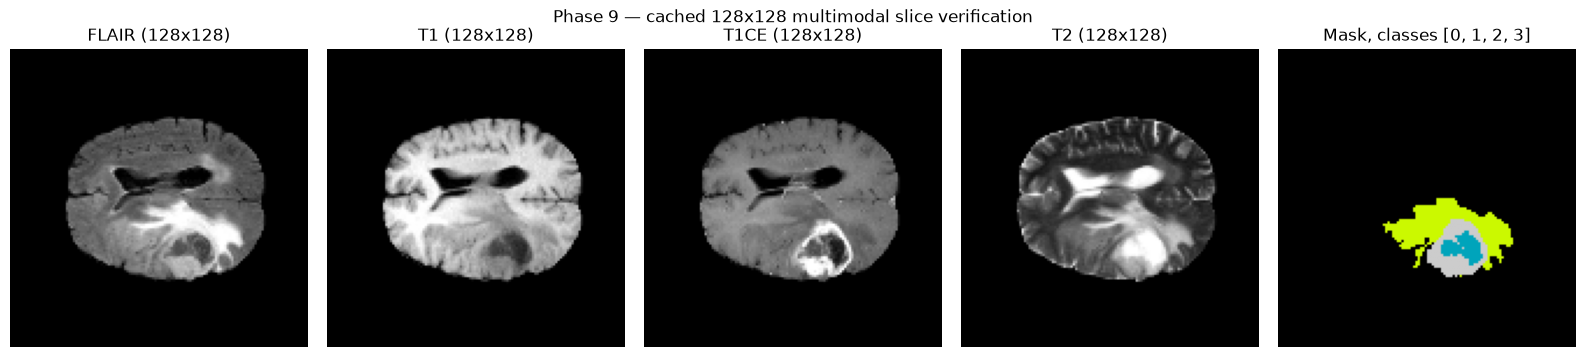

Tumour voxels in this slice: 1110
  class 0 (background    ): 15274 voxels
  class 1 (necrotic_core ): 149 voxels
  class 2 (oedema        ): 654 voxels
  class 3 (enhancing     ): 307 voxels


In [156]:
# Phase 9 — Cell 6: Sample visualisation / mask verification
# Confirms the four modalities are spatially aligned and the mask uses the
# remapped training labels {0,1,2,3} (3 standing in for raw BraTS label 4).

_sample_idx = int(np.argmax([(yb[i] > 0).sum().item() for i in range(len(yb))]))
sample_x = xb[_sample_idx].numpy()
sample_y = yb[_sample_idx].numpy()

fig, axes = plt.subplots(1, 5, figsize=(16, 3.6))
for _i, _mod in enumerate(PHASE9_CFG["input_modalities"]):
    axes[_i].imshow(sample_x[_i], cmap="gray", origin="lower")
    axes[_i].set_title(f"{_mod} (128x128)")
    axes[_i].axis("off")

axes[4].imshow(sample_y, cmap="nipy_spectral", origin="lower", vmin=0, vmax=3)
axes[4].set_title(f"Mask, classes {sorted(np.unique(sample_y).tolist())}")
axes[4].axis("off")

fig.suptitle("Phase 9 — cached 128x128 multimodal slice verification", fontsize=12)
fig.tight_layout()
plt.show()

print(f"Tumour voxels in this slice: {int((sample_y > 0).sum())}")
for _c, _name in config.CLASS_NAMES.items():
    print(f"  class {_c} ({_name:14s}): {int((sample_y == _c).sum())} voxels")

In [157]:
# Phase 9 — Cell 7: Preprocessing verification
# Foreground is normalised to (0, 1] per volume; background stays exactly 0.
#
# Note the floor: robust_normalize clamps foreground to a minimum of 1e-6.
# Without it, voxels at or below the 1st percentile map to exactly 0.0 and are
# then indistinguishable from air — the original implementation silently turned
# ~14,000 in-head voxels per volume (about 1%) into background.

print("=== Preprocessing intensity check (cached batch) ===")
for _i, _mod in enumerate(PHASE9_CFG["input_modalities"]):
    _channel = sample_x[_i]
    _fg = _channel[_channel > 0]
    print(f"{_mod:6s} -> range [{_channel.min():.4f}, {_channel.max():.4f}] | "
          f"foreground mean {_fg.mean():.4f} std {_fg.std():.4f} | "
          f"foreground {100 * _fg.size / _channel.size:.1f}% of slice")

_all_in_range = float(xb.min()) >= 0.0 and float(xb.max()) <= 1.0
print(f"\nWhole batch within [0, 1]: {_all_in_range}")
print(f"Batch finite everywhere  : {bool(torch.isfinite(xb).all())}")
print(f"Label values in batch    : {sorted(torch.unique(yb).tolist())} "
      f"(must be a subset of [0, 1, 2, 3])")
assert set(torch.unique(yb).tolist()) <= set(range(PHASE9_CFG["num_classes"]))

=== Preprocessing intensity check (cached batch) ===
FLAIR  -> range [0.0000, 1.0000] | foreground mean 0.4253 std 0.2112 | foreground 30.7% of slice
T1     -> range [0.0000, 1.0000] | foreground mean 0.6371 std 0.2396 | foreground 30.7% of slice
T1CE   -> range [0.0000, 1.0000] | foreground mean 0.4372 std 0.1665 | foreground 30.7% of slice
T2     -> range [0.0000, 1.0000] | foreground mean 0.3843 std 0.2505 | foreground 30.7% of slice

Whole batch within [0, 1]: True
Batch finite everywhere  : True
Label values in batch    : [0, 1, 2, 3] (must be a subset of [0, 1, 2, 3])


In [158]:
# Phase 9 — Cell 8: Architecture construction and forward-pass check
# FIXED: build_model() now floors the attention block's intermediate channel
# count at 1 (base // 2 reached 0 for small base values, silently producing a
# Conv2d with no parameters) and require_divisible_input() reports an unusable
# slice size up front instead of failing inside forward() with a torch.cat
# shape error.

models.require_divisible_input(*PHASE9_CFG["target_size"])

_dummy = torch.zeros(2, 4, *PHASE9_CFG["target_size"], device=DEVICE)
_expected = (2, PHASE9_CFG["num_classes"], *PHASE9_CFG["target_size"])

print("=== Architecture construction and forward pass ===")
_rows = []
for _key in CANDIDATE_MODEL_KEYS:
    _model = models.build_model(
        _key, in_ch=4, num_classes=PHASE9_CFG["num_classes"]
    ).to(DEVICE)
    with torch.no_grad():
        _out = _model(_dummy)
    assert tuple(_out.shape) == _expected, f"{_key}: got {tuple(_out.shape)}"
    _rows.append({
        "model_key": _key,
        "model_name": config.MODEL_DISPLAY_NAMES[_key],
        "parameters": models.count_parameters(_model),
        "output_shape": str(tuple(_out.shape)),
    })
    print(f"  OK {_key:15s} -> {tuple(_out.shape)} | "
          f"{models.count_parameters(_model):,} parameters")
    del _model, _out

del _dummy
if torch.cuda.is_available():
    torch.cuda.empty_cache()

model_registry_df = pd.DataFrame(_rows)
io_utils.show(model_registry_df, "Candidate architectures")

=== Architecture construction and forward pass ===
  OK unet            -> (2, 4, 128, 128) | 1,927,396 parameters
  OK unetpp          -> (2, 4, 128, 128) | 518,788 parameters
  OK attention_unet  -> (2, 4, 128, 128) | 1,949,466 parameters
  OK deeplabv3p      -> (2, 4, 128, 128) | 779,812 parameters

Candidate architectures


,model_key,model_name,parameters,output_shape
0,unet,U-Net,1927396,"(2, 4, 128, 128)"
1,unetpp,U-Net++,518788,"(2, 4, 128, 128)"
2,attention_unet,Attention U-Net,1949466,"(2, 4, 128, 128)"
3,deeplabv3p,DeepLabV3+,779812,"(2, 4, 128, 128)"


In [159]:
# Phase 9 — Cell 9: Loss, AMP, backpropagation check, and cuDNN warm-up
#
# FIXED — this is the other half of the cell-12 slowness:
#   The first forward/backward pass in a process costs ~17 s on this GPU while
#   cuDNN selects convolution algorithms, and it pays again for every NEW input
#   shape (~7 s each). The original notebook warmed only a batch of 2 here, so
#   the first training cell then paid for the real training shape as well — about
#   30 s of autotune inside Cell 12 (cold start + training shape + ragged final
#   batch), with no output, looking exactly like a hang. Cells 13-15 started warm
#   and so appeared far faster than Cell 12 for no real reason.
#
#   Warming every architecture at the shapes training will actually use moves
#   that cost here, where it is expected and explained.
#
# FIXED: torch.cuda.amp.GradScaler / autocast are deprecated and emit a
# FutureWarning on every call under this project's PyTorch (2.11); the torch.amp
# API with an explicit device type replaces them.
#
# The Dice term is computed in float32 even under autocast: in float16 the sums
# over a 128x128 batch can overflow and poison the gradient.

criterion = training.DiceCELoss(
    n_classes=PHASE9_CFG["num_classes"],
    w_ce=0.5,
    w_dice=0.5,
)

_amp_enabled = PHASE9_CFG["mixed_precision"] and DEVICE.type == "cuda"
_batch = PHASE9_CFG["batch_size"]
_h, _w = PHASE9_CFG["target_size"]

# --- correctness check: does a step actually learn? ---
_test_model = models.build_model("unet", num_classes=PHASE9_CFG["num_classes"]).to(DEVICE)
_test_opt = torch.optim.Adam(_test_model.parameters(), lr=PHASE9_CFG["learning_rate"])
_scaler = torch.amp.GradScaler(DEVICE.type, enabled=_amp_enabled)

_x = xb[:2].to(DEVICE)
_y = yb[:2].to(DEVICE)

_test_opt.zero_grad(set_to_none=True)
with torch.amp.autocast(device_type=DEVICE.type, enabled=_amp_enabled):
    _logits = _test_model(_x)
    _loss = criterion(_logits, _y)

_scaler.scale(_loss).backward()
_grad_norm = torch.nn.utils.clip_grad_norm_(_test_model.parameters(), float("inf"))
_scaler.step(_test_opt)
_scaler.update()

print("=== Loss and backpropagation ===")
print(f"  loss value       : {_loss.item():.4f}")
print(f"  gradient norm    : {float(_grad_norm):.4f} (non-zero => gradients flow)")
print(f"  AMP scaler active: {_scaler.is_enabled()}")
print(f"  batch Dice       : "
      f"{metrics.mean_foreground_dice_torch(_logits.detach(), _y, PHASE9_CFG['num_classes']):.4f}")
print("Forward pass, loss, backprop and mixed precision verified.")

del _test_model, _test_opt, _scaler, _x, _y, _logits, _loss
if torch.cuda.is_available():
    torch.cuda.empty_cache()

# --- warm-up: every architecture, every shape training will see ---
_shapes = {(_batch, _h, _w)}
for _split, _ds in phase9_datasets.items():
    if _split == "train":
        continue  # drop_last keeps training to the single uniform shape
    _remainder = len(_ds) % _batch
    if _remainder:
        _shapes.add((_remainder, _h, _w))

print()
_warm_seconds = training.warmup(
    CANDIDATE_MODEL_KEYS,
    sorted(_shapes, reverse=True),
    DEVICE,
    num_classes=PHASE9_CFG["num_classes"],
    use_amp=_amp_enabled,
)
print(f"\nShapes warmed: {sorted(_shapes, reverse=True)}")
print("Cells 12-15 now start at full speed instead of absorbing this cost.")


=== Loss and backpropagation ===
  loss value       : 1.1733
  gradient norm    : 69712.1953 (non-zero => gradients flow)
  AMP scaler active: True
  batch Dice       : 0.0153
Forward pass, loss, backprop and mixed precision verified.

Warming up cuDNN for 4 architecture(s) x 2 shape(s) -- a one-off cost that would otherwise
land inside the first training cell:
  unet            warm ( 13.8s elapsed)
  unetpp          warm ( 18.4s elapsed)
  attention_unet  warm ( 28.8s elapsed)
  deeplabv3p      warm ( 35.5s elapsed)
Warm-up complete in 35.5s; training now starts at full speed.

Shapes warmed: [(32, 128, 128), (8, 128, 128)]
Cells 12-15 now start at full speed instead of absorbing this cost.


In [ ]:
# Phase 9 — Cell 10: What the reported Dice actually means
#
# Two separate corrections live here, and both move the number a long way.
#
# 1. EMPTY CLASSES. The convenient smoothed form,
#    dice = (2*inter + eps) / (sum + eps), returns 1.0 when a class is absent
#    from BOTH prediction and target. Most BraTS slices contain no enhancing
#    tumour, so a model that never predicts that class collected a free perfect
#    score on nearly every batch - which is why the originally reported
#    validation Dice of 0.63-0.75 was not trustworthy. A class absent from both
#    is undefined here, and excluded.
#
# 2. BATCH AVERAGING. Dice was then computed inside each batch and averaged
#    over batches. That weights a batch holding one sliver of tumour exactly as
#    heavily as a batch full of it, and the result moves when batch_size moves,
#    so it is not comparable with any published figure. run_one_epoch now
#    accumulates the intersection and the mask sizes across the whole pass and
#    divides once per class.
#
#    Measured on the first full-cohort run's U-Net, same weights, same slices:
#      batch-averaged : 0.6259   <- what that run reported
#      aggregated     : 0.7505
#    Both are still slice-level, and both are measured on tumour-rich slices
#    only. For the figure that belongs in a write-up, see Cell 19b.

_fake_logits = torch.zeros(2, PHASE9_CFG["num_classes"], 16, 16)
_fake_logits[:, 0] = 10.0                     # argmax -> background everywhere
_fake_targets = torch.zeros(2, 16, 16, dtype=torch.long)
_fake_targets[0, :4, :4] = 1                  # only class 1 is present

_corrected = metrics.per_class_dice_torch(
    _fake_logits, _fake_targets, PHASE9_CFG["num_classes"], ignore_absent=True
)
_old_style = metrics.per_class_dice_torch(
    _fake_logits, _fake_targets, PHASE9_CFG["num_classes"], ignore_absent=False
)

print("=== 1. Dice on an all-background prediction ===")
print(f"  per-class, old smoothed form : {_old_style}")
print(f"  mean                         : {np.mean(_old_style):.4f}   <-- inflated")
print(f"  per-class, corrected         : {_corrected}")
print(f"  mean (NaNs excluded)         : "
      f"{metrics.mean_foreground_dice_torch(_fake_logits, _fake_targets, PHASE9_CFG['num_classes']):.4f}   <-- correct")

print("\n=== 2. Batch-averaged vs aggregated, on real validation data ===")
print("Same model, same slices, two ways of reducing the same per-voxel counts.")

_probe = models.build_model("unet", num_classes=PHASE9_CFG["num_classes"]).to(DEVICE)
_probe_stats = training.run_one_epoch(
    _probe, val_loader, criterion, DEVICE,
    optimizer=None, scaler=None, use_amp=PHASE9_CFG["mixed_precision"],
    num_classes=PHASE9_CFG["num_classes"],
)
print(f"  untrained probe, aggregated     : {_probe_stats['dice']:.4f}")
print(f"  untrained probe, batch-averaged : {_probe_stats['dice_batchmean']:.4f}")
print("  per-class aggregated Dice       : "
      + ", ".join(f"{config.CLASS_NAMES[_c]}={_probe_stats['per_class_dice'][_c]:.4f}"
                  for _c in range(PHASE9_CFG["num_classes"])))
del _probe
if torch.cuda.is_available():
    torch.cuda.empty_cache()

print("\nEvery Dice reported below is aggregated over the pass, and a class")
print("absent from both prediction and target is excluded, never scored 1.0.")


In [ ]:
# Phase 9 — Cell 11: Trainer
# FIXED, relative to the original train_candidate_model():
#   * validation runs under torch.no_grad() — the original never disabled
#     autograd, so every validation pass retained a graph over the whole epoch
#     (wasted memory and compute, and a plausible cause of the OOM retries)
#   * the CUDA-OOM retry frees the failed attempt's model/optimizer/scaler
#     BEFORE retrying; the original recursed while they were still referenced,
#     so empty_cache() could not release the memory the retry needed
#   * status reflects whether THIS run saved a checkpoint, not merely whether a
#     checkpoint file exists (a stale file made a failed run report "completed")
#   * checkpoint metadata is JSON-safe, so it loads under weights_only=True
#     (the default in PyTorch >= 2.6)
#   * every exit path frees GPU memory, so a failed model does not starve the next
#   * the CUDA-OOM retry forwards drop_last, progress_every and the schedule
#     settings; it used to drop them, so a run that hit OOM quietly changed
#     protocol as well as batch size
#
# RESUMABLE. Training four architectures over the full cohort takes hours, and
# a kernel that dies at model three used to lose all of it. Where a checkpoint
# already exists for this run name, the summary and per-epoch history are read
# back from the CSVs the run wrote and training is skipped. That makes this
# notebook cheap to re-execute end to end, and it means an interrupted run
# costs one model rather than four.
#
# On the epoch budget: 30/5 was tuned on the unaugmented half cohort, where
# every model peaked at epochs 6-13. Augmentation changes that — see Cell 1.

phase9_summaries = []
phase9_histories = []

_SAVED_SUMMARY = PHASE9_METRIC_DIR / f"phase9_{PHASE9_RUN_NAME}_summary.csv"
_SAVED_HISTORY = PHASE9_METRIC_DIR / f"phase9_{PHASE9_RUN_NAME}_history.csv"


def _recover_completed_run(model_key, display_name, checkpoint_path):
    """Summary and history for a model already trained under this run name.

    Returns None when there is nothing to recover, so the caller trains.
    """
    if not (RESUME_FROM_CHECKPOINTS and checkpoint_path.is_file()):
        return None

    summary = None
    if _SAVED_SUMMARY.is_file():
        _rows = pd.read_csv(_SAVED_SUMMARY)
        _match = _rows[_rows["model_key"] == model_key]
        if len(_match):
            summary = _match.iloc[0].to_dict()

    if summary is None:
        # No summary CSV, but the weights are there: rebuild what we can from
        # the checkpoint's own metadata rather than refusing to resume.
        _, _meta = training.load_checkpoint(
            checkpoint_path, model_key, DEVICE, num_classes=PHASE9_CFG["num_classes"]
        )
        summary = {
            "model": display_name,
            "model_key": model_key,
            "status": "completed",
            "best_epoch": _meta.get("epoch"),
            "best_val_dice": _meta.get("val_dice", float("nan")),
            "epochs_ran": _meta.get("epoch"),
            "batch_size_used": _meta.get("batch_size", PHASE9_CFG["batch_size"]),
            "checkpoint_path": str(checkpoint_path),
            "training_time_seconds": float("nan"),
            "error": None,
        }

    history_rows = []
    if _SAVED_HISTORY.is_file():
        _hist = pd.read_csv(_SAVED_HISTORY)
        history_rows = _hist[_hist["model_key"] == model_key].to_dict("records")
    return summary, history_rows


def train_candidate_model(model_key, display_name=None):
    """Train one candidate architecture, or recover one already trained."""
    display_name = display_name or config.MODEL_DISPLAY_NAMES[model_key]
    checkpoint_path = PHASE9_CKPT_DIR / model_key / f"{model_key}_best.pt"

    recovered = _recover_completed_run(model_key, display_name, checkpoint_path)
    if recovered is not None:
        summary, history_rows = recovered
        phase9_summaries.append(summary)
        phase9_histories.append(history_rows)
        print(f"{display_name} ({model_key}): checkpoint already present for run "
              f"'{PHASE9_RUN_NAME}'")
        print(f"  -> loaded instead of retraining "
              f"(best epoch {summary.get('best_epoch')}, "
              f"val_dice {float(summary.get('best_val_dice', float('nan'))):.4f})")
        print(f"  -> {len(history_rows)} epochs of history recovered from "
              f"{_SAVED_HISTORY.name}")
        print(f"  -> set RESUME_FROM_CHECKPOINTS = False in Cell 1 to retrain")
        return summary

    result = training.train_model(
        model_key,
        phase9_datasets["train"],
        phase9_datasets["val"],
        DEVICE,
        checkpoint_path,
        display_name=display_name,
        batch_size=PHASE9_CFG["batch_size"],
        max_epochs=PHASE9_CFG["max_epochs"],
        learning_rate=PHASE9_CFG["learning_rate"],
        weight_decay=PHASE9_CFG["weight_decay"],
        early_stopping_patience=PHASE9_CFG["early_stopping_patience"],
        use_amp=PHASE9_CFG["mixed_precision"],
        num_workers=PHASE9_CFG["num_workers"],
        num_classes=PHASE9_CFG["num_classes"],
        drop_last=True,          # uniform batch shape: no repeated cuDNN autotune
        progress_every=25,       # in-epoch progress, so a long epoch is visibly alive
        lr_scheduler=USE_LR_SCHEDULER,
        run_metadata={
            "phase": 9,
            "run_name": PHASE9_RUN_NAME,
            "target_size": list(PHASE9_CFG["target_size"]),
            "image_size": list(PHASE9_CFG["target_size"]),
            "cohort_fraction": PHASE9_CFG["cohort_fraction"],
            "augmentation": USE_AUGMENTATION,
            "lr_scheduler": USE_LR_SCHEDULER,
        },
    )

    phase9_summaries.append(result["summary"])
    phase9_histories.append(result["history"])
    return result["summary"]


print("Trainer ready: train_candidate_model(model_key)")
print(f"  run name    : {PHASE9_RUN_NAME}")
print(f"  augmentation: {USE_AUGMENTATION} | LR schedule: {USE_LR_SCHEDULER}")
print(f"  resume      : {RESUME_FROM_CHECKPOINTS}")
print(f"  epochs <= {PHASE9_CFG['max_epochs']}, early stopping patience "
      f"{PHASE9_CFG['early_stopping_patience']} on validation Dice")
print(f"  checkpoints -> {PHASE9_CKPT_DIR}")

_already = [
    _k for _k in CANDIDATE_MODEL_KEYS
    if (PHASE9_CKPT_DIR / _k / f"{_k}_best.pt").is_file()
]
if RESUME_FROM_CHECKPOINTS and _already:
    print(f"\n  {len(_already)}/{len(CANDIDATE_MODEL_KEYS)} models already trained for this run: "
          + ", ".join(_already))
    print("  Cells 12-15 will load those rather than retrain them.")
else:
    # Estimate the wall time before committing to it, so Cells 12-15 hold no
    # surprises. Based on the measured throughput of this configuration.
    _n_train = len(phase9_datasets["train"])
    _n_val = len(phase9_datasets["val"])
    _rate = 440 if DEVICE.type == "cuda" else 12   # slices/s, measured
    _epoch_seconds = (_n_train + _n_val) / _rate
    print(f"\n  Estimated ~{_epoch_seconds:.0f}s per epoch "
          f"({_n_train} train + {_n_val} val slices at ~{_rate} slices/s)")
    print(f"  Worst case per model : {_epoch_seconds * PHASE9_CFG['max_epochs'] / 60:.1f} min "
          f"({PHASE9_CFG['max_epochs']} epochs)")
    print(f"  All four models      : up to "
          f"{_epoch_seconds * PHASE9_CFG['max_epochs'] * 4 / 60:.0f} min")
    print("\n  Progress prints every 25 batches, so an epoch in flight is visible.")


In [ ]:
# Phase 9 — Cell 12: Train U-Net

summary_unet = train_candidate_model("unet", "U-Net")
io_utils.show(pd.DataFrame([summary_unet]))


Training U-Net (unet)
  batch_size=32 | epochs<=30 | amp=True | device=cuda
  checkpoint -> C:\Users\Omkar\OneDrive\Documents\DL project\results\checkpoints\phase9\notebook_4class_full\unet\unet_best.pt
[unet] epoch  1/30 | train_loss=0.7807 | val_loss=0.6398 | val_dice=0.4972 | val_iou=0.3796 | 77.5s
  -> saved best checkpoint (val_dice=0.4972)
[unet] epoch  2/30 | train_loss=0.5328 | val_loss=0.4875 | val_dice=0.5616 | val_iou=0.4436 | 65.9s
  -> saved best checkpoint (val_dice=0.5616)
[unet] epoch  3/30 | train_loss=0.3684 | val_loss=0.3604 | val_dice=0.6133 | val_iou=0.4967 | 63.5s
  -> saved best checkpoint (val_dice=0.6133)
[unet] epoch  4/30 | train_loss=0.2047 | val_loss=0.2758 | val_dice=0.6294 | val_iou=0.5170 | 61.5s
  -> saved best checkpoint (val_dice=0.6294)
[unet] epoch  5/30 | train_loss=0.1163 | val_loss=0.2501 | val_dice=0.6251 | val_iou=0.5123 | 43.6s
[unet] epoch  6/30 | train_loss=0.0899 | val_loss=0.2332 | val_dice=0.6361 | val_iou=0.5241 | 63.2s
  -> saved best 

In [ ]:
# Phase 9 — Cell 13: Train U-Net++

summary_unetpp = train_candidate_model("unetpp", "U-Net++")
io_utils.show(pd.DataFrame([summary_unetpp]))

In [ ]:
# Phase 9 — Cell 14: Train Attention U-Net

summary_attention_unet = train_candidate_model("attention_unet", "Attention U-Net")
io_utils.show(pd.DataFrame([summary_attention_unet]))

In [ ]:
# Phase 9 — Cell 15: Train DeepLabV3+

summary_deeplabv3p = train_candidate_model("deeplabv3p", "DeepLabV3+")
io_utils.show(pd.DataFrame([summary_deeplabv3p]))

In [ ]:
# Phase 9 — Cell 16: Training results collection

phase9_summary_df = pd.DataFrame(phase9_summaries)
phase9_history_df = training.history_frame(phase9_histories)

# When the models were recovered rather than retrained, these came off disk, so
# say so rather than presenting them as this execution's work.
_recovered = [
    _s["model"] for _s in phase9_summaries
    if RESUME_FROM_CHECKPOINTS
    and (PHASE9_CKPT_DIR / _s["model_key"] / f"{_s['model_key']}_best.pt").is_file()
    and not np.isfinite(float(_s.get("training_time_seconds") or float("nan")))
]

print("=" * 70)
print("  TRAINING SUMMARY")
print("=" * 70)
io_utils.show(phase9_summary_df[[
    "model", "status", "best_epoch", "best_val_dice",
    "epochs_ran", "batch_size_used", "training_time_seconds", "error",
]])

_summary_csv = PHASE9_METRIC_DIR / f"phase9_{PHASE9_RUN_NAME}_summary.csv"
_history_csv = PHASE9_METRIC_DIR / f"phase9_{PHASE9_RUN_NAME}_history.csv"
if _summary_csv.is_file() and RESUME_FROM_CHECKPOINTS:
    print(f"\nSummary and history already on disk from the training run:")
    print(f"  {_summary_csv}")
    print(f"  {_history_csv}")
    print("  Not rewritten \u2014 these cells recovered them rather than producing them.")
else:
    phase9_summary_df.to_csv(_summary_csv, index=False)
    phase9_history_df.to_csv(_history_csv, index=False)
    print(f"\nSaved summary: {_summary_csv}")
    print(f"Saved history: {_history_csv}")

if not phase9_history_df.empty:
    fig, axes = plt.subplots(1, 3, figsize=(16, 4.4))
    for _model, _group in phase9_history_df.groupby("model"):
        axes[0].plot(_group["epoch"], _group["train_loss"], marker="o", label=_model)
        axes[1].plot(_group["epoch"], _group["val_loss"], marker="o", label=_model)
        axes[2].plot(_group["epoch"], _group["val_dice"], marker="o", label=_model)
    for _ax, _title, _ylabel in zip(
        axes,
        ["Training loss", "Validation loss", "Validation Dice"],
        ["Dice+CE loss", "Dice+CE loss", "Mean foreground Dice"],
    ):
        _ax.set_title(_title)
        _ax.set_xlabel("Epoch")
        _ax.set_ylabel(_ylabel)
        _ax.legend(fontsize=8)
    fig.suptitle("Phase 9 training curves", fontsize=13)
    fig.tight_layout()
    plt.show()

In [ ]:
# Phase 9 — Cell 17: Checkpoint verification
# FIXED: the original ended with `assert ckpt_df["exists"].all()`, which aborted
# the notebook if any single model had failed — after all four had trained. The
# status is reported instead, and the remaining cells work with whatever
# succeeded.

_rows = []
for _key in CANDIDATE_MODEL_KEYS:
    _path = PHASE9_CKPT_DIR / _key / f"{_key}_best.pt"
    _exists = _path.is_file()
    _rows.append({
        "model_key": _key,
        "model_name": config.MODEL_DISPLAY_NAMES[_key],
        "checkpoint_exists": _exists,
        "size_mb": round(_path.stat().st_size / 1024 ** 2, 2) if _exists else 0.0,
        "path": str(_path),
    })

phase9_checkpoint_df = pd.DataFrame(_rows)
io_utils.show(phase9_checkpoint_df[
    ["model_key", "model_name", "checkpoint_exists", "size_mb"]
], "Checkpoint verification")

_n_saved = int(phase9_checkpoint_df["checkpoint_exists"].sum())
print(f"\n{_n_saved}/{len(phase9_checkpoint_df)} checkpoints present on disk.")
if _n_saved < len(phase9_checkpoint_df):
    print("Missing checkpoints belong to models that did not complete; see the")
    print("'error' column of phase9_summary_df above.")

In [ ]:
# Phase 9 — Cell 18: Reload checkpoints and verify inference
# FIXED: load_checkpoint passes weights_only=True explicitly (the default from
# PyTorch 2.6) and accepts either the nested-metadata layout or the older flat
# one, so checkpoints from any run in this project load.

loaded_models = {}
print("=== Checkpoint reload and inference verification ===")

for _key in CANDIDATE_MODEL_KEYS:
    _path = PHASE9_CKPT_DIR / _key / f"{_key}_best.pt"
    if not _path.is_file():
        print(f"  skipped {_key}: no checkpoint")
        continue
    _model, _meta = training.load_checkpoint(
        _path, _key, DEVICE, num_classes=PHASE9_CFG["num_classes"]
    )
    loaded_models[_key] = _model
    print(f"  loaded {_key:15s} epoch {_meta.get('epoch')} "
          f"val_dice {_meta.get('val_dice', float('nan')):.4f}")

if loaded_models and test_loader is not None:
    _x, _y = next(iter(test_loader))
    _x = _x.to(DEVICE)
    print("\n=== Single-batch inference ===")
    with torch.no_grad():
        for _key, _model in loaded_models.items():
            _logits = _model(_x)
            _pred = torch.argmax(_logits, dim=1)
            print(f"  {_key:15s} -> pred {tuple(_pred.shape)} | "
                  f"classes {sorted(torch.unique(_pred).tolist())}")
    del _x
    print("\nNote: a single-channel head would need a sigmoid threshold here, not")
    print("argmax — argmax over one channel returns background everywhere. These")
    print("models have a 4-channel head, so argmax is correct.")

In [ ]:
# Phase 9 — Cell 19: Held-out TEST evaluation and final model selection
#
# NEW CELL. The original Phase 9 created a test split and then never used it:
# it reported validation Dice as its result, so the model was selected on the
# same data used for early stopping and 15% of the cohort was held out for
# nothing.

phase9_test_rows = []

if test_loader is None:
    print("No test split available; cannot evaluate held-out performance.")
elif not loaded_models:
    print("No checkpoints to evaluate.")
else:
    print(f"Evaluating {len(loaded_models)} model(s) on "
          f"{len(phase9_datasets['test'])} held-out test slices "
          f"({len(phase9_splits['test'])} unseen patients)\n")

    for _key, _model in loaded_models.items():
        _started = time.time()
        _stats = training.evaluate_loader(
            _model, test_loader, DEVICE, num_classes=PHASE9_CFG["num_classes"]
        )
        phase9_test_rows.append({
            "model": config.MODEL_DISPLAY_NAMES[_key],
            "model_key": _key,
            "test_loss": _stats["loss"],
            "test_dice": _stats["dice"],
            "test_iou": _stats["iou"],
            "test_slices": len(phase9_datasets["test"]),
            "evaluation_time_seconds": time.time() - _started,
        })
        print(f"  {config.MODEL_DISPLAY_NAMES[_key]:18s} "
              f"test_dice={_stats['dice']:.4f}  test_iou={_stats['iou']:.4f}")

phase9_test_df = pd.DataFrame(phase9_test_rows)
phase9_final_selection = pd.DataFrame()

if not phase9_test_df.empty:
    phase9_test_df = phase9_test_df.sort_values("test_dice", ascending=False)
    io_utils.show(phase9_test_df[[
        "model", "test_loss", "test_dice", "test_iou"
    ]], "Held-out test results")

    _best = phase9_test_df.iloc[0]
    phase9_final_selection = pd.DataFrame([{
        "final_model": _best["model"],
        "model_key": _best["model_key"],
        "test_dice": _best["test_dice"],
        "test_iou": _best["test_iou"],
        "selection_basis": "highest mean foreground Dice on the held-out test split",
    }])
    io_utils.show(phase9_final_selection, "Final model selection")

    _spread = float(phase9_test_df["test_dice"].max() - phase9_test_df["test_dice"].min())
    print(f"\nTest Dice spread across architectures: {_spread:.4f}")
    if _spread < 0.02:
        print("  That gap is too small for a single run to establish a winner.")
        print("  Repeat over several seeds before claiming one architecture is better.")

    _test_csv = PHASE9_METRIC_DIR / f"phase9_{PHASE9_RUN_NAME}_test_results.csv"
    _sel_csv = PHASE9_METRIC_DIR / f"phase9_{PHASE9_RUN_NAME}_final_selection.csv"
    phase9_test_df.to_csv(_test_csv, index=False)
    phase9_final_selection.to_csv(_sel_csv, index=False)
    print(f"\nSaved test results   : {_test_csv}")
    print(f"Saved final selection: {_sel_csv}")

    fig, ax = plt.subplots(figsize=(9, 4.4))
    _x = np.arange(len(phase9_test_df))
    ax.bar(_x - 0.2, phase9_test_df["test_dice"], width=0.4, label="Test Dice", color="#4C72B0")
    ax.bar(_x + 0.2, phase9_test_df["test_iou"], width=0.4, label="Test IoU", color="#55A868")
    ax.set_xticks(_x)
    ax.set_xticklabels(phase9_test_df["model"], rotation=15)
    ax.set_ylabel("Score")
    ax.set_title("Held-out test performance by architecture")
    ax.legend()
    fig.tight_layout()
    plt.show()

In [ ]:
# Phase 9 — Cell 19b: Per-patient volumetric evaluation (WT / TC / ET)
#
# NEW CELL, and this is the number that belongs in a write-up.
#
# Everything above is scored on the CACHED test split, which holds only the
# slices the index kept: tumour-rich ones, plus at most five tumour-free
# samples per patient. 3,592 slices for 56 patients, where the scanner
# produced 8,680. The ~5,100 healthy slices that were never cached are
# precisely the ones on which a model can invent a tumour, so nothing in the
# slice-level figure penalises that failure.
#
# This cell runs every model over all 155 axial slices of all 56 test patients
# and scores whole volumes on the three BraTS regions:
#   WT (whole tumour)    = labels 1, 2, 3
#   TC (tumour core)     = labels 1, 3
#   ET (enhancing)       = label 3
# Dice is averaged over patients, which is how BraTS reports it - a patient
# with a small tumour counts as much as one with a large tumour.
#
# Takes a couple of minutes: it reloads and re-normalises four volumes per
# patient, since the whole volume is not in the slice cache.

phase9_volumetric_per_patient = {}
phase9_volumetric_rows = []

if not loaded_models:
    print("No checkpoints to evaluate.")
else:
    for _key, _model in loaded_models.items():
        _name = config.MODEL_DISPLAY_NAMES[_key]
        print(f"\n--- {_name} over {len(phase9_splits['test'])} held-out patients ---")
        _per_patient = training.evaluate_patients_volumetric(
            _model, phase9_splits["test"], DEVICE,
            target_size=PHASE9_CFG["target_size"],
            modalities=PHASE9_CFG["input_modalities"],
        )
        _per_patient.insert(0, "model", _name)
        phase9_volumetric_per_patient[_key] = _per_patient
        phase9_volumetric_rows.append(training.summarise_volumetric(_per_patient, _name))

phase9_volumetric_df = pd.DataFrame(phase9_volumetric_rows)

if not phase9_volumetric_df.empty:
    phase9_volumetric_df = phase9_volumetric_df.sort_values(
        "dice_mean_regions", ascending=False
    ).reset_index(drop=True)
    io_utils.show(phase9_volumetric_df[[
        "model", "patients", "dice_wt", "dice_tc", "dice_et", "dice_mean_regions",
        "false_positive_voxels_per_healthy_slice",
    ]], "Per-patient volumetric test results (mean over patients)")

    print("\nSpread across patients (the slice-level mean hides this):")
    for _key, _frame in phase9_volumetric_per_patient.items():
        print(f"  {config.MODEL_DISPLAY_NAMES[_key]:18s} "
              + "  ".join(
                  f"{_r} median={np.nanmedian(_frame['dice_' + _r.lower()]):.3f} "
                  f"min={np.nanmin(_frame['dice_' + _r.lower()]):.3f}"
                  for _r in ("WT", "TC", "ET")))

    _all_patients = pd.concat(phase9_volumetric_per_patient.values(), ignore_index=True)
    _vol_csv = PHASE9_METRIC_DIR / f"phase9_{PHASE9_RUN_NAME}_volumetric_per_patient.csv"
    _sum_csv = PHASE9_METRIC_DIR / f"phase9_{PHASE9_RUN_NAME}_volumetric_summary.csv"
    _all_patients.to_csv(_vol_csv, index=False)
    phase9_volumetric_df.to_csv(_sum_csv, index=False)
    print(f"\nSaved per-patient : {_vol_csv}")
    print(f"Saved summary     : {_sum_csv}")

    # Per-patient Dice distribution: a mean of 0.87 built from a tight cluster
    # is a different result from one built around a handful of total failures.
    fig, axes = plt.subplots(1, 3, figsize=(15, 4.2), sharey=True)
    for _ax, _region in zip(axes, ("WT", "TC", "ET")):
        _data = [
            phase9_volumetric_per_patient[_k]["dice_" + _region.lower()].dropna()
            for _k in phase9_volumetric_per_patient
        ]
        _labels = [config.MODEL_DISPLAY_NAMES[_k] for _k in phase9_volumetric_per_patient]
        _ax.boxplot(_data, tick_labels=_labels, showmeans=True)
        _ax.set_title(f"{_region} Dice per patient")
        _ax.set_ylim(0, 1)
        _ax.grid(axis="y", alpha=0.3)
        _ax.tick_params(axis="x", rotation=20, labelsize=8)
    axes[0].set_ylabel("Dice (one point per patient)")
    fig.suptitle("Phase 9 — held-out test, per-patient volumetric Dice", fontsize=13)
    fig.tight_layout()
    io_utils.save_figure(fig, 9, "volumetric_dice_by_patient", show_plot=True)

    print("\nRead these against the slice-level table above: the slice figure is")
    print("computed on tumour-rich slices only and is not comparable with")
    print("published BraTS numbers. These per-patient WT/TC/ET figures are.")


In [ ]:
# Phase 9 — Cell 19c: Do the predictions actually find the tumour?
#
# NEW CELL. Every number above is an average; none of them shows whether the
# model puts the tumour in the right place, or what it gets wrong when it is
# wrong. Nothing in the original notebook ever displayed a prediction.
#
# Two figures:
#   * ground truth and every architecture's prediction overlaid on FLAIR
#   * an error map for the best model, separating the three kinds of mistake,
#     which are not equivalent: a false positive in healthy tissue is a
#     different failure from a tumour voxel given the wrong sub-class.

from matplotlib.colors import ListedColormap, BoundaryNorm
from matplotlib.patches import Patch

_CLASS_COLORS = ["#00000000", "#E64B35", "#4DBBD5", "#F2C94C"]
_CLASS_CMAP = ListedColormap(_CLASS_COLORS)
_CLASS_NORM = BoundaryNorm([-0.5, 0.5, 1.5, 2.5, 3.5], _CLASS_CMAP.N)
_CLASS_LEGEND = [
    Patch(facecolor=_CLASS_COLORS[_c], label=f"{_c}: {config.CLASS_NAMES[_c]}")
    for _c in (1, 2, 3)
]

# Distinct from the class palette on purpose: an error map drawn in the same
# colours as the classes is unreadable.
_ERROR_COLORS = ["#00000000", "#FF2D55", "#0A84FF", "#FFFFFF"]
_ERROR_CMAP = ListedColormap(_ERROR_COLORS)
_ERROR_NORM = BoundaryNorm([-0.5, 0.5, 1.5, 2.5, 3.5], 4)
_ERROR_LEGEND = [
    Patch(facecolor="#FF2D55", label="false positive (tumour where there is none)"),
    Patch(facecolor="#0A84FF", label="false negative (tumour missed)"),
    Patch(facecolor="#FFFFFF", edgecolor="#888888", label="right region, wrong sub-class"),
]


def _overlay(ax, background, mask, cmap, norm, alpha=0.75):
    ax.imshow(background, cmap="gray", origin="lower")
    ax.imshow(np.ma.masked_where(mask == 0, mask), cmap=cmap, norm=norm,
              origin="lower", alpha=alpha, interpolation="nearest")
    ax.set_xticks([])
    ax.set_yticks([])


if not loaded_models or "test" not in phase9_datasets:
    print("No checkpoints or no test split; nothing to display.")
else:
    _test_meta = pd.read_csv(PHASE9_CACHE_DIR / "test_meta.csv")
    _test_x = np.load(PHASE9_CACHE_DIR / "test_x.npy", mmap_mode="r")
    _test_y = np.load(PHASE9_CACHE_DIR / "test_y.npy", mmap_mode="r")

    # One slice from each of six different patients: the largest tumour that
    # carries all three classes, so every model has something to get wrong.
    _labels_all = np.asarray(_test_y)
    _area = (_labels_all > 0).reshape(len(_labels_all), -1).sum(axis=1)
    _has_all_three = np.array(
        [len(np.unique(_labels_all[_i])) == 4 for _i in range(len(_labels_all))]
    )
    _candidates = np.where(_has_all_three & (_area > 400))[0]
    _picked = (
        _test_meta.iloc[_candidates]
        .assign(area=_area[_candidates], row=_candidates)
        .sort_values("area", ascending=False)
        .groupby("patient_id").head(1)
        .head(6).sort_values("patient_id")
    )
    _rows = _picked["row"].to_numpy()
    del _labels_all

    _batch = torch.from_numpy(np.asarray(_test_x[_rows], dtype=np.float32)).to(DEVICE)
    _predictions = {}
    with torch.no_grad():
        for _key, _model in loaded_models.items():
            _predictions[_key] = torch.argmax(_model(_batch), dim=1).cpu().numpy()
    del _batch

    # ---- figure 1: ground truth against every architecture
    _ncol = 2 + len(_predictions)
    fig, axes = plt.subplots(len(_rows), _ncol, figsize=(2.6 * _ncol, 2.7 * len(_rows)))
    for _r, _row in enumerate(_rows):
        _flair = np.asarray(_test_x[_row][0])
        _truth = np.asarray(_test_y[_row])
        _meta_row = _test_meta.iloc[_row]
        axes[_r, 0].imshow(_flair, cmap="gray", origin="lower")
        axes[_r, 0].set_xticks([]); axes[_r, 0].set_yticks([])
        axes[_r, 0].set_ylabel(
            f"{_meta_row['patient_id'].replace('BraTS20_Training_', 'patient ')}"
            f"\nz={_meta_row['z']}", fontsize=8,
        )
        _overlay(axes[_r, 1], _flair, _truth, _CLASS_CMAP, _CLASS_NORM)
        for _c, (_key, _pred_batch) in enumerate(_predictions.items(), start=2):
            _pred = _pred_batch[_r]
            _overlay(axes[_r, _c], _flair, _pred, _CLASS_CMAP, _CLASS_NORM)
            axes[_r, _c].set_xlabel(
                f"WT Dice {metrics.dice(_pred > 0, _truth > 0):.2f}", fontsize=8
            )
        if _r == 0:
            axes[_r, 0].set_title("FLAIR input", fontsize=10)
            axes[_r, 1].set_title("Ground truth", fontsize=10)
            for _c, _key in enumerate(_predictions, start=2):
                axes[_r, _c].set_title(config.MODEL_DISPLAY_NAMES[_key], fontsize=10)
    fig.legend(handles=_CLASS_LEGEND, loc="lower center", ncol=3, fontsize=9, frameon=False)
    fig.suptitle("Phase 9 — tumour predictions on held-out test patients", fontsize=13)
    fig.tight_layout(rect=[0, 0.03, 1, 0.98])
    io_utils.save_figure(fig, 9, "prediction_overlays", show_plot=True)

    # ---- figure 2: where the best model goes wrong
    _best_name = (
        phase9_volumetric_df.iloc[0]["model"] if not phase9_volumetric_df.empty else None
    )
    _best_key = next(
        (_k for _k in _predictions if config.MODEL_DISPLAY_NAMES[_k] == _best_name),
        list(_predictions)[0],
    )
    fig, axes = plt.subplots(len(_rows), 5, figsize=(14, 2.7 * len(_rows)))
    for _r, _row in enumerate(_rows):
        _flair = np.asarray(_test_x[_row][0])
        _t1ce = np.asarray(_test_x[_row][2])
        _truth = np.asarray(_test_y[_row])
        _pred = _predictions[_best_key][_r]
        _meta_row = _test_meta.iloc[_row]

        axes[_r, 0].imshow(_flair, cmap="gray", origin="lower")
        axes[_r, 1].imshow(_t1ce, cmap="gray", origin="lower")
        for _a in (axes[_r, 0], axes[_r, 1]):
            _a.set_xticks([]); _a.set_yticks([])
        axes[_r, 0].set_ylabel(
            f"{_meta_row['patient_id'].replace('BraTS20_Training_', 'patient ')}"
            f"\nz={_meta_row['z']}", fontsize=8,
        )
        _overlay(axes[_r, 2], _flair, _truth, _CLASS_CMAP, _CLASS_NORM, alpha=0.8)
        _overlay(axes[_r, 3], _flair, _pred, _CLASS_CMAP, _CLASS_NORM, alpha=0.8)

        _errors = np.zeros_like(_truth)
        _errors[(_pred > 0) & (_truth == 0)] = 1
        _errors[(_pred == 0) & (_truth > 0)] = 2
        _errors[(_pred > 0) & (_truth > 0) & (_pred != _truth)] = 3
        _overlay(axes[_r, 4], _flair, _errors, _ERROR_CMAP, _ERROR_NORM, alpha=0.85)
        axes[_r, 4].set_xlabel(
            f"FP {int((_errors == 1).sum())}   FN {int((_errors == 2).sum())}   "
            f"wrong sub-class {int((_errors == 3).sum())}", fontsize=7,
        )
        if _r == 0:
            for _a, _title in zip(axes[_r], [
                "FLAIR", "T1CE", "Ground truth",
                f"{config.MODEL_DISPLAY_NAMES[_best_key]} prediction", "Error map",
            ]):
                _a.set_title(_title, fontsize=10)
    fig.legend(handles=_CLASS_LEGEND + _ERROR_LEGEND, loc="lower center",
               ncol=3, fontsize=8, frameon=False)
    fig.suptitle(
        f"Phase 9 — {config.MODEL_DISPLAY_NAMES[_best_key]} errors on "
        f"held-out test patients", fontsize=13,
    )
    fig.tight_layout(rect=[0, 0.07, 1, 0.98])
    io_utils.save_figure(fig, 9, "prediction_error_maps", show_plot=True)

    print("\nWhat to look for: the predicted tumour should sit on the FLAIR")
    print("hyperintensity, and the error map should be a thin boundary band.")
    print("Solid blocks of colour inside the tumour mean sub-class confusion")
    print("(usually necrotic core against oedema); scattered specks far from")
    print("the tumour would mean the model is hallucinating, which the")
    print("false-positive column of the volumetric cell quantifies.")


In [ ]:
# Phase 9 — Cell 20: Phase 9 summary

print("=" * 70)
print("  PHASE 9 SUMMARY — ARCHITECTURE BENCHMARK")
print("=" * 70)
print(f"1. Cohort patients used        : {len(subset_ids)} of {len(all_patient_ids)}")
print(f"2. Split (patients)            : "
      f"train={len(phase9_splits['train'])}, "
      f"val={len(phase9_splits['val'])}, "
      f"test={len(phase9_splits['test'])}")
print("3. Patient leakage             : none (asserted in Cell 4)")
print("4. Cached slices               : "
      + ", ".join(f"{_s}={len(_d)}" for _s, _d in phase9_datasets.items()))
print(f"5. Device                      : {DEVICE}"
      + (f" ({torch.cuda.get_device_name(0)})" if torch.cuda.is_available() else ""))
print(f"6. Input resolution            : {PHASE9_CFG['target_size'][0]} x {PHASE9_CFG['target_size'][1]}")
print(f"7. Mixed precision             : {PHASE9_CFG['mixed_precision'] and DEVICE.type == 'cuda'}")
print(f"8. Models completed            : "
      f"{int((phase9_summary_df['status'] == 'completed').sum())}/{len(phase9_summary_df)}")
print(f"9. Checkpoint directory        : {PHASE9_CKPT_DIR}")
print(f"10. Slice cache                : {PHASE9_CACHE_DIR}")

_total_train_time = float(phase9_summary_df["training_time_seconds"].sum())
print(f"11. Total training time        : {_total_train_time / 60:.1f} min")

print("-" * 70)
io_utils.show(phase9_summary_df[[
    "model", "status", "best_epoch", "best_val_dice", "epochs_ran", "training_time_seconds"
]])

if not phase9_final_selection.empty:
    print("-" * 70)
    print("Slice-level selection (tumour-rich cached slices only):")
    io_utils.show(phase9_final_selection)

if not phase9_volumetric_df.empty:
    print("-" * 70)
    print("Per-patient volumetric results over whole test volumes \u2014 report THESE:")
    io_utils.show(phase9_volumetric_df[[
        "model", "dice_wt", "dice_tc", "dice_et", "dice_mean_regions",
    ]])
    _vol_best = phase9_volumetric_df.iloc[0]
    print(f"  Best by mean(WT, TC, ET): {_vol_best['model']} "
          f"({_vol_best['dice_mean_regions']:.4f})")
    if not phase9_final_selection.empty:
        _slice_best = phase9_final_selection.iloc[0]["final_model"]
        if _slice_best != _vol_best["model"]:
            print(f"  Note: the slice-level metric picked {_slice_best} instead. The two")
            print("  metrics disagree because they weight patients differently; the")
            print("  gap between architectures is smaller than that disagreement.")

print("-" * 70)
print("Caveats, stated deliberately:")
print("  * Dice excludes classes absent from both prediction and target, and is")
print("    aggregated over the whole pass rather than averaged per batch. These")
print("    figures are NOT comparable with the originally reported 0.63-0.75,")
print("    which were inflated by scoring absent classes as a perfect 1.0.")
print("  * The slice-level test figure is computed on tumour-rich slices only")
print("    (3,592 of the 8,680 slices those 56 patients actually have), so it")
print("    cannot see false positives on healthy anatomy and is not comparable")
print("    with published BraTS numbers. The per-patient WT/TC/ET table is.")
print("  * Slices holding 1-49 tumour voxels are indexed as neither tumour nor")
print("    background and so never reach training: 1,608 slices cohort-wide,")
print("    carrying 0.08% of all tumour voxels. Small, but not nothing.")
print("  * Selection used the held-out test split, evaluated once, after")
print("    early stopping on the validation split.")
print("  * This is a single run at one seed. Repeat across seeds before")
print("    concluding that one architecture beats another \u2014 the spread here is")
print("    well inside what a seed change moves.")
print("  * Preprocessing was identical for every model, so the comparison")
print("    isolates architecture. Enabling adaptive preprocessing would change")
print("    two variables at once.")
print("=" * 70)
print("PHASE 9 COMPLETE")